In [3]:
import pandas as pd 
import numpy as np 
# from scipy.stats import norm
from scipy.special import ndtr
from scipy.optimize import brentq
from scipy.integrate import cumulative_trapezoid
import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator
from statsmodels.stats.diagnostic import acorr_ljungbox
import statsmodels.api as sm
from linearmodels.panel import PanelOLS
from statsmodels.stats.multitest import multipletests

import os

print(os.getcwd())
print(os.listdir())

/Users/valeriiaklynna/Desktop/AP
['results_chunk1.csv', 'recovered_rnd_grids.npz', 'breeden_Litzenberger.ipynb', '.DS_Store', 'exploring_distributions.ipynb', 'theorem_1_helper.ipynb', 'arbitrage_check_helper.ipynb', 'raw_spot_for_realized_returns.csv', '__pycache__', 'reiswich_wystup_helper_for_py_and_implement.ipynb', 'master.csv', 'final_option_implied.analysis.csv', 'brw_helper.ipynb', 'final_option_implied_measures.csv', '~$vix.xlsx', 'smile_construction.ipynb', 'option_utils.py', 'garman_kohlanger_helper_for_py.ipynb', 'left_tail_only_helper.ipynb', 'tail_risk_measure_helper.ipynb', 'final_recovery_errors.csv', 'vix.xlsx', 'recovered_rnd_metadata.csv']


In [4]:
# def spot_delta(F,K,rf,sigma,tau,phi):
#     #phi=1 for call, phi=-1 for put
#     d1=d1(F,K,sigma,tau)
#     return phi*np.exp(-rf*tau)*norm.cdf(phi*d1)

# def atm_dns_delta(F,sigma_atm,tau):
#     #ATM delta-neutral straddle strike
#     #DNS: d1=0
#     return F*np.exp(0.5*sigma_atm**2*tau) 

# def delta_atm_spot(F,rf,sigma_atm,tau): #later used in theorem 1
#     #ATM call spot delta (phi=1) under DNS convention
#     K_atm=atm_dns_delta(F,sigma_atm,tau)
#     return spot_delta(F,K_atm,rf,sigma_atm,tau,1)

In [5]:
df = pd.read_csv("master.csv")
df["Date"] = pd.to_datetime(df["Date"])

tau = 1 / 12
df["Forward"] = df["Spot"] * np.exp((df["rd"] - df["rf"]) * tau)

import sys
sys.path.append("..")
from option_utils import atm_dns_strike, delta_atm_spot, gk_call, rw_coefficients_spot, rw_smile_delta_spot, rw_market_strangle_price, rw_market_strangle_vol, calibrate_smile_strangle,rw_vol_for_strike,gk_put,spot_delta, recover_rnd, rnd_tail_measure, no_arbitrage_checks, recover_left_tails, recover_left_tails_fast, implied_log_tail_measure, empirical_risk_measures   # type: ignore

df.tail()


,Date,Pair,Spot,ATM,rr25,bf25,rd,rf,Forward
43699,2025-12-22,USDSEK,9.2352,0.07080,0.001925,0.001875,0.009500,0.03845,9.212947
43700,2025-12-23,USDSEK,9.1691,0.07315,0.001825,0.001975,0.012225,0.03785,9.149541
43701,2025-12-29,USDSEK,9.1824,0.08105,0.001750,0.001950,0.018775,0.03730,9.168236
43702,2025-12-30,USDSEK,9.1954,0.08015,0.001850,0.001950,0.017375,0.03705,9.180336
43703,2025-12-31,USDSEK,9.2108,0.07915,0.001850,0.001875,0.017475,0.03690,9.195902


In [6]:
raw_desc = (df.groupby("Pair").agg(N=('Spot', 'count'),Mean_Spot=('Spot','mean'),SD_Spot=('Spot','std'),Min_Spot=('Spot','min'),Max_Spot=('Spot','max'), Mean_ATM = ('ATM','mean'),SD_ATM = ('ATM','std')).round(4))
raw_desc

,N,Mean_Spot,SD_Spot,Min_Spot,Max_Spot,Mean_ATM,SD_ATM
Pair,,,,,,,
AUDUSD,4856,0.7945,0.1261,0.5743,1.1020,0.1088,0.0417
EURUSD,4856,1.2210,0.1333,0.9594,1.5991,0.0872,0.0323
GBPUSD,4856,1.4795,0.2217,1.0689,2.1075,0.0897,0.0324
NZDUSD,4856,0.6977,0.0797,0.4927,0.8823,0.1160,0.0395
USDCAD,4856,1.2077,0.1421,0.9204,1.4579,0.0821,0.0327
USDCHF,4856,0.9801,0.1073,0.7209,1.3228,0.0881,0.0297
USDJPY,4856,111.7136,20.3096,75.8200,161.6900,0.0973,0.0330
USDNOK,4856,7.7769,1.7958,4.9638,11.7051,0.1170,0.0357
USDSEK,4856,8.2683,1.4224,5.8405,11.3655,0.1114,0.0362


In [7]:
row = df[df["Pair"] == "EURUSD"].iloc[2]

F = row["Forward"]
rf = row["rf"]
sigma_atm = row["ATM"]
tau = 1/12

K_atm = atm_dns_strike(F, sigma_atm, tau)
delta_atm = delta_atm_spot(F, rf, sigma_atm, tau)

K_atm, delta_atm

(1.1747489113303216, 0.49906337835719145)

In [8]:
# row = df[df["Pair"] == "EURUSD"].iloc[0]

# F = row["Forward"]
# K = F
# rd = row["rd"]
# rf = row["rf"]
# sigma = row["ATM"]
# tau = 1 / 12

# gk_call(F, K, rd, sigma, tau)

In [9]:
row = df[df["Pair"] == "EURUSD"].iloc[2]

sigma_atm = row["ATM"]
rr = row["rr25"]
bf = row["bf25"]
rf = row["rf"]
tau = 1 / 12

sigma_smile_guess = bf
c1, c2, delta_atm, a = rw_coefficients_spot(
    F,sigma_atm, rr, bf,sigma_smile_guess, rf,tau
)

c1, c2, delta_atm, a

(0.0030001215028704425,
 0.008640699870706424,
 0.4999831252847594,
 0.9999662505695248)

In [10]:
delta_call_25 = 0.25
delta_put_25_as_call_axis = a - 0.25

vol_call_25 = rw_smile_delta_spot(F, delta_call_25, sigma_atm, rr, bf, rf, tau)
vol_atm = rw_smile_delta_spot(F, delta_atm, sigma_atm, rr, bf, rf, tau)
vol_put_25 = rw_smile_delta_spot(F, delta_put_25_as_call_axis, sigma_atm, rr, bf, rf, tau)

vol_call_25, vol_atm, vol_put_25, vol_call_25 - vol_put_25

(0.094, 0.09375463648393731, 0.09653147081562422, -0.002531470815624215)

In [11]:
row = df[(df["Pair"] == "EURUSD") & (df["rr25"] != 0)].iloc[2]

F = row["Forward"]
sigma_atm = row["ATM"]
rr = row["rr25"]
bf = row["bf25"]
rf = row["rf"]
tau = 1 / 12

c1, c2, delta_atm, a = rw_coefficients_spot(F, sigma_atm, rr, sigma_smile_guess, rf, tau)

delta_call_25 = 0.25
delta_put_25 = a - 0.25

vol_call_25 = rw_smile_delta_spot(F, delta_call_25, sigma_atm, rr, bf, rf, tau)
vol_atm = rw_smile_delta_spot(F, delta_atm, sigma_atm, rr, bf, rf, tau)
vol_put_25 = rw_smile_delta_spot(F, delta_put_25, sigma_atm, rr, bf, rf, tau)

vol_call_25, vol_atm, vol_put_25, vol_call_25 - vol_put_25, rr

(0.094, 0.09375, 0.0965, -0.0025000000000000022, -0.0025)

In [12]:
row = df[df["Pair"] == "EURUSD"].iloc[0]

F = row["Forward"]
rd = row["rd"]
rf = row["rf"]
sigma_atm = row["ATM"]
bf = row["bf25"]
tau = 1 / 12

price, Kc, Kp, sigma_ms = rw_market_strangle_price(
    F, rd, sigma_atm, bf, rf, tau
)

price, Kc, Kp, sigma_ms

(0.009264930179636015, 1.1985071080221832, 1.156638103246093, 0.0915)

In [13]:
market_price, K_call, K_put, sigma_ms = rw_market_strangle_price(
    F, rd, sigma_atm, bf, rf, tau
)

# Diagnostic function: may return several values
def test_objective(sigma_smile):
    vol_call = rw_vol_for_strike(
        F, K_call, sigma_atm, rr, sigma_smile, rf, tau
    )

    vol_put = rw_vol_for_strike(
        F, K_put, sigma_atm, rr, sigma_smile, rf, tau
    )

    model_price = (
        gk_call(F, K_call, rd, vol_call, tau)
        + gk_put(F, K_put, rd, vol_put, tau)
    )

    pricing_error = model_price - market_price

    return pricing_error, vol_call, vol_put, model_price
test_values = [
    max(1e-4, sigma_atm - 0.05),
    sigma_atm,
    sigma_atm + bf,
    sigma_atm + 0.05,
    0.20,
    0.50
]

for x in test_values:
    try:
        error, vol_call, vol_put, model_price = test_objective(x)

        print(
            f"sigma_smile={x:.6f}, "
            f"error={error:.10f}, "
            f"call_vol={vol_call:.6f}, "
            f"put_vol={vol_put:.6f}, "
            f"model_price={model_price:.10f}"
        )

    except ValueError as exc:
        print(f"sigma_smile={x:.6f} FAILED: {exc}")

sigma_smile=0.040000, error=0.0055881267, call_vol=0.115094, put_vol=0.117342, model_price=0.0148530569
sigma_smile=0.090000, error=0.0100530473, call_vol=0.133142, put_vol=0.136605, model_price=0.0193179775
sigma_smile=0.091500, error=0.0101650894, call_vol=0.133581, put_vol=0.137087, model_price=0.0194300196
sigma_smile=0.140000, error=0.0133766687, call_vol=0.145919, put_vol=0.150888, model_price=0.0226415989
sigma_smile=0.200000, error=0.0165999203, call_vol=0.157874, put_vol=0.164775, model_price=0.0258648504
sigma_smile=0.500000, error=0.0275504587, call_vol=0.195738, put_vol=0.212851, model_price=0.0368153889


In [14]:
row = df[df["Pair"] == "EURUSD"].iloc[2]

F = row["Forward"]
rd = row["rd"]
rf = row["rf"]
sigma_atm = row["ATM"]
rr = row["rr25"]
bf = row["bf25"]
tau = 1 / 12

result = calibrate_smile_strangle(
    F,
    rd,
    rf,
    sigma_atm,
    rr,
    bf,
    tau
)

print(result)

(0.0015082285768576982, 0.009624643729697692, 1.1967046380079385, 1.1532232470340604, 0.09525)


In [15]:
sigma_s, market_price, Kc, Kp, sigma_ms = calibrate_smile_strangle(
    F,
    rd,
    rf,
    sigma_atm,
    rr,
    bf,
    tau
)

vol_c = rw_vol_for_strike(F, Kc, sigma_atm, rr, sigma_s, rf, tau)
vol_p = rw_vol_for_strike(F, Kp, sigma_atm, rr, sigma_s, rf, tau)

vol_c, vol_p

(0.0940288480233971, 0.09646409589970598)

In [16]:
model_price = (
    gk_call(F, Kc, rd, vol_c, tau)
    + gk_put(F, Kp, rd, vol_p, tau)
)

model_price, market_price, model_price - market_price

(0.009624643729697747, 0.009624643729697692, 5.551115123125783e-17)

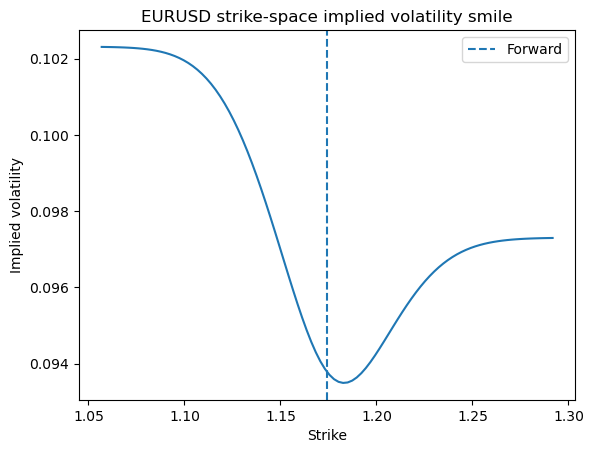

In [17]:
import numpy as np
import matplotlib.pyplot as plt

K_grid = np.linspace(F * 0.90, F * 1.10, 100)

vol_grid = np.array([
    rw_vol_for_strike(F, K, sigma_atm, rr, sigma_s, rf, tau)
    for K in K_grid
])

plt.figure()
plt.plot(K_grid, vol_grid)
plt.axvline(F, linestyle="--", label="Forward")
plt.title("EURUSD strike-space implied volatility smile")
plt.xlabel("Strike")
plt.ylabel("Implied volatility")
plt.legend()
plt.show()

In [18]:
#IMPORTANT  
#breeden litzenberger
#strike grid
K_grid = np.linspace(F*0.50, F*1.30, 801)

#Compute implied vols
vol_grid = np.array([rw_vol_for_strike(F, K, sigma_atm, rr, sigma_s, rf, tau) for K in K_grid])

#price calls
call_grid = np.array([gk_call(F, K, rd, vol, tau) for K, vol in zip(K_grid, vol_grid)])

#differentiation
dC_dK=np.gradient(call_grid, K_grid)
d2C_dK2=np.gradient(dC_dK, K_grid)

#breeden litzenberger formula
rnd=np.exp(rd*tau)*d2C_dK2

In [19]:
area = np.trapz(rnd, K_grid)

print("Area:", area)

print("Minimum density:", rnd.min())

print("Call decreasing:",
      np.all(np.diff(call_grid) <= 0))

print("Call convex:",
      np.all(d2C_dK2 >= -1e-8))

Area: 1.000000000000065
Minimum density: -1.335269912138911e-10
Call decreasing: True
Call convex: True


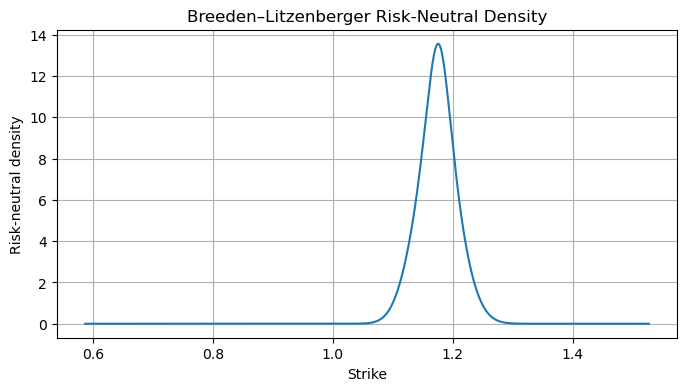

In [20]:
plt.figure(figsize=(8,4))
plt.plot(K_grid, rnd)
plt.xlabel("Strike")
plt.ylabel("Risk-neutral density")
plt.title("Breeden–Litzenberger Risk-Neutral Density")
plt.grid(True)
plt.show()

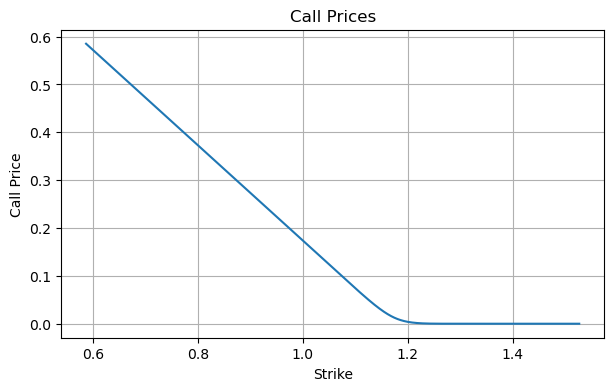

In [21]:
plt.figure(figsize=(7,4))
plt.plot(K_grid, call_grid)
plt.title("Call Prices")
plt.xlabel("Strike")
plt.ylabel("Call Price")
plt.grid(True)
plt.show()

In [22]:
area = np.trapz(rnd, K_grid)

left_tail_5 = np.trapz(
    rnd[K_grid < 0.95 * F],
    K_grid[K_grid < 0.95 * F]
)

left_tail_10 = np.trapz(
    rnd[K_grid < 0.90 * F],
    K_grid[K_grid < 0.90 * F]
)

area, left_tail_5, left_tail_10, rnd.min()

(1.000000000000065,
 0.036287757327476,
 0.00016631057924382678,
 -1.335269912138911e-10)

In [23]:
row = df[df["Pair"] == "EURUSD"].iloc[-100]

out = recover_rnd(
    F=row["Forward"],
    rd=row["rd"],
    rf=row["rf"],
    sigma_atm=row["ATM"],
    rr=row["rr25"],
    bf=row["bf25"],
    tau=1/12
)

checks = no_arbitrage_checks(out)
checks


{'vol_positive': True,
 'call_decreasing': True,
 'call_convex': True,
 'rnd_positive': True,
 'density_area_ok': True,
 'area': 1.0000000000000002,
 'min_density': -1.0440383590163927e-10,
 'min_call_second_derivative': -1.0402345651527867e-10,
 'passes_no_arb': True,
 'quality': 'PASS'}

In [24]:
df.tail(10)

,Date,Pair,Spot,ATM,rr25,bf25,rd,rf,Forward
43694,2025-12-15,USDSEK,9.2848,0.07690,0.002475,0.001800,0.017075,0.037550,9.268971
43695,2025-12-16,USDSEK,9.3033,0.07475,0.001650,0.001925,0.016750,0.038225,9.286666
43696,2025-12-17,USDSEK,9.3018,0.07310,0.001700,0.001850,0.016626,0.038450,9.284899
43697,2025-12-18,USDSEK,9.2840,0.07075,0.001550,0.001900,0.016600,0.038287,9.267237
43698,2025-12-19,USDSEK,9.2677,0.06825,0.001850,0.001850,0.016828,0.038200,9.251209
43699,2025-12-22,USDSEK,9.2352,0.07080,0.001925,0.001875,0.009500,0.038450,9.212947
43700,2025-12-23,USDSEK,9.1691,0.07315,0.001825,0.001975,0.012225,0.037850,9.149541
43701,2025-12-29,USDSEK,9.1824,0.08105,0.001750,0.001950,0.018775,0.037300,9.168236
43702,2025-12-30,USDSEK,9.1954,0.08015,0.001850,0.001950,0.017375,0.037050,9.180336
43703,2025-12-31,USDSEK,9.2108,0.07915,0.001850,0.001875,0.017475,0.036900,9.195902


In [25]:

K_grid = out["K"]
rnd = out["rnd"]

area = np.trapz(rnd, K_grid)
left_tail_5 = np.trapz(rnd[K_grid < 0.95 * row["Forward"]], K_grid[K_grid < 0.95 * row["Forward"]])
left_tail_10 = np.trapz(rnd[K_grid < 0.90 * row["Forward"]], K_grid[K_grid < 0.90 * row["Forward"]])

area, left_tail_5, left_tail_10, rnd.min()

(1.0000000000000002,
 0.013044294566550436,
 3.387261878119963e-06,
 -1.0440383590163927e-10)

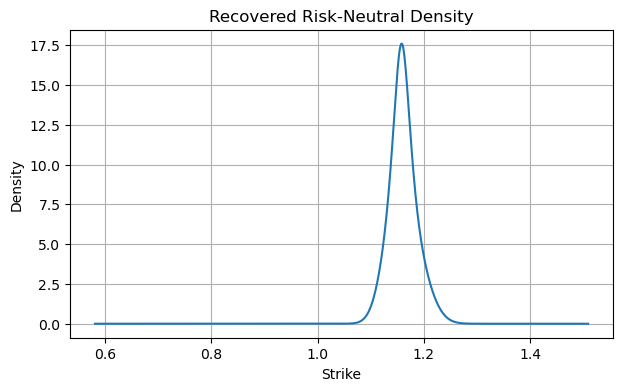

In [26]:
plt.figure(figsize=(7,4))
plt.plot(out["K"], out["rnd"])
plt.title("Recovered Risk-Neutral Density")
plt.xlabel("Strike")
plt.ylabel("Density")
plt.grid(True)
plt.show()

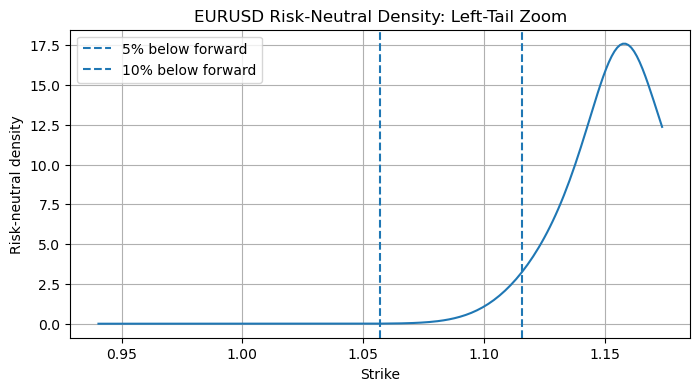

In [27]:
K = out["K"]
rnd = out["rnd"]

mask = (K >= 0.80 * F) & (K <= F)

plt.figure(figsize=(8, 4))
plt.plot(K[mask], rnd[mask])
plt.axvline(0.95 * F, linestyle="--", label="5% below forward")
plt.axvline(0.90 * F, linestyle="--", label="10% below forward")
plt.xlabel("Strike")
plt.ylabel("Risk-neutral density")
plt.title("EURUSD Risk-Neutral Density: Left-Tail Zoom")
plt.legend()
plt.grid(True)
plt.show()

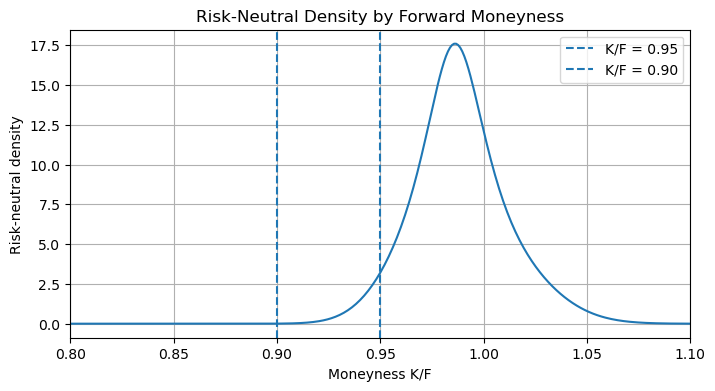

In [28]:
moneyness = out["K"] / F

plt.figure(figsize=(8, 4))
plt.plot(moneyness, out["rnd"])
plt.axvline(0.95, linestyle="--", label="K/F = 0.95")
plt.axvline(0.90, linestyle="--", label="K/F = 0.90")
plt.xlim(0.80, 1.10)
plt.xlabel("Moneyness K/F")
plt.ylabel("Risk-neutral density")
plt.title("Risk-Neutral Density by Forward Moneyness")
plt.legend()
plt.grid(True)
plt.show()

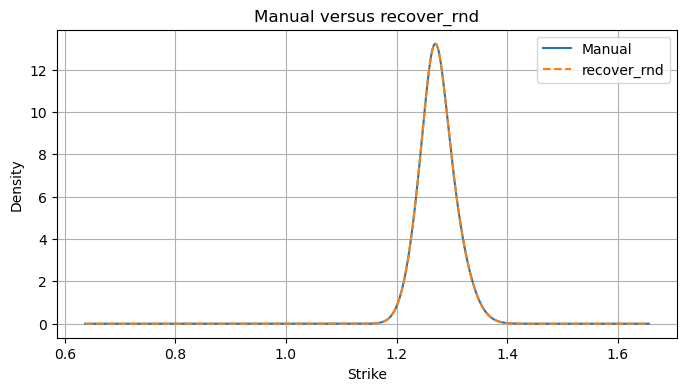

In [29]:
row = df[df["Pair"] == "EURUSD"].iloc[100]

F = row["Forward"]
rd = row["rd"]
rf = row["rf"]
sigma_atm = row["ATM"]
rr = row["rr25"]
bf = row["bf25"]
tau = 1 / 12

sigma_s, market_price, Kc, Kp, sigma_ms = calibrate_smile_strangle(
    F, rd, rf, sigma_atm, rr, bf, tau
)

# Manual calculation
K_manual = np.linspace(F * 0.50, F * 1.30, 801)

vol_manual = np.array([
    rw_vol_for_strike(
        F, K, sigma_atm, rr, sigma_s, rf, tau
    )
    for K in K_manual
])

call_manual = np.array([
    gk_call(F, K, rd, vol, tau)
    for K, vol in zip(K_manual, vol_manual)
])

rnd_manual = np.exp(rd * tau) * np.gradient(
    np.gradient(call_manual, K_manual),
    K_manual
)

# Wrapped calculation
out = recover_rnd(
    F=F,
    rd=rd,
    rf=rf,
    sigma_atm=sigma_atm,
    rr=rr,
    bf=bf,
    tau=tau
)

plt.figure(figsize=(8, 4))
plt.plot(K_manual, rnd_manual, label="Manual")
plt.plot(out["K"], out["rnd"], linestyle="--", label="recover_rnd")
plt.xlabel("Strike")
plt.ylabel("Density")
plt.title("Manual versus recover_rnd")
plt.legend()
plt.grid(True)
plt.show()

In [30]:
measures = rnd_tail_measure(out, row["Forward"])
measures

{'area': 1.0000000000017255,
 'mean': -0.00033116450571209183,
 'std': 0.025718792945064246,
 'skew': 0.1523755578421998,
 'kurt': 3.2376762317139334,
 'excess_kurt': 0.23767623171393337,
 'min_density': -7.283838882151425e-11,
 'q01': 1.2005876273445317,
 'q05': 1.2218727089640637,
 'VaR01': 0.05755216240496008,
 'VaR05': 0.04084361178485174,
 'ES01': 0.06560160760324307,
 'ES05': 0.05104647304832255,
 'ProbBelow95F': 0.021880010514506103,
 'ProbBelow90F': 1.7551584594343188e-05}

In [31]:
# #run on the whole dataset
# results = []
# errors = []
# for _,row in df.iterrows():
#     try:
#         out = recover_rnd(
#             F=row["Forward"],
#             rd=row["rd"],
#             rf=row["rf"],
#             sigma_atm=row["ATM"],
#             rr=row["rr25"],
#             bf=row["bf25"],
#             tau=1/12
#         )
#         measures = rnd_tail_measure(out, row["Forward"])
#         results.append({
#             "Date": row["Date"],
#             "Pair": row["Pair"],
#             **measures
#         })
#     except Exception as e:
#         errors.append({
#             "Date": row["Date"],
#             "Pair": row["Pair"],
#             "Error": str(e)
#         })

In [32]:
# results = []
# errors = []

# for _, row in df.iterrows():
#     try:
#         out = recover_left_tails_fast(
#             F=row["Forward"],
#             rd=row["rd"],
#             rf=row["rf"],
#             sigma_atm=row["ATM"],
#             rr=row["rr25"],
#             bf=row["bf25"],
#             tau=1/12
#         )

#         results.append({
#             "Date": row["Date"],
#             "Pair": row["Pair"],
#             "left_tail_5": out["left_tail_5"],
#             "left_tail_10": out["left_tail_10"],
#             "sigma_s": out["sigma_s"]
#         })

#     except Exception as e:
#         errors.append({
#             "Date": row["Date"],
#             "Pair": row["Pair"],
#             "Error": str(e)
#         })

# results_df = pd.DataFrame(results)
# errors_df = pd.DataFrame(errors)

# print(results_df)
# print(errors_df)

In [33]:
# results_df = pd.DataFrame(results)
# errors_df = pd.DataFrame(errors)


In [34]:
# print("Successful:", len(results_df))
# print("Failed:", len(errors_df))

# # results_df.head()
# errors_df.head()

In [35]:
# check_1 = (results_df["left_tail_10"] <= results_df["left_tail_5"]).all()
# check_2 = results_df["left_tail_5"].between(0, 1).all()
# check_3 = results_df["left_tail_10"].between(0, 1).all()

# print("Tail ordering correct:", check_1)
# print("5% tail probabilities valid:", check_2)
# print("10% tail probabilities valid:", check_3)

In [36]:
# bad_order = results_df[
#     results_df["left_tail_10"] > results_df["left_tail_5"]
# ]

# bad_tail_5 = results_df[
#     ~results_df["left_tail_5"].between(0, 1)
# ]

# bad_tail_10 = results_df[
#     ~results_df["left_tail_10"].between(0, 1)
# ]

# print("Bad ordering rows:", len(bad_order))
# print("Invalid 5% probabilities:", len(bad_tail_5))
# print("Invalid 10% probabilities:", len(bad_tail_10))

In [37]:
# for i in errors_df["Error"].unique():
#     print(i)

In [38]:
# results = []
# errors = []
# density_arrays = []
# density_metadata=[]

# for _, row in df.iterrows():
#     try:
#         out = recover_rnd(
#             F=row["Forward"],
#             rd=row["rd"],
#             rf=row["rf"],
#             sigma_atm=row["ATM"],
#             rr=row["rr25"],
#             bf=row["bf25"],
#             tau=1/12
#         )

#         measures = rnd_tail_measure(out, row["Forward"])
#         checks = no_arbitrage_checks(out)

#         results.append({
#             "Date": row["Date"],
#             "Pair": row["Pair"],
#             "log mean": measures["mean"],
#             "log std": measures["std"],
#             "log skew": measures["skew"],
#             "log kurt": measures["kurt"],
#             'log excess kurt': measures['excess_kurt'],
#             "area": measures["area"],
#             "min_density": measures["min_density"],
#             'q01':measures['q01'],
#             'q05':measures['q05'],
#             'VaR01':measures['VaR01'],
#             'VaR05':measures['VaR05'],
#             'ES01':measures['ES01'],
#             'ES05':measures['ES05'],
#             'ProbBelow95F':measures['ProbBelow95F'],
#             'ProbBelow90F':measures['ProbBelow90F'],
#             "quality": checks["quality"],
#             "sigma_s": out["sigma_s"]
#         })

#         density_arrays.append(np.asarray(out['rnd'],dtype=np.float32))
#         density_metadata.append({'Date':row['Date'],'Pair':row['Pair'],'Forward':row['Forward']})

#     except Exception as e:
#         errors.append({
#             "Date": row["Date"],
#             "Pair": row["Pair"],
#             "Error": str(e)
#         })

# results_df = pd.DataFrame(results)
# errors_df = pd.DataFrame(errors)

# density_matrix = np.vstack(density_arrays)
# moneyness_grid = np.linspace(0.5,1.3,density_matrix.shape[1]).astype(np.float32)
# np.savez_compressed('recovered_rnd_grids.npz',rnd=density_matrix,moneyness=moneyness_grid)
# density_metadata_df=pd.DataFrame(density_metadata)
# density_metadata_df.to_csv('recovered_rnd_metadata.csv', index = False)
# results_df.to_csv('final_option_implied_measures.csv', index=False) #THIS
# errors_df.to_csv("final_recovery_errors.csv",index = False)


# saved = np.load('recovered_rnd_grids.npz')
# rnd_matrix = saved['rnd']
# moneyness_grid=saved['moneyness']
# metadata = pd.read_csv('recovered_rnd_metadata.csv', parse_dates=['Date'])

In [39]:
results_df = pd.read_csv('final_option_implied_measures.csv',parse_dates=['Date'])

In [40]:

print(results_df)

            Date    Pair  log mean   log std  log skew  log kurt  \
0     2005-11-17  EURUSD -0.000354  0.026623 -0.140060  3.316391   
1     2005-11-18  EURUSD -0.000356  0.026696 -0.139702  3.315513   
2     2005-11-21  EURUSD -0.000383  0.027690 -0.097941  3.294896   
3     2005-11-22  EURUSD -0.000378  0.027513 -0.078561  3.243922   
4     2005-11-23  EURUSD -0.000379  0.027546 -0.098447  3.296598   
...          ...     ...       ...       ...       ...       ...   
43697 2025-12-22  USDSEK -0.000224  0.021182  0.086936  3.497577   
43698 2025-12-23  USDSEK -0.000240  0.021899  0.078761  3.505669   
43699 2025-12-29  USDSEK -0.000292  0.024166  0.067031  3.448159   
43700 2025-12-30  USDSEK -0.000286  0.023906  0.072227  3.454230   
43701 2025-12-31  USDSEK -0.000278  0.023588  0.073501  3.442345   

       log excess kurt  area   min_density       q01       q05     VaR01  \
0             0.316391   1.0 -6.057482e-11  1.100792  1.123885  0.064729   
1             0.315513   1.0 -6

In [41]:
# print(errors_df)

In [42]:
# assert (results_df["ES01"] >= results_df["VaR01"]).all()

# assert (results_df["ES05"] >= results_df["VaR05"]).all()

# assert (results_df["q01"] <= results_df["q05"]).all()

# assert (results_df["VaR01"] >= results_df["VaR05"]).all()

In [43]:
# plt.hist(results_df["skew"], bins=50)

In [44]:
# plt.hist(results_df["kurt"], bins=50)

In [45]:
# for i in np.random.choice(df.index, 10, replace=False):
#     row = df.loc[i]

#     out = recover_rnd(
#         row["Forward"],
#         row["rd"],
#         row["rf"],
#         row["ATM"],
#         row["rr25"],
#         row["bf25"],
#         1/12
#     )

#     plt.figure(figsize=(6,3))
#     plt.plot(out["K"], out["rnd"])
#     plt.axvline(row["Forward"], color="red")
#     plt.show()

In [46]:
# results_df.groupby("Pair")["skew"].describe() 

## Analysis

In [47]:
analysis = df.merge(results_df, on=['Date','Pair'],how='inner')

In [48]:
analysis.to_csv("final_option_implied.analysis.csv",index=False)

# Construct realised outcomes

In [49]:
raw_spot = pd.read_csv("raw_spot_for_realized_returns.csv")
raw_spot["Date"] = pd.to_datetime(raw_spot["Date"])

raw_spot.head()

,Date,Pair,Spot
0,2005-01-03,AUDUSD,0.7781
1,2005-01-04,AUDUSD,0.7649
2,2005-01-05,AUDUSD,0.7645
3,2005-01-06,AUDUSD,0.7608
4,2005-01-07,AUDUSD,0.7575


In [50]:
analysis = analysis.sort_values(['Pair','Date']).copy()
analysis['TargetDate_1M']=(analysis['Date']+pd.DateOffset(months=1))

spot_future = raw_spot.rename(
    columns={
        "Date":"RealisedDate_1M",
        "Spot":"Spot_1M_realised"
    }
)

analysis = analysis.sort_values(["Pair","Date"]).copy()

analysis["TargetDate_1M"] = (
    analysis["Date"] +
    pd.DateOffset(months=1)
)

matched_parts = []

for pair, group in analysis.groupby("Pair"):

    left = group.sort_values("TargetDate_1M")

    right = (
        spot_future
        .query("Pair == @pair")
        .drop(columns="Pair")
        .sort_values("RealisedDate_1M")
    )

    matched = pd.merge_asof(
        left,
        right,
        left_on="TargetDate_1M",
        right_on="RealisedDate_1M",
        direction="nearest",
        tolerance=pd.Timedelta(days=3)
    )

    matched_parts.append(matched)

analysis = (
    pd.concat(matched_parts)
      .sort_values(["Pair","Date"])
      .reset_index(drop=True)
)

In [51]:
analysis["realized_log_return_1M"] = np.log(
    analysis["Spot_1M_realised"] /
    analysis["Spot"]
)
analysis["realized_return_1M"] = (
    analysis["Spot_1M_realised"] / analysis["Spot"]
) - 1

# Evaluate the implied distribution

We have recovered 1-month risk-neutral distribution from option prices for every pair and date. Evaluating it means checking whetehr the future realised exchange rate behaves consistently with the probabilities implied by that distribution

Persistent different may reflect a tail-risk premium

We are evaluating whetehr the realised exchange rate fell into the distribution's left tail - aka realised exchange rate level fell below the option implied 1%/5% quantile

How often did realised exhcange rates fall below levels that the option market assigned only 1% or 5% probability?

In [52]:
analysis["breach_q01"] = (
    analysis["Spot_1M_realised"] < analysis["q01"]
).astype(int)

analysis["breach_q05"] = (
    analysis["Spot_1M_realised"] < analysis["q05"] #if the future spot falls below q05 the realised outcome entered the option-implie worst 5% region
).astype(int)

In [53]:
analysis[[
    "Spot_1M_realised",
    "realized_log_return_1M",
    "breach_q01",
    "breach_q05"
]].isna().sum()

Spot_1M_realised          153
realized_log_return_1M    153
breach_q01                  0
breach_q05                  0
dtype: int64

In [54]:
#realised available is iseful for ensuring missing terminal observations are excluded correctly
analysis["realised_available"] = (
    analysis["Spot_1M_realised"].notna()
)

In [55]:
analysis["below_q01"] = np.nan
analysis["below_q05"] = np.nan

valid = analysis["realised_available"]

analysis.loc[valid, "below_q01"] = (
    analysis.loc[valid, "Spot_1M_realised"]
    < analysis.loc[valid, "q01"]
).astype(int)

analysis.loc[valid, "below_q05"] = (
    analysis.loc[valid, "Spot_1M_realised"]
    < analysis.loc[valid, "q05"]
).astype(int)

Note that the above breach_q and below_q might be used later for risk-neutral tail exceedance / calibration test

In [56]:
tail_frequency = analysis.groupby("Pair").agg(
    valid_observations=("realised_available", "sum"),
    below_q01_count=("below_q01", "sum"),
    below_q01_frequency=("below_q01", "mean"),
    below_q05_count=("below_q05", "sum"),
    below_q05_frequency=("below_q05", "mean")
)

tail_frequency

#remmeber that below values come frim risk neutral dustributions (or at least q01 and q05) so the below might not actually signal certain mispricing but it culd simply be investors paying for an downside 'insurance'
#MIGHT USE IT IN THESIS

,valid_observations,below_q01_count,below_q01_frequency,below_q05_count,below_q05_frequency
Pair,,,,,
AUDUSD,4839,73.0,0.015086,219.0,0.045257
EURUSD,4839,39.0,0.008060,190.0,0.039264
GBPUSD,4839,55.0,0.011366,214.0,0.044224
NZDUSD,4839,44.0,0.009093,196.0,0.040504
USDCAD,4839,13.0,0.002687,172.0,0.035545
USDCHF,4839,75.0,0.015499,239.0,0.049390
USDJPY,4839,11.0,0.002273,113.0,0.023352
USDNOK,4839,39.0,0.008060,166.0,0.034305
USDSEK,4837,37.0,0.007649,184.0,0.038040


# VaR and ES

1 For each pair, produce summary statistics, time-series plot, crisis-period behavior, correlation with ATM vol and RR. 

## Distribution diagnostic

2 Look at log skew, excess kurt, VaR, ES - which currencies have fattest/smallest tails? Which become more negatively skewed during crises? How persistent are these measures

In [57]:
#summary stats by pair
vars = ['VaR01','VaR05']
es = ['ES01','ES05']
fat_tails = ['log skew','log excess kurt']
summary_stat_vars = (analysis.groupby('Pair')[vars].agg(['mean','std','median','min','max']))
summary_stat_vars

VaR01                                             VaR05            \
            mean       std    median       min       max      mean       std   
Pair                                                                           
AUDUSD  0.084556  0.032787  0.076344  0.039552  0.323145  0.058201  0.023030   
EURUSD  0.064995  0.025242  0.058184  0.025358  0.210165  0.044882  0.017448   
GBPUSD  0.068845  0.026355  0.060948  0.031896  0.241764  0.047299  0.018209   
NZDUSD  0.088894  0.031498  0.080358  0.041883  0.301281  0.061407  0.022011   
USDCAD  0.054879  0.021280  0.049148  0.025727  0.177037  0.038541  0.015205   
USDCHF  0.063958  0.020889  0.058730  0.030660  0.211639  0.044302  0.014668   
USDJPY  0.077178  0.027974  0.072517  0.034909  0.300313  0.052642  0.019328   
USDNOK  0.076512  0.021997  0.072678  0.038528  0.216030  0.054149  0.015912   
USDSEK  0.073229  0.022326  0.067757  0.041125  0.199658  0.051764  0.016172   

                                      
          median       min       max  
Pair                                  
AUDUSD  0.052427  0.026855  0.235823  
EURUSD  0.040151  0.017611  0.149265  
GBPUSD  0.041869  0.021885  0.169571  
NZDUSD  0.055494  0.028659  0.217586  
USDCAD  0.034361  0.017773  0.126412  
USDCHF  0.040625  0.021244  0.149441  
USDJPY  0.049415  0.023549  0.215646  
USDNOK  0.051297  0.026868  0.156873  
USDSEK  0.047795  0.028837  0.143252

In [58]:
summary_stat_es = (analysis.groupby('Pair')[es].agg(['mean','std','median','min','max']))
summary_stat_es

ES01                                              ES05            \
            mean       std    median       min       max      mean       std   
Pair                                                                           
AUDUSD  0.096458  0.036883  0.087271  0.045349  0.359413  0.074311  0.028996   
EURUSD  0.074239  0.028643  0.066554  0.028986  0.236855  0.057166  0.022220   
GBPUSD  0.078658  0.029829  0.069756  0.036553  0.272018  0.060462  0.023195   
NZDUSD  0.101349  0.035469  0.091823  0.048000  0.336254  0.078211  0.027813   
USDCAD  0.062617  0.024089  0.056175  0.029429  0.199967  0.048508  0.018927   
USDCHF  0.073055  0.023674  0.067161  0.035073  0.238621  0.056306  0.018474   
USDJPY  0.088195  0.031605  0.082923  0.040090  0.335383  0.067637  0.024621   
USDNOK  0.087120  0.024789  0.082838  0.044042  0.242776  0.067811  0.019634   
USDSEK  0.083408  0.025156  0.077257  0.047000  0.224981  0.064876  0.019937   

                                      
          median       min       max  
Pair                                  
AUDUSD  0.067010  0.034590  0.289163  
EURUSD  0.051134  0.022279  0.186497  
GBPUSD  0.053496  0.027975  0.213750  
NZDUSD  0.070663  0.036716  0.268751  
USDCAD  0.043378  0.022580  0.157354  
USDCHF  0.051667  0.026952  0.187469  
USDJPY  0.063543  0.030455  0.267425  
USDNOK  0.064364  0.033965  0.192997  
USDSEK  0.059981  0.036325  0.177722

In [59]:
summary_stat_fat_tails = (analysis.groupby('Pair')[fat_tails].agg(['mean','std','median','min','max']))
summary_stat_fat_tails

log skew                                         log excess kurt  \
            mean       std    median       min       max            mean   
Pair                                                                       
AUDUSD -0.384745  0.190124 -0.349575 -1.381062  0.071122        0.594929   
EURUSD -0.173028  0.246622 -0.176056 -1.150557  0.853600        0.511299   
GBPUSD -0.278363  0.203622 -0.260839 -1.370616  0.254434        0.561922   
NZDUSD -0.354174  0.171487 -0.313934 -1.311573  0.025624        0.536520   
USDCAD  0.245716  0.209582  0.208266 -0.304522  1.204092        0.554039   
USDCHF -0.089973  0.244109 -0.109583 -0.897652  0.566995        0.522595   
USDJPY -0.371460  0.297229 -0.362423 -1.680949  0.429873        0.778859   
USDNOK  0.240526  0.179891  0.242035 -0.243949  0.925062        0.493154   
USDSEK  0.226854  0.178205  0.223003 -0.438919  0.869711        0.488636   

                                                
             std    median       min       max  
Pair                                            
AUDUSD  0.283892  0.524515  0.086196  2.807726  
EURUSD  0.206404  0.484718  0.154954  2.461011  
GBPUSD  0.231488  0.522499  0.156255  2.680061  
NZDUSD  0.266157  0.467766  0.174077  2.692769  
USDCAD  0.269909  0.490239  0.000729  2.886791  
USDCHF  0.204705  0.500723  0.120319  2.379182  
USDJPY  0.352024  0.696288  0.168968  3.493215  
USDNOK  0.195740  0.440949  0.129665  1.688791  
USDSEK  0.182066  0.449580  0.109738  1.757510

AUDUSD, NZDUSD, USDJPY have persistent negative skew in their quoted-pair returns, where USDCAD, USDNOK, USDSEK have positive skew. 

But us uts important to realised that AUDUSD and USDNOK are quoted differently to the USD, meaning that is AUDUSD falls it means that AUD weakens against USD, and if USDNOK falls then NOK is strengthen against USD. In case you wan to to a pair-to-pair comparison, we'll need to ensure USD denominaiton. 


Positive excess kurtosis means that market assigns more probability to extreme outcomes than a Gaussian distribution does with the same variance.

Both skew and kurt both peak at crisis times (if supposedly USD denominated)

In [60]:
# #VaR and ES time sereis
# #start from one pair at a time with VaR01 and ES01
# for pair in analysis['Pair'].unique():
#     temp = (analysis[analysis['Pair']==pair].sort_values("Date"))
#     plt.figure(figsize=(12,5))
#     plt.plot(temp['Date'], temp['VaR01'], label  = 'VaR 1%')
#     plt.plot(temp['Date'], temp['ES01'],label = 'ES 1%')
#     plt. title(f'{pair}: Option-Implied 1% VaR and ES')
#     plt.xlabel('Date')
#     plt.ylabel('Loss relative to forward')
#     plt.legend()
#     plt.grid(True,alpha=0.3)
#     # plt.show()

In [61]:
# #VaR and ES time sereis
# #start from one pair at a time with VaR05 and ES05
# for pair in analysis['Pair'].unique():
#     temp = (analysis[analysis['Pair']==pair].sort_values("Date"))
#     plt.figure(figsize=(12,5))
#     plt.plot(temp['Date'], temp['VaR05'], label  = 'VaR 5%')
#     plt.plot(temp['Date'], temp['ES05'],label = 'ES 5%')
#     plt. title(f'{pair}: Option-Implied 5% VaR and ES')
#     plt.xlabel('Date')
#     plt.ylabel('Loss relative to forward')
#     plt.legend()
#     plt.grid(True,alpha=0.3)
#     # plt.show()

In [62]:
# #skewness and kurtosis through time
# for pair in analysis['Pair'].unique():
#     temp = analysis[analysis['Pair']==pair].sort_values('Date')
#     plt.figure(figsize=(12,5))
#     plt.plot(temp['Date'],temp['log skew'])
#     plt.axhline(0,linestyle='--',linewidth = 1)
#     plt.title(f'{pair}: Option-Implied Log-Return Skewness')
#     plt.xlabel('Date')
#     plt.ylabel('Skewness')
#     plt.grid(True,alpha=0.3)
#     # plt.show()

#     #skew = 0: approx symmetric distribution; skew<0: longer left tail, large negative moves are more likely in the quoted exchange rate; skew>0longer right tail, more likely large positive moves

In [63]:
# for pair in analysis['Pair'].unique():
#     temp = analysis[analysis['Pair']==pair].sort_values('Date')
#     plt.figure(figsize=(12,5))
#     plt.plot(temp['Date'],temp['log excess kurt'])
#     plt.axhline(0,linestyle='--',linewidth = 1)
#     plt.title(f'{pair}: Option-Implied Log-Return Kurtosis')
#     plt.xlabel('Date')
#     plt.ylabel('Kurtosis')
#     plt.grid(True,alpha=0.3)
#     # plt.show()

#     #gausian kurtosis = 0, but in our observation, each pair is heavy-tailed and more peaked than Gaussian

In [64]:
#corr with ATM, rr25 and bf25
corr_vars = ['VaR01','VaR05','ES01','ES05','log skew','log excess kurt','ATM','rr25','bf25'] #note that these values come from implied space
corr_overall = analysis[corr_vars].corr()
corr_overall.round(3) #REPORT!!!!!!!

,VaR01,VaR05,ES01,ES05,log skew,log excess kurt,ATM,rr25,bf25
VaR01,1.000,0.999,1.000,1.000,-0.338,0.284,0.960,-0.457,0.791
VaR05,0.999,1.000,0.998,0.999,-0.296,0.251,0.973,-0.418,0.778
ES01,1.000,0.998,1.000,1.000,-0.342,0.287,0.959,-0.460,0.792
ES05,1.000,0.999,1.000,1.000,-0.325,0.274,0.964,-0.445,0.787
log skew,-0.338,-0.296,-0.342,-0.325,1.000,-0.313,-0.087,0.925,-0.203
log excess kurt,0.284,0.251,0.287,0.274,-0.313,1.000,0.145,-0.339,0.636
ATM,0.960,0.973,0.959,0.964,-0.087,0.145,1.000,-0.200,0.736
rr25,-0.457,-0.418,-0.460,-0.445,0.925,-0.339,-0.200,1.000,-0.286
bf25,0.791,0.778,0.792,0.787,-0.203,0.636,0.736,-0.286,1.000


Strong correlate if VaR/ES and ATM: higher ATM implied vol broadens the distribution which pushes th elower quantiles furtehr into the tail. Also it shows that level of option-implied VaR and ES is drivenmostly by overall implied vol.  (if we later do any predictions and if VaR would be significant we might ask whether it contains more info beyond ATM)

Mild-to-strong corr of VaR/ES and bf: butterfly means more curvature/reacher wings relative to ATM which generally should produce more severe tail estimates. Greater smile curvature corresponds to greater option-implied tail thickness. 

Strong log skew and rr corr: rr encodes the difference between call and put wing volatilities, so it should be closely related to distributional assymetry. Recovered RND's skewness is behaving almost exactly as the risk-reversal quote implies it should. In case, call are much more expensive than puts -> positive rr -> market puts relatively more weights on upside; if puts are much more expensive than calls -> negative rr -> relatively more concern about downside

In [65]:
#corr per pair
pair_corr = {}
for pair in analysis['Pair'].unique():
    temp = analysis[analysis['Pair']==pair]
    pair_corr[pair]=(temp[corr_vars].corr().round(3))
pair_corr['EURUSD']

,VaR01,VaR05,ES01,ES05,log skew,log excess kurt,ATM,rr25,bf25
VaR01,1.000,0.999,1.000,1.000,-0.508,0.395,0.982,-0.639,0.845
VaR05,0.999,1.000,0.999,1.000,-0.482,0.366,0.988,-0.615,0.839
ES01,1.000,0.999,1.000,1.000,-0.512,0.398,0.981,-0.642,0.845
ES05,1.000,1.000,1.000,1.000,-0.501,0.386,0.984,-0.632,0.843
log skew,-0.508,-0.482,-0.512,-0.501,1.000,-0.500,-0.357,0.941,-0.315
log excess kurt,0.395,0.366,0.398,0.386,-0.500,1.000,0.266,-0.570,0.635
ATM,0.982,0.988,0.981,0.984,-0.357,0.266,1.000,-0.491,0.823
rr25,-0.639,-0.615,-0.642,-0.632,0.941,-0.570,-0.491,1.000,-0.434
bf25,0.845,0.839,0.845,0.843,-0.315,0.635,0.823,-0.434,1.000


In [66]:
pair_corr['AUDUSD']

,VaR01,VaR05,ES01,ES05,log skew,log excess kurt,ATM,rr25,bf25
VaR01,1.000,0.999,1.000,1.000,-0.526,0.423,0.980,-0.839,0.846
VaR05,0.999,1.000,0.998,0.999,-0.491,0.382,0.988,-0.819,0.824
ES01,1.000,0.998,1.000,1.000,-0.531,0.428,0.979,-0.841,0.848
ES05,1.000,0.999,1.000,1.000,-0.516,0.411,0.983,-0.833,0.839
log skew,-0.526,-0.491,-0.531,-0.516,1.000,-0.906,-0.364,0.858,-0.691
log excess kurt,0.423,0.382,0.428,0.411,-0.906,1.000,0.245,-0.759,0.761
ATM,0.980,0.988,0.979,0.983,-0.364,0.245,1.000,-0.725,0.749
rr25,-0.839,-0.819,-0.841,-0.833,0.858,-0.759,-0.725,1.000,-0.858
bf25,0.846,0.824,0.848,0.839,-0.691,0.761,0.749,-0.858,1.000


In [67]:
pair_corr['GBPUSD']

,VaR01,VaR05,ES01,ES05,log skew,log excess kurt,ATM,rr25,bf25
VaR01,1.000,0.999,1.000,1.000,-0.574,0.474,0.986,-0.823,0.852
VaR05,0.999,1.000,0.999,1.000,-0.549,0.443,0.991,-0.808,0.841
ES01,1.000,0.999,1.000,1.000,-0.578,0.477,0.986,-0.824,0.854
ES05,1.000,1.000,1.000,1.000,-0.567,0.465,0.988,-0.819,0.849
log skew,-0.574,-0.549,-0.578,-0.567,1.000,-0.756,-0.449,0.876,-0.509
log excess kurt,0.474,0.443,0.477,0.465,-0.756,1.000,0.338,-0.712,0.678
ATM,0.986,0.991,0.986,0.988,-0.449,0.338,1.000,-0.728,0.812
rr25,-0.823,-0.808,-0.824,-0.819,0.876,-0.712,-0.728,1.000,-0.674
bf25,0.852,0.841,0.854,0.849,-0.509,0.678,0.812,-0.674,1.000


In [68]:
pair_corr['NZDUSD']

,VaR01,VaR05,ES01,ES05,log skew,log excess kurt,ATM,rr25,bf25
VaR01,1.000,0.999,1.000,1.000,-0.600,0.496,0.981,-0.845,0.842
VaR05,0.999,1.000,0.999,0.999,-0.568,0.457,0.988,-0.825,0.822
ES01,1.000,0.999,1.000,1.000,-0.604,0.500,0.980,-0.846,0.844
ES05,1.000,0.999,1.000,1.000,-0.591,0.484,0.983,-0.839,0.836
log skew,-0.600,-0.568,-0.604,-0.591,1.000,-0.904,-0.444,0.896,-0.739
log excess kurt,0.496,0.457,0.500,0.484,-0.904,1.000,0.323,-0.794,0.817
ATM,0.981,0.988,0.980,0.983,-0.444,0.323,1.000,-0.732,0.747
rr25,-0.845,-0.825,-0.846,-0.839,0.896,-0.794,-0.732,1.000,-0.856
bf25,0.842,0.822,0.844,0.836,-0.739,0.817,0.747,-0.856,1.000


In [69]:
pair_corr['USDCAD']

,VaR01,VaR05,ES01,ES05,log skew,log excess kurt,ATM,rr25,bf25
VaR01,1.000,1.000,1.000,1.000,-0.095,-0.011,0.992,0.212,0.743
VaR05,1.000,1.000,1.000,1.000,-0.087,-0.016,0.994,0.220,0.737
ES01,1.000,1.000,1.000,1.000,-0.095,-0.010,0.992,0.212,0.744
ES05,1.000,1.000,1.000,1.000,-0.093,-0.013,0.993,0.215,0.741
log skew,-0.095,-0.087,-0.095,-0.093,1.000,0.836,0.007,0.900,0.376
log excess kurt,-0.011,-0.016,-0.010,-0.013,0.836,1.000,0.047,0.791,0.610
ATM,0.992,0.994,0.992,0.993,0.007,0.047,1.000,0.317,0.758
rr25,0.212,0.220,0.212,0.215,0.900,0.791,0.317,1.000,0.588
bf25,0.743,0.737,0.744,0.741,0.376,0.610,0.758,0.588,1.000


In [70]:
pair_corr['USDCHF']

,VaR01,VaR05,ES01,ES05,log skew,log excess kurt,ATM,rr25,bf25
VaR01,1.000,0.999,1.000,1.000,-0.039,0.126,0.974,-0.159,0.812
VaR05,0.999,1.000,0.998,0.999,0.001,0.090,0.983,-0.120,0.795
ES01,1.000,0.998,1.000,1.000,-0.043,0.130,0.973,-0.162,0.814
ES05,1.000,0.999,1.000,1.000,-0.026,0.115,0.977,-0.147,0.807
log skew,-0.039,0.001,-0.043,-0.026,1.000,-0.373,0.170,0.939,-0.074
log excess kurt,0.126,0.090,0.130,0.115,-0.373,1.000,0.001,-0.265,0.568
ATM,0.974,0.983,0.973,0.977,0.170,0.001,1.000,0.055,0.744
rr25,-0.159,-0.120,-0.162,-0.147,0.939,-0.265,0.055,1.000,-0.135
bf25,0.812,0.795,0.814,0.807,-0.074,0.568,0.744,-0.135,1.000


In [71]:
pair_corr['USDJPY']

,VaR01,VaR05,ES01,ES05,log skew,log excess kurt,ATM,rr25,bf25
VaR01,1.000,0.999,1.000,1.000,-0.460,0.276,0.971,-0.802,0.625
VaR05,0.999,1.000,0.999,0.999,-0.429,0.236,0.980,-0.783,0.606
ES01,1.000,0.999,1.000,1.000,-0.463,0.278,0.970,-0.803,0.627
ES05,1.000,0.999,1.000,1.000,-0.451,0.264,0.974,-0.797,0.620
log skew,-0.460,-0.429,-0.463,-0.451,1.000,-0.708,-0.264,0.839,-0.217
log excess kurt,0.276,0.236,0.278,0.264,-0.708,1.000,0.065,-0.611,0.535
ATM,0.971,0.980,0.970,0.974,-0.264,0.065,1.000,-0.648,0.562
rr25,-0.802,-0.783,-0.803,-0.797,0.839,-0.611,-0.648,1.000,-0.428
bf25,0.625,0.606,0.627,0.620,-0.217,0.535,0.562,-0.428,1.000


In [72]:
pair_corr['USDNOK']

,VaR01,VaR05,ES01,ES05,log skew,log excess kurt,ATM,rr25,bf25
VaR01,1.000,1.000,1.000,1.000,0.127,0.140,0.991,0.429,0.785
VaR05,1.000,1.000,1.000,1.000,0.137,0.140,0.993,0.439,0.781
ES01,1.000,1.000,1.000,1.000,0.127,0.141,0.991,0.429,0.786
ES05,1.000,1.000,1.000,1.000,0.130,0.140,0.992,0.432,0.784
log skew,0.127,0.137,0.127,0.130,1.000,0.853,0.241,0.898,0.456
log excess kurt,0.140,0.140,0.141,0.140,0.853,1.000,0.214,0.790,0.618
ATM,0.991,0.993,0.991,0.992,0.241,0.214,1.000,0.537,0.800
rr25,0.429,0.439,0.429,0.432,0.898,0.790,0.537,1.000,0.683
bf25,0.785,0.781,0.786,0.784,0.456,0.618,0.800,0.683,1.000


In [73]:
pair_corr['USDSEK']

,VaR01,VaR05,ES01,ES05,log skew,log excess kurt,ATM,rr25,bf25
VaR01,1.000,1.000,1.000,1.000,0.118,0.075,0.991,0.434,0.779
VaR05,1.000,1.000,1.000,1.000,0.131,0.075,0.993,0.445,0.773
ES01,1.000,1.000,1.000,1.000,0.118,0.076,0.991,0.434,0.780
ES05,1.000,1.000,1.000,1.000,0.122,0.075,0.992,0.438,0.777
log skew,0.118,0.131,0.118,0.122,1.000,0.801,0.233,0.910,0.379
log excess kurt,0.075,0.075,0.076,0.075,0.801,1.000,0.140,0.741,0.568
ATM,0.991,0.993,0.991,0.992,0.233,0.140,1.000,0.540,0.777
rr25,0.434,0.445,0.434,0.438,0.910,0.741,0.540,1.000,0.596
bf25,0.779,0.773,0.780,0.777,0.379,0.568,0.777,0.596,1.000


In [74]:
corr_summary = []

for pair, temp in analysis.groupby("Pair"):

    corr_summary.append({
        "Pair": pair,

        "VaR01_ATM":
            temp["VaR01"].corr(temp["ATM"]),

        "ES01_ATM":
            temp["ES01"].corr(temp["ATM"]),

        "VaR01_RR25":
            temp["VaR01"].corr(temp["rr25"]),

        "ES01_RR25":
            temp["ES01"].corr(temp["rr25"]),

        "Skew_RR25":
            temp["log skew"].corr(temp["rr25"]),

        "VaR01_BF25":
            temp["VaR01"].corr(temp["bf25"]),

        "Kurt_BF25":
            temp["log excess kurt"].corr(temp["bf25"])
    })

corr_summary = pd.DataFrame(corr_summary)

corr_summary.round(3)

,Pair,VaR01_ATM,ES01_ATM,VaR01_RR25,ES01_RR25,Skew_RR25,VaR01_BF25,Kurt_BF25
0,AUDUSD,0.980,0.979,-0.839,-0.841,0.858,0.846,0.761
1,EURUSD,0.982,0.981,-0.639,-0.642,0.941,0.845,0.635
2,GBPUSD,0.986,0.986,-0.823,-0.824,0.876,0.852,0.678
3,NZDUSD,0.981,0.980,-0.845,-0.846,0.896,0.842,0.817
4,USDCAD,0.992,0.992,0.212,0.212,0.900,0.743,0.610
5,USDCHF,0.974,0.973,-0.159,-0.162,0.939,0.812,0.568
6,USDJPY,0.971,0.970,-0.802,-0.803,0.839,0.625,0.535
7,USDNOK,0.991,0.991,0.429,0.429,0.898,0.785,0.618
8,USDSEK,0.991,0.991,0.434,0.434,0.910,0.779,0.568


ATM -> overall uncertainty (var, es)

RR-> smile assymetry (skew/assymetric tails)

BF-> smile curvature (kurtosis/tail thickness)

As we see from corr VaR01, VaR05, ES01, ES05 are extremely closely correlated so we do not need all of them for further analysis. Let break it doen into:
- main tail severity measure: VaR01 and ES01
- robustness: var05 and es05 (so analyse 1% measure and wheck whether 5% is similar to them in order to conclude the robustness to the choice of tail threshold)
- log skew and log excess kurt (as separate shape dimension different from var and es)

For stress scenarios, rather than asking the directional changes (signs) (which depend on the currency denomination), ask whether the magnitude/severity of option-implied tail risk increase during the crisis?

Remember, thst atm, rr and bf are inputs to the recondtructed rnd. The above was primarily consucted for sanity check and to see the drivers of tail measure 

# Create historical realized quantities
Previoys option-implied VaR and ES measures were expressed as losses relative to the forward, so we will keep the same reference for consistency. 

In [75]:
#the physica-realised ratio measures how the future spot performed relative to today's forward price
#note that ln(St+1/St) (ordinary FX returns): what does the historic distribution  of one-month percentage excanges look like?
#ln(St+1/Ft) (foreward-relative/excess return): how has the currency historically performed relative to the return implied by the forward contract?
analysis['realised_forward_ratio']=(analysis['Spot_1M_realised']/analysis['Forward']) #e.g., if it equals 95, then exchange rate finished 5% below the forward
analysis['realised_forward_log_return']=np.log(analysis['realised_forward_ratio'])

In [76]:
analysis[['Date','Pair','Spot','Forward','Spot_1M_realised','realized_log_return_1M','realised_forward_log_return']].head()
#ln(St+1/St)=exchange rate change - what happen to FX
#ln(St+1/F)=forward related currency excess return - for risk premium interpretation

,Date,Pair,Spot,Forward,Spot_1M_realised,realized_log_return_1M,realised_forward_log_return
0,2005-11-17,AUDUSD,0.7338,0.732969,0.7437,0.013401,0.014535
1,2005-11-18,AUDUSD,0.7333,0.732466,0.7401,0.009230,0.010368
2,2005-11-21,AUDUSD,0.7361,0.735254,0.7333,-0.003811,-0.002661
3,2005-11-22,AUDUSD,0.7376,0.736804,0.7315,-0.008304,-0.007225
4,2005-11-23,AUDUSD,0.7377,0.736892,0.7290,-0.011864,-0.010768


the forward-relative return would be useful later when testing whether tail risk gap predicts currency excess returns -> gap premium test**

The option implied VaR currencyly uses 1-q/F while a physical distribution based on spot returns

To contiue with analysis and to ensure that impked and realised measures are comparable, recalculate VaR to log VaR:

# Implie transformation into the log-return space as in realised returns

For the estimatoin of quantiles and risk measire for realised rates, we are using historical data of exchange rate. such as its histogram would be sort of a distribution. And for qunatiles we do not really need the whole pdf or other simulation so we do not overcomplicate and overrely on models. for risk metrics and further asesment we will look only at the log returns

Before comparing any risk metrics we still have to account for the log transformation for option-implied outcomes so we can compare apples-to-apples. We do it so we can recalculate VaR and ES using our saved strike grid and density. For each implied distribution we want x = log(K/F_t) where K is the grid of possible future S_T (possible terminal exchange rate under risk-neutral measure). Remember that for realised observations we had x = log(S_T/F_t). 

# Additionally

As we have seen so far currency pair notaion is important so looking at the left hand side tail might not be the most accurate since there is no universal FX loss direction since it depends on whether you are a buyer or a seller. So it is also worth calculating the right sight risk measures. 
Later when looking at the risk metrics based on VIX regimes, it is best to convert every pair to USD direction

In [77]:
import numpy as np
grids = np.load('recovered_rnd_grids.npz',allow_pickle=True)


In [78]:
rnd = grids['rnd']
moneyness = grids['moneyness']
test = implied_log_tail_measure(moneyness, rnd[0])
print(test)

(0.06691857766791923, 0.04615720103179119, 0.0615980714286606, 0.042761584697697474, 0.07683203795404636, 0.058854156260480045, 0.07074544736754233, 0.05427246797745106)


In [79]:
metadata = pd.read_csv(
    "recovered_rnd_metadata.csv"
)

In [80]:
#now run all distributions to get log implied variables
results = []
for density in rnd:
    result = implied_log_tail_measure(moneyness, density)
    results.append(result)
results = np.asarray(results)
log_tail = pd.DataFrame(results, columns = ['VaR01_L_Q_log','VaR05_L_Q_log','VaR01_R_Q_log', 'VaR05_R_Q_log', 'ES01_L_Q_log','ES05_L_Q_log', 'ES01_R_Q_log', 'ES05_R_Q_log'])
print(log_tail.head())
print(log_tail.shape)

   VaR01_L_Q_log  VaR05_L_Q_log  VaR01_R_Q_log  VaR05_R_Q_log  ES01_L_Q_log  \
0       0.066919       0.046157       0.061598       0.042762      0.076832   
1       0.067086       0.046281       0.061763       0.042877      0.077033   
2       0.068795       0.047593       0.064692       0.044849      0.078955   
3       0.067664       0.046994       0.064235       0.044654      0.077619   
4       0.068451       0.047350       0.064364       0.044619      0.078573   

   ES05_L_Q_log  ES01_R_Q_log  ES05_R_Q_log  
0      0.058854      0.070745      0.054272  
1      0.059003      0.070938      0.054422  
2      0.060552      0.074324      0.056984  
3      0.059636      0.073764      0.056624  
4      0.060253      0.073939      0.056687  
(43702, 8)


In [81]:
metadata['Date'] = pd.to_datetime(metadata['Date'])
log_tail = pd.concat([metadata.reset_index(drop=True),log_tail],axis=1)
log_tail.head()

,Date,Pair,Forward,VaR01_L_Q_log,VaR05_L_Q_log,VaR01_R_Q_log,VaR05_R_Q_log,ES01_L_Q_log,ES05_L_Q_log,ES01_R_Q_log,ES05_R_Q_log
0,2005-11-17,EURUSD,1.176976,0.066919,0.046157,0.061598,0.042762,0.076832,0.058854,0.070745,0.054272
1,2005-11-18,EURUSD,1.179327,0.067086,0.046281,0.061763,0.042877,0.077033,0.059003,0.070938,0.054422
2,2005-11-21,EURUSD,1.174319,0.068795,0.047593,0.064692,0.044849,0.078955,0.060552,0.074324,0.056984
3,2005-11-22,EURUSD,1.183257,0.067664,0.046994,0.064235,0.044654,0.077619,0.059636,0.073764,0.056624
4,2005-11-23,EURUSD,1.184129,0.068451,0.047350,0.064364,0.044619,0.078573,0.060253,0.073939,0.056687


Now merge these into the genera; analysis dataframe

In [82]:
analysis['Date']=pd.to_datetime(analysis['Date'])
log_tail['Date']=pd.to_datetime(log_tail['Date'])
analysis=analysis.merge(log_tail[['Date','Pair','VaR01_L_Q_log','VaR05_L_Q_log','VaR01_R_Q_log', 'VaR05_R_Q_log', 'ES01_L_Q_log','ES05_L_Q_log', 'ES01_R_Q_log', 'ES05_R_Q_log']],on=['Date','Pair'],how = 'left')
analysis[['Date','Pair','VaR01_L_Q_log','VaR05_L_Q_log','VaR01_R_Q_log', 'VaR05_R_Q_log', 'ES01_L_Q_log','ES05_L_Q_log', 'ES01_R_Q_log', 'ES05_R_Q_log']].head()
# analysis[['VaR01_Q_log','VaR05_Q_log','ES01_Q_log','ES05_Q_log']].isna().sum()

,Date,Pair,VaR01_L_Q_log,VaR05_L_Q_log,VaR01_R_Q_log,VaR05_R_Q_log,ES01_L_Q_log,ES05_L_Q_log,ES01_R_Q_log,ES05_R_Q_log
0,2005-11-17,AUDUSD,0.067149,0.046033,0.058303,0.040675,0.077166,0.058955,0.066937,0.051448
1,2005-11-18,AUDUSD,0.065449,0.044870,0.057274,0.039908,0.075193,0.057453,0.065762,0.050521
2,2005-11-21,AUDUSD,0.065693,0.045192,0.058475,0.040757,0.075442,0.057726,0.067128,0.051583
3,2005-11-22,AUDUSD,0.064999,0.044756,0.058442,0.040693,0.074657,0.057134,0.067100,0.051538
4,2005-11-23,AUDUSD,0.065510,0.044965,0.057977,0.040356,0.075252,0.057531,0.066562,0.051125


In [83]:
print(analysis.columns)

Index(['Date', 'Pair', 'Spot', 'ATM', 'rr25', 'bf25', 'rd', 'rf', 'Forward',
       'log mean', 'log std', 'log skew', 'log kurt', 'log excess kurt',
       'area', 'min_density', 'q01', 'q05', 'VaR01', 'VaR05', 'ES01', 'ES05',
       'ProbBelow95F', 'ProbBelow90F', 'quality', 'sigma_s', 'TargetDate_1M',
       'RealisedDate_1M', 'Spot_1M_realised', 'realized_log_return_1M',
       'realized_return_1M', 'breach_q01', 'breach_q05', 'realised_available',
       'below_q01', 'below_q05', 'realised_forward_ratio',
       'realised_forward_log_return', 'VaR01_L_Q_log', 'VaR05_L_Q_log',
       'VaR01_R_Q_log', 'VaR05_R_Q_log', 'ES01_L_Q_log', 'ES05_L_Q_log',
       'ES01_R_Q_log', 'ES05_R_Q_log'],
      dtype='object')


In [84]:
risk_data = analysis[['Date','Pair','RealisedDate_1M','realised_forward_log_return','VaR01_L_Q_log','VaR05_L_Q_log','VaR01_R_Q_log', 'VaR05_R_Q_log', 'ES01_L_Q_log','ES05_L_Q_log', 'ES01_R_Q_log', 'ES05_R_Q_log','log skew', 'log excess kurt']].copy()
risk_data = risk_data.dropna(subset = ['realised_forward_log_return'])

In [85]:
#full sample physical distribution by pair
full_sample_P = (risk_data.groupby('Pair')['realised_forward_log_return'].apply(empirical_risk_measures).unstack())
full_sample_P

,VaR01_L_P,VaR05_L_P,VaR01_R_P,VaR05_R_P,ES01_L_P,ES05_L_P,ES01_R_P,ES05_R_P,skew_P,excess_kurt_P,n_obs
Pair,,,,,,,,,,,
AUDUSD,0.099858,0.053925,0.082749,0.051703,0.145319,0.083703,0.097340,0.070548,-0.971135,6.639342,4839.0
EURUSD,0.070634,0.041250,0.065943,0.039496,0.087275,0.060000,0.080187,0.055086,-0.123601,2.186661,4839.0
GBPUSD,0.083950,0.042812,0.057903,0.035918,0.110061,0.067539,0.072410,0.049327,-0.776890,3.249224,4839.0
NZDUSD,0.095343,0.056662,0.084380,0.055079,0.121432,0.080567,0.109110,0.073961,-0.215183,2.226972,4839.0
USDCAD,0.054453,0.034083,0.062252,0.035915,0.067699,0.046765,0.097081,0.056392,0.917048,7.617509,4839.0
USDCHF,0.082421,0.043228,0.070562,0.040613,0.099502,0.065180,0.099508,0.060571,0.041666,3.781362,4839.0
USDJPY,0.068692,0.045124,0.073149,0.049387,0.082415,0.060138,0.085389,0.064241,-0.061916,0.889771,4839.0
USDNOK,0.071998,0.051798,0.093394,0.053688,0.081613,0.064327,0.131092,0.082325,0.681397,3.335857,4839.0
USDSEK,0.076302,0.049986,0.080969,0.053724,0.096962,0.067717,0.107041,0.072724,0.117949,1.762975,4837.0


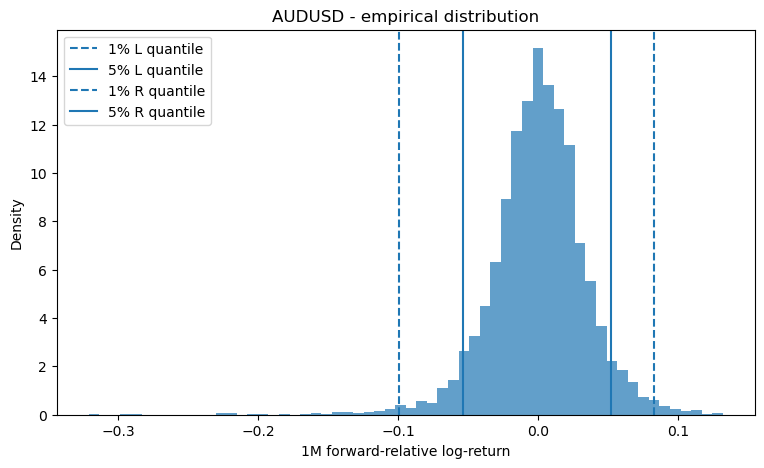

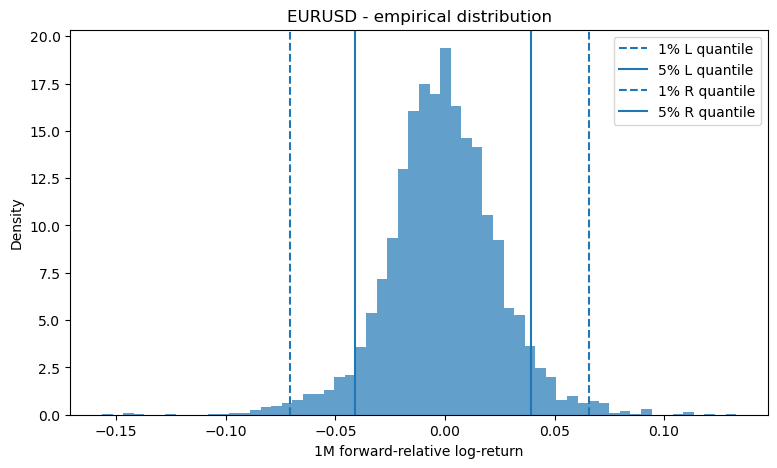

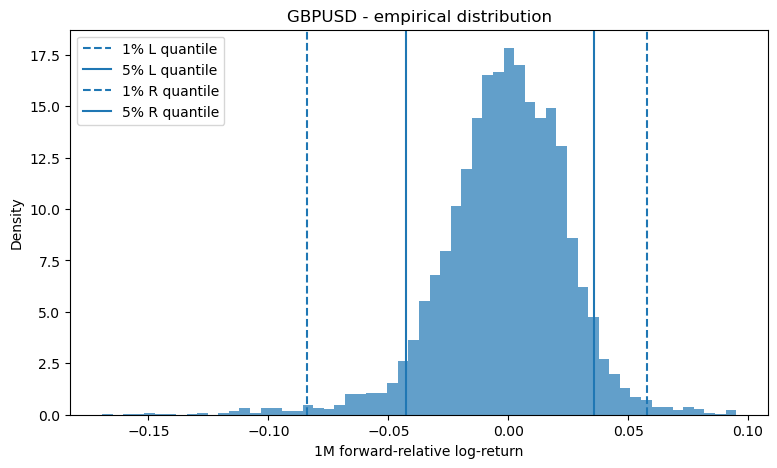

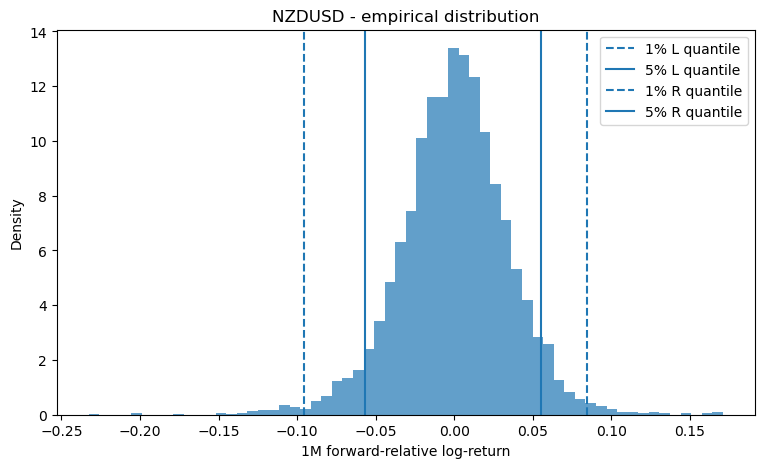

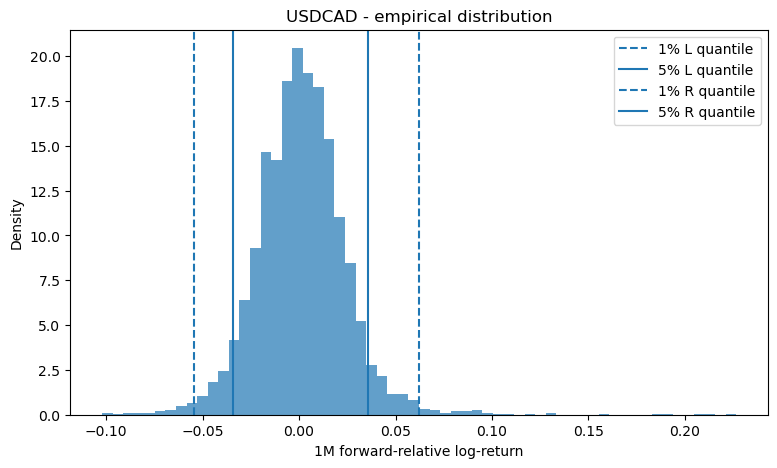

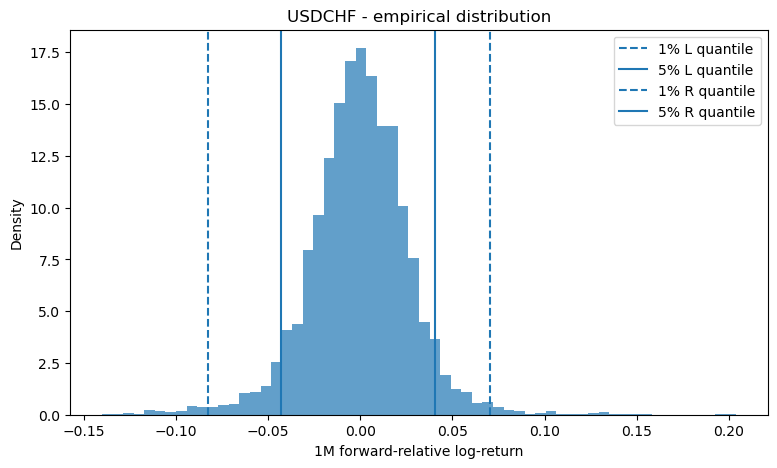

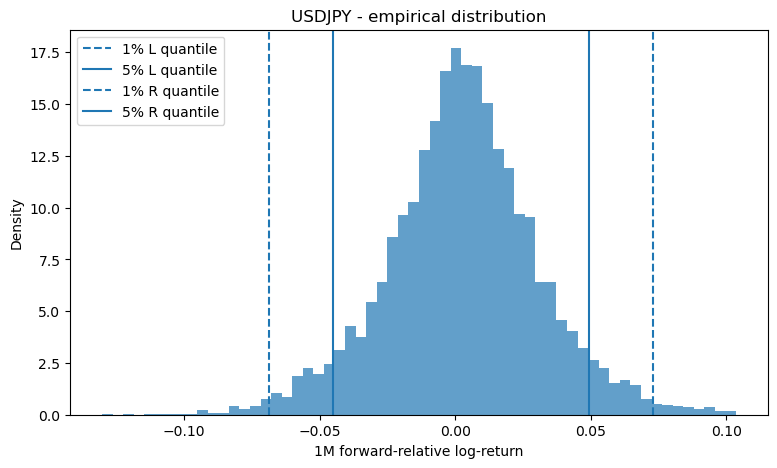

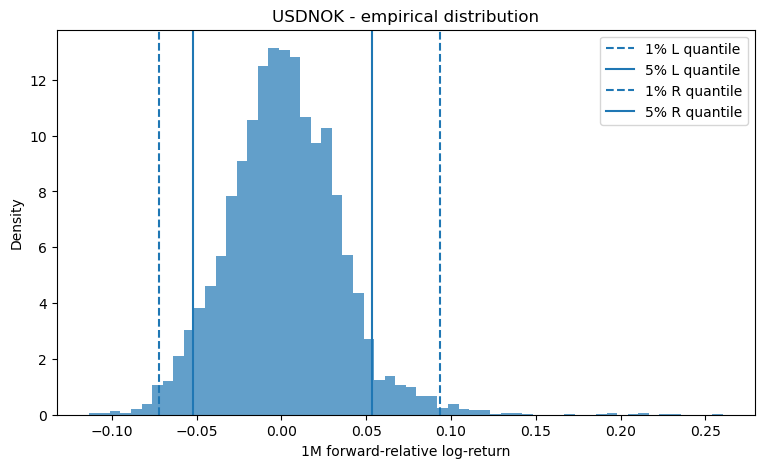

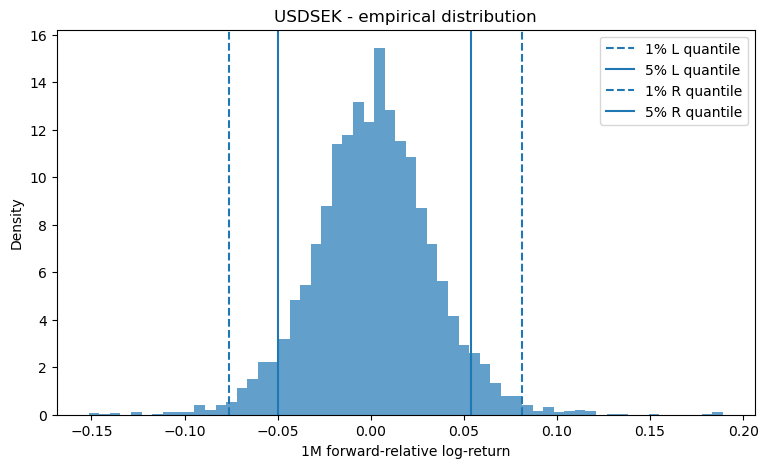

In [86]:
#plot raw distributions
import matplotlib.pyplot as plt
for pair in risk_data['Pair'].unique():
    x = risk_data.loc[risk_data['Pair']==pair, 'realised_forward_log_return'].dropna()
    plt.figure(figsize = (9,5))
    plt.hist(x,bins = 60, density = True, alpha = 0.7)
    plt.axvline(x.quantile(0.01),linestyle = '--', label = '1% L quantile')
    plt.axvline(x.quantile(0.05),linestyle = '-', label = '5% L quantile')
    plt.axvline(x.quantile(0.99), linestyle = '--', label = '1% R quantile')
    plt.axvline(x.quantile(0.95),linestyle = '-', label = '5% R quantile')
    plt.title(f'{pair} - empirical distribution')
    plt.xlabel('1M forward-relative log-return')
    plt.ylabel('Density')
    plt.legend()
    plt.show()

In [87]:
#full sample physical distribution by year
risk_data['Year']=(pd.to_datetime(risk_data['RealisedDate_1M']).dt.year)

annual_P = (risk_data.groupby(['Pair','Year'])['realised_forward_log_return'].apply(empirical_risk_measures).unstack().reset_index())
annual_P.head()

,Pair,Year,VaR01_L_P,VaR05_L_P,VaR01_R_P,VaR05_R_P,ES01_L_P,ES05_L_P,ES01_R_P,ES05_R_P,skew_P,excess_kurt_P,n_obs
0,AUDUSD,2005,0.015547,0.013885,0.014201,0.012868,0.015963,0.015963,0.014535,0.014535,1.028099,0.348210,9.0
1,AUDUSD,2006,0.042838,0.033869,0.072214,0.053151,0.045953,0.039634,0.074397,0.063157,0.325587,0.104069,228.0
2,AUDUSD,2007,0.090054,0.054969,0.078414,0.053619,0.095423,0.076502,0.082512,0.066718,-0.351941,0.514643,182.0
3,AUDUSD,2008,0.264844,0.160893,0.083381,0.052615,0.300915,0.224133,0.095251,0.070845,-1.535983,2.727134,239.0
4,AUDUSD,2009,0.085913,0.045499,0.115703,0.105378,0.100646,0.065385,0.125801,0.113160,-0.185505,-0.044527,245.0


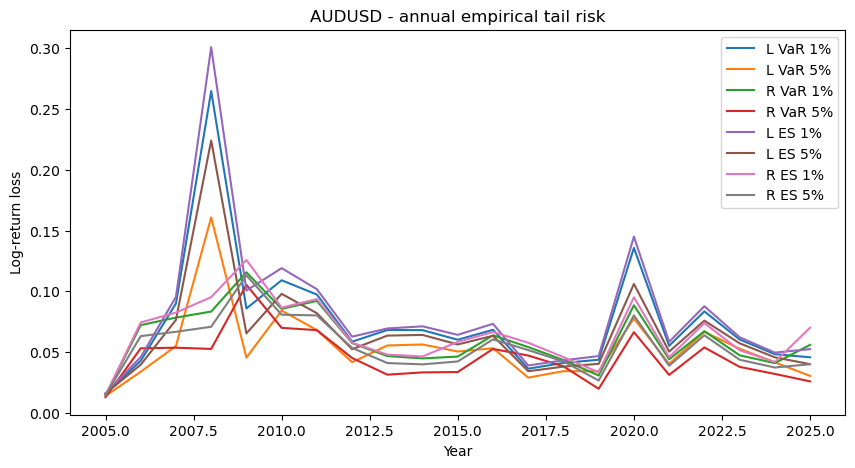

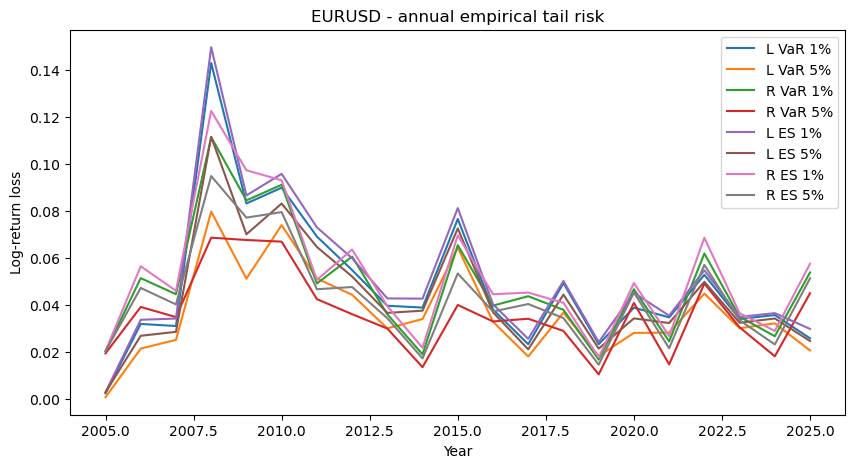

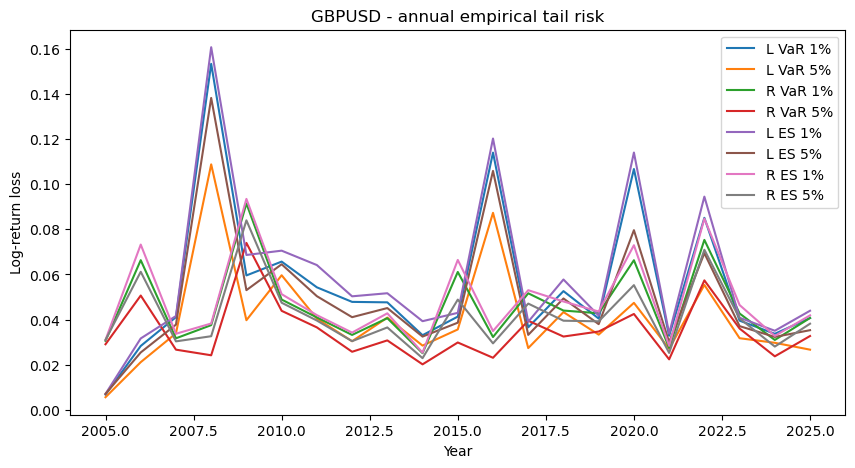

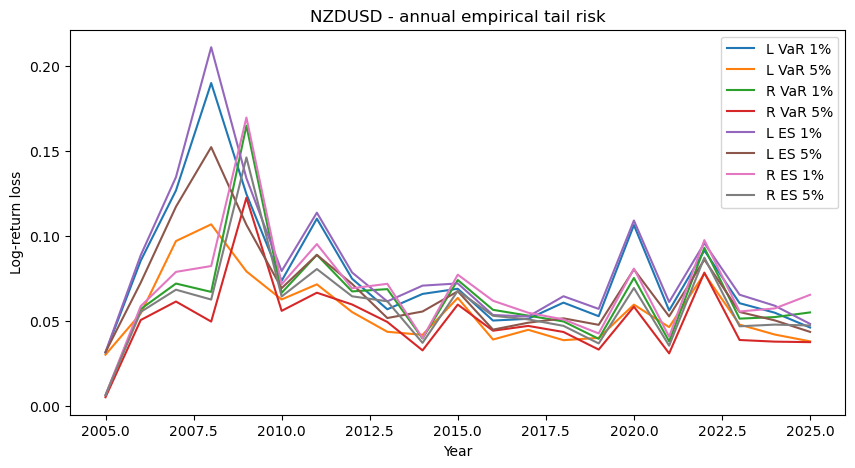

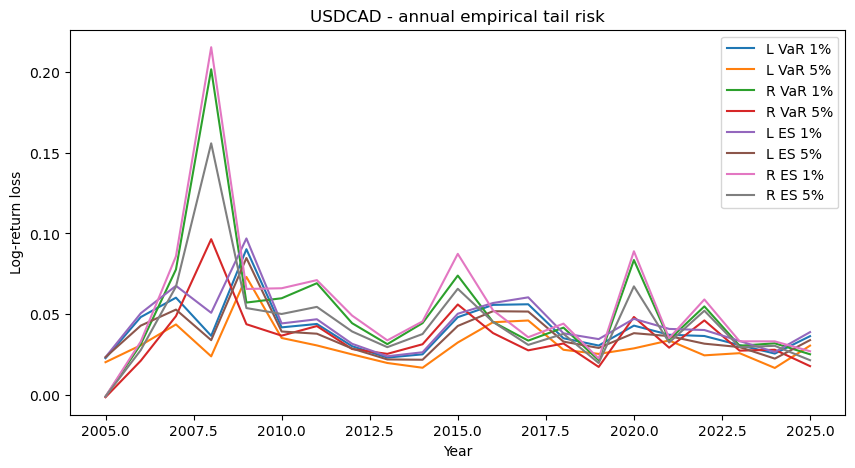

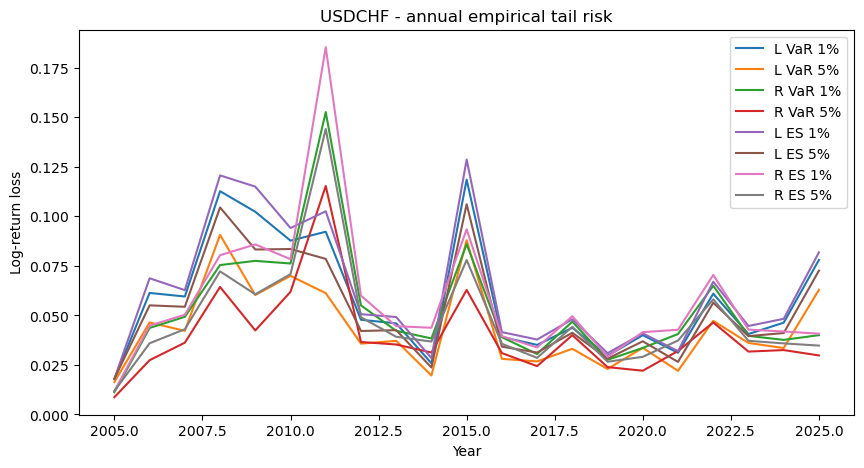

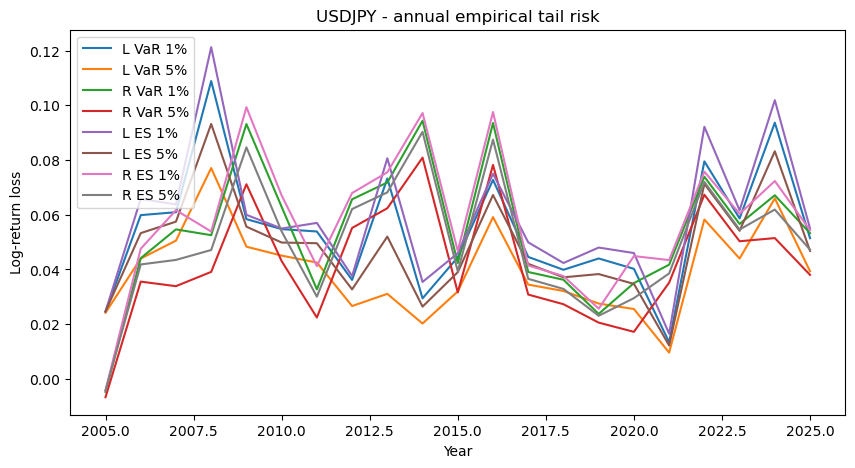

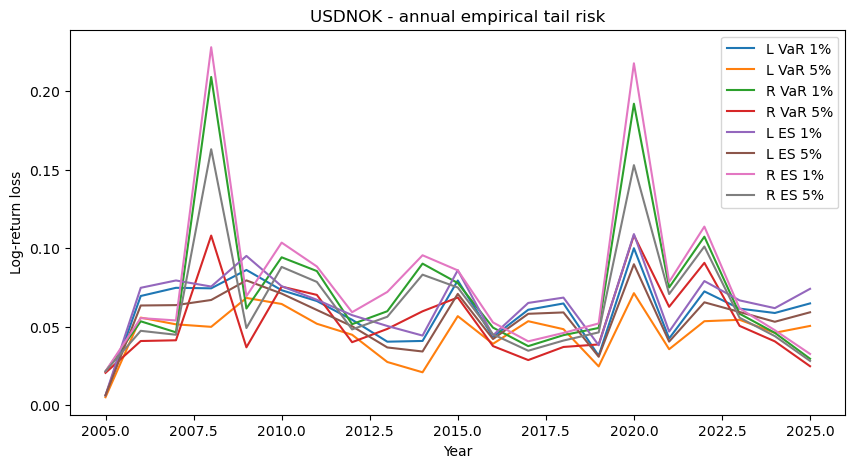

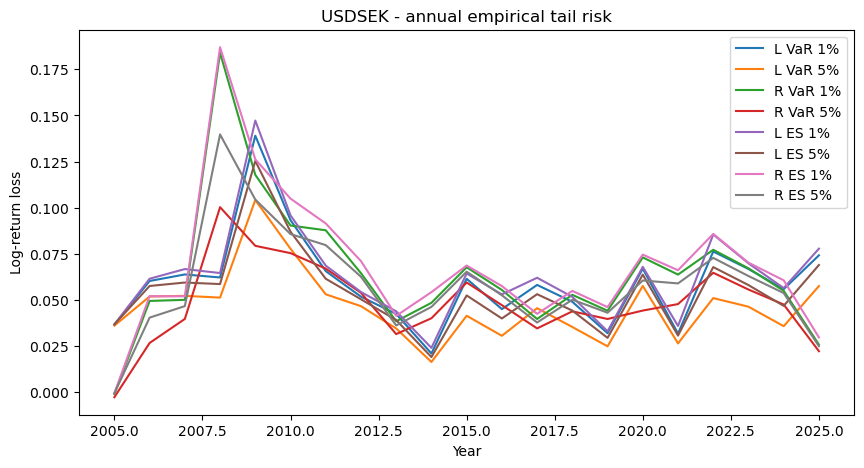

In [88]:
#plot how physical risk changes by year
for pair in annual_P['Pair'].unique():
    temp = annual_P[annual_P['Pair']==pair].sort_values('Year')
    plt.figure(figsize = (10,5))
    plt.plot(temp['Year'], temp['VaR01_L_P'], label = 'L VaR 1%')
    plt.plot(temp['Year'], temp['VaR05_L_P'], label = 'L VaR 5%')
    plt.plot(temp['Year'], temp['VaR01_R_P'], label = 'R VaR 1%')
    plt.plot(temp['Year'], temp['VaR05_R_P'], label = 'R VaR 5%')
    plt.plot(temp['Year'], temp['ES01_L_P'], label = 'L ES 1%')
    plt.plot(temp['Year'], temp['ES05_L_P'], label = 'L ES 5%')
    plt.plot(temp['Year'], temp['ES01_R_P'], label = 'R ES 1%')
    plt.plot(temp['Year'], temp['ES05_R_P'], label = 'R ES 5%')

    plt.title(f'{pair} - annual empirical tail risk')
    plt.xlabel('Year')
    plt.ylabel('Log-return loss')
    plt.legend()
    plt.show()

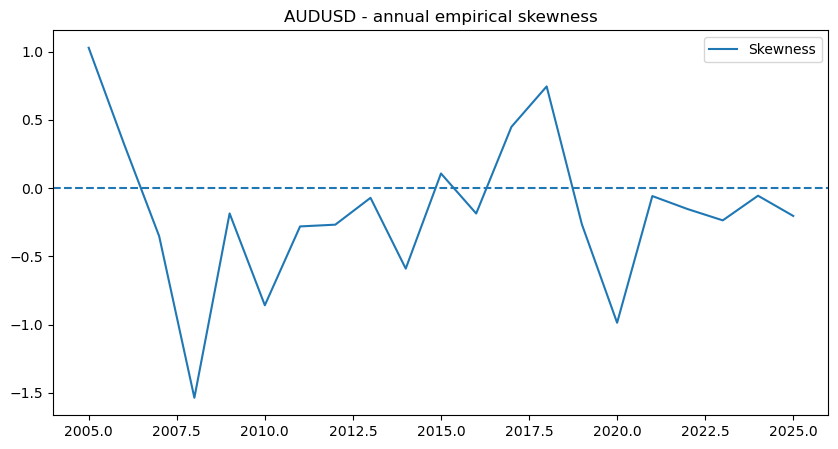

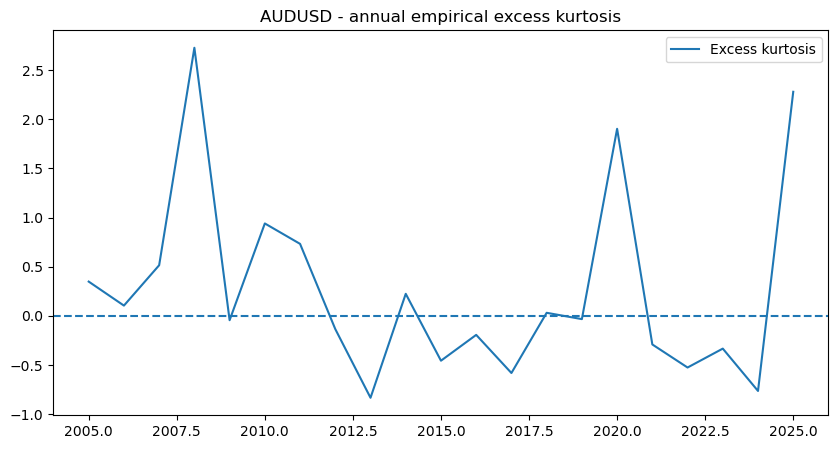

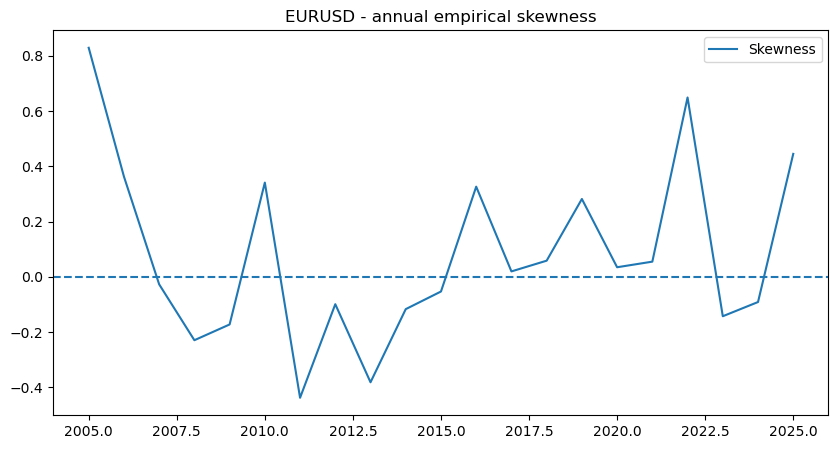

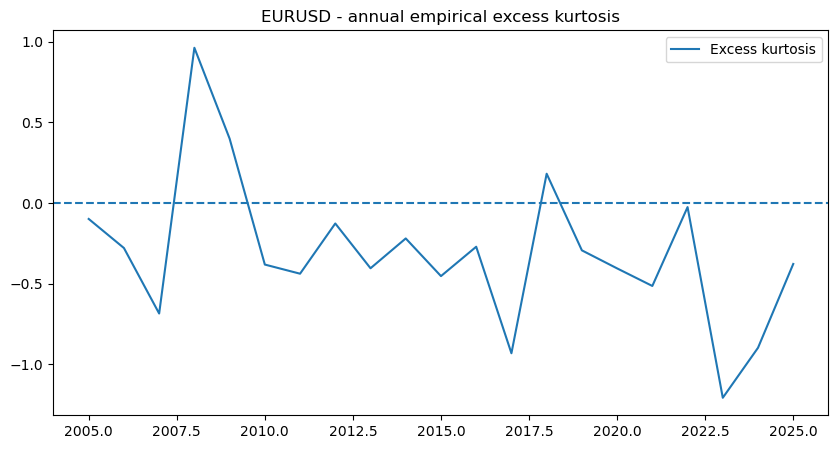

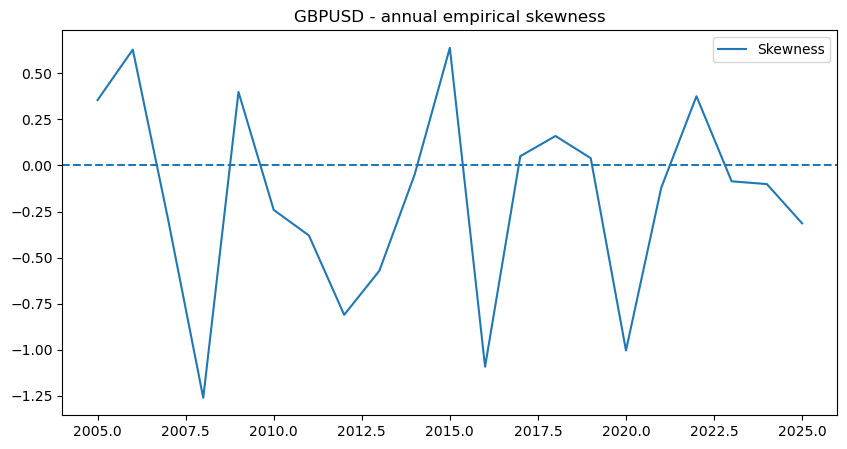

...

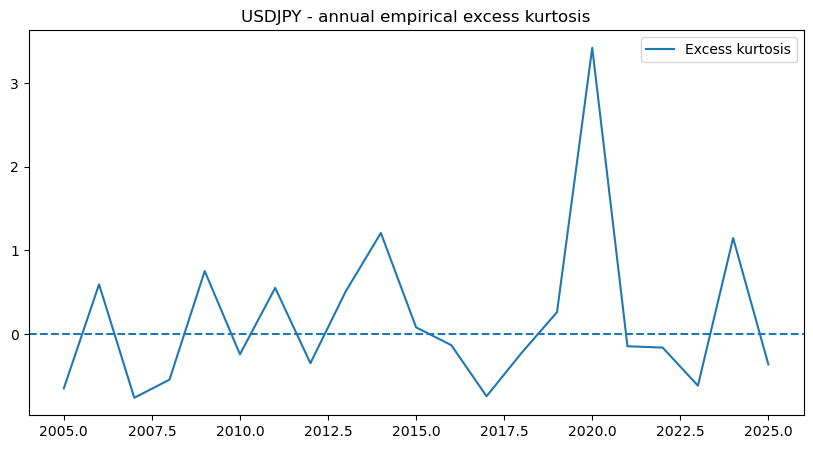

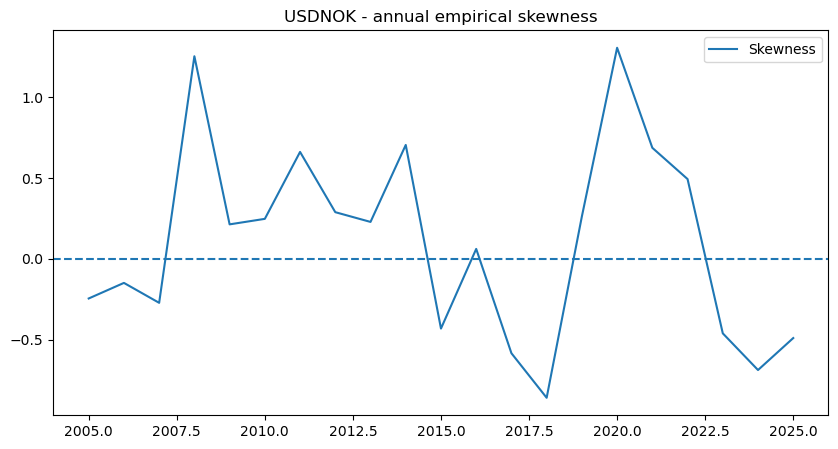

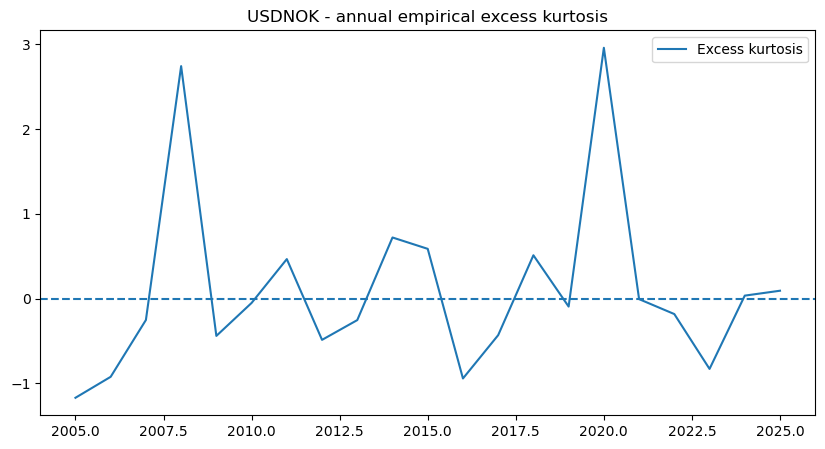

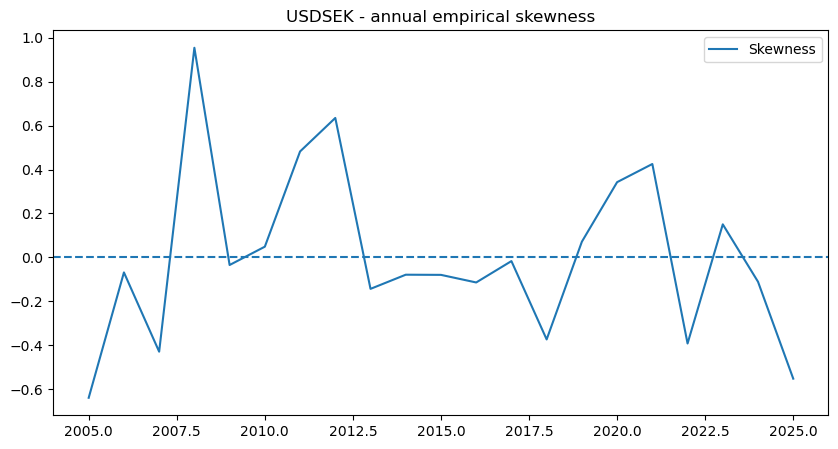

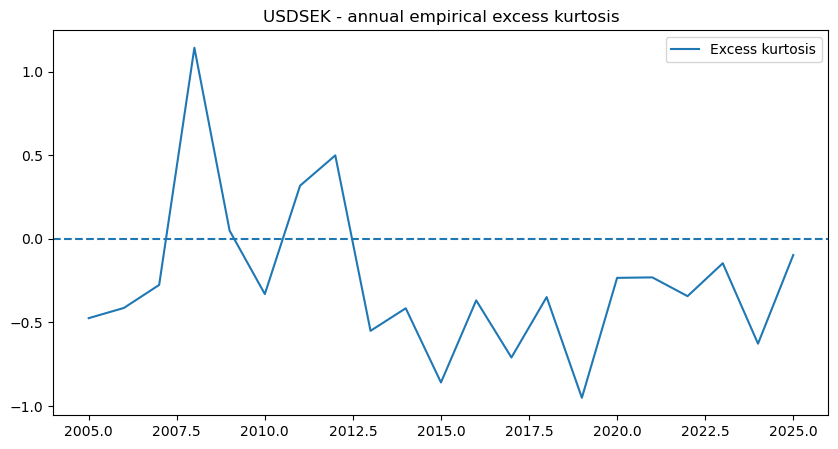

In [89]:
#plot how physical moments changes by year
for pair in annual_P['Pair'].unique():
    temp = annual_P[annual_P['Pair']==pair].sort_values('Year')
    plt.figure(figsize = (10,5))
    plt.plot(temp['Year'], temp['skew_P'], label = 'Skewness')
    plt.axhline(0,linestyle = '--')
    plt.title(f'{pair} - annual empirical skewness')
    plt.legend()
    plt.show()

    plt.figure(figsize=(10,5))
    plt.plot(temp['Year'], temp['excess_kurt_P'],label = 'Excess kurtosis')
    plt.axhline(0, linestyle = '--')
    plt.title(f'{pair} - annual empirical excess kurtosis')
    plt.legend()
    plt.show()

# Important: 
You have roughly ~250 daily-starting 1M observations per year, so the 1% tail is based on only around 2–3 extreme observations. And because your 1M returns overlap, they are not independent either.
So I would treat yearly VaR01_P and especially ES01_P as descriptive, not yet as the final estimator for a premium test.
The 5% measures should be considerably more stable.


# Compare the physical and implied distributions on the same aggregate level


In [90]:
#create implied measures
q_cols = ['VaR01_L_Q_log','VaR05_L_Q_log','VaR01_R_Q_log','VaR05_R_Q_log','ES01_L_Q_log','ES05_L_Q_log','ES01_R_Q_log','ES05_R_Q_log','log skew','log excess kurt']
analysis['Year'] = pd.to_datetime(analysis['Date']).dt.year
annual_Q=(analysis.groupby(['Pair','Year'])[q_cols].mean().reset_index())

In [91]:
annual_compare = annual_P.merge(annual_Q, on=['Pair','Year'],how='inner')
print(annual_compare.columns)

Index(['Pair', 'Year', 'VaR01_L_P', 'VaR05_L_P', 'VaR01_R_P', 'VaR05_R_P',
       'ES01_L_P', 'ES05_L_P', 'ES01_R_P', 'ES05_R_P', 'skew_P',
       'excess_kurt_P', 'n_obs', 'VaR01_L_Q_log', 'VaR05_L_Q_log',
       'VaR01_R_Q_log', 'VaR05_R_Q_log', 'ES01_L_Q_log', 'ES05_L_Q_log',
       'ES01_R_Q_log', 'ES05_R_Q_log', 'log skew', 'log excess kurt'],
      dtype='object')


In [92]:
#create risk metrices differences (gaps and potentially if we can prove those could be 'premiums')
#REALISED - IMPLIED as in Della Corte, Ramadorai & Sarno !!!!!!!!!!!!!!!!! (and maybe Ammann & Buesser)
annual_compare['VaR01_L_gap']=(annual_compare['VaR01_L_P']-annual_compare['VaR01_L_Q_log'])
annual_compare['VaR05_L_gap']=(annual_compare['VaR05_L_P']-annual_compare['VaR05_L_Q_log'])
annual_compare['VaR01_R_gap']=annual_compare['VaR01_R_P']-annual_compare['VaR01_R_Q_log']
annual_compare['VaR05_R_gap']=annual_compare['VaR05_R_P']-annual_compare['VaR05_R_Q_log']
annual_compare['ES01_L_gap']=annual_compare['ES01_L_P']-annual_compare['ES01_L_Q_log']
annual_compare['ES05_L_gap']=annual_compare['ES05_L_P']-annual_compare['ES05_L_Q_log']
annual_compare['ES01_R_gap']=annual_compare['ES01_R_P']-annual_compare['ES01_R_Q_log']
annual_compare['ES05_R_gap']=annual_compare['ES05_R_P']-annual_compare['ES05_R_Q_log']
annual_compare['skew_gap']=annual_compare['skew_P']-annual_compare['log skew']
annual_compare['kurt_gap']=annual_compare['excess_kurt_P']-annual_compare['log excess kurt']

In [93]:
# #plot yearly Q agains P
# #VaR 1%
# for pair in annual_compare['Pair'].unique():
#     temp = (annual_compare[annual_compare['Pair']==pair].sort_values('Year'))
#     plt.figure(figsize=(10,5))
#     plt.plot(temp['Year'],temp['VaR01_L_Q_log'],label = 'Implied left VaR 1%')
#     plt.plot(temp['Year'], temp['VaR01_L_P'],label = 'Realised left VaR 1%')
#     plt.plot(temp['Year'], temp['VaR01_R_Q_log'], label = 'Implied right VaR 1%')
#     plt.plot(temp['Year'], temp['VaR01_R_P'], label = 'Realised right VaR 1%')
#     plt.title(f'{pair} - implied vs realised 1% VaRs')
#     plt.xlabel('Year')
#     plt.ylabel('Log-return VaR 1%')
#     plt.legend()
#     plt.show()

In [94]:
# #now plot the gaps
# for pair in annual_compare['Pair'].unique():
#     temp = (annual_compare[annual_compare['Pair']==pair]).sort_values('Year')
#     plt.figure(figsize=(10,5))
#     plt.plot(temp['Year'], temp['VaR01_L_gap'], label = 'Left VaR 1% gap')
#     plt.plot(temp['Year'], temp['VaR01_R_gap'], label = 'Right VaR 1% gap')
#     plt.axhline(0, linestyle = '--')
#     plt.title(f'{pair} - implied vs realised VaR 1% gaps')
#     plt.xlabel('Year')
#     plt.ylabel('Q-P')
#     plt.legend()
#     plt.show()


In [95]:
# #plot yearly Q agains P
# #VaR 5%
# for pair in annual_compare['Pair'].unique():
#     temp = (annual_compare[annual_compare['Pair']==pair].sort_values('Year'))
#     plt.figure(figsize=(10,5))
#     plt.plot(temp['Year'],temp['VaR05_L_Q_log'],label = 'Implied left VaR 5%')
#     plt.plot(temp['Year'], temp['VaR05_L_P'],label = 'Realised left VaR 5%')
#     plt.plot(temp['Year'], temp['VaR05_R_Q_log'], label = 'Implied right VaR 5%')
#     plt.plot(temp['Year'], temp['VaR05_R_P'], label = 'Realised right VaR 5%')
#     plt.title(f'{pair} - implied vs realised 5% VaRs')
#     plt.xlabel('Year')
#     plt.ylabel('Log-return VaR 5%')
#     plt.legend()
#     plt.show()

In [96]:
# #now plot the gaps
# for pair in annual_compare['Pair'].unique():
#     temp = (annual_compare[annual_compare['Pair']==pair]).sort_values('Year')
#     plt.figure(figsize=(10,5))
#     plt.plot(temp['Year'], temp['VaR05_L_gap'], label = 'Left VaR 5% gap')
#     plt.plot(temp['Year'], temp['VaR05_R_gap'], label = 'Right VaR 5% gap')
#     plt.axhline(0, linestyle = '--')
#     plt.title(f'{pair} - implied vs realised VaR 5% gaps')
#     plt.xlabel('Year')
#     plt.ylabel('Q-P')
#     plt.legend()
#     plt.show()


In [97]:
# #plot yearly Q agains P
# #ES 1%
# for pair in annual_compare['Pair'].unique():
#     temp = (annual_compare[annual_compare['Pair']==pair].sort_values('Year'))
#     plt.figure(figsize=(10,5))
#     plt.plot(temp['Year'],temp['ES01_L_Q_log'],label = 'Implied left ES 1%')
#     plt.plot(temp['Year'], temp['ES01_L_P'],label = 'Realised left ES 1%')
#     plt.plot(temp['Year'], temp['ES01_R_Q_log'], label = 'Implied right ES 1%')
#     plt.plot(temp['Year'], temp['ES01_R_P'], label = 'Realised right ES 1%')
#     plt.title(f'{pair} - implied vs realised 1% ESs')
#     plt.xlabel('Year')
#     plt.ylabel('Log-return ES 1%')
#     plt.legend()
#     plt.show()

In [98]:
# #now plot the gaps
# for pair in annual_compare['Pair'].unique():
#     temp = (annual_compare[annual_compare['Pair']==pair]).sort_values('Year')
#     plt.figure(figsize=(10,5))
#     plt.plot(temp['Year'], temp['ES01_L_gap'], label = 'Left ES 1% gap')
#     plt.plot(temp['Year'], temp['ES01_R_gap'], label = 'Right ES 1% gap')
#     plt.axhline(0, linestyle = '--')
#     plt.title(f'{pair} - implied vs realised ES 1% gaps')
#     plt.xlabel('Year')
#     plt.ylabel('Q-P')
#     plt.legend()
#     plt.show()


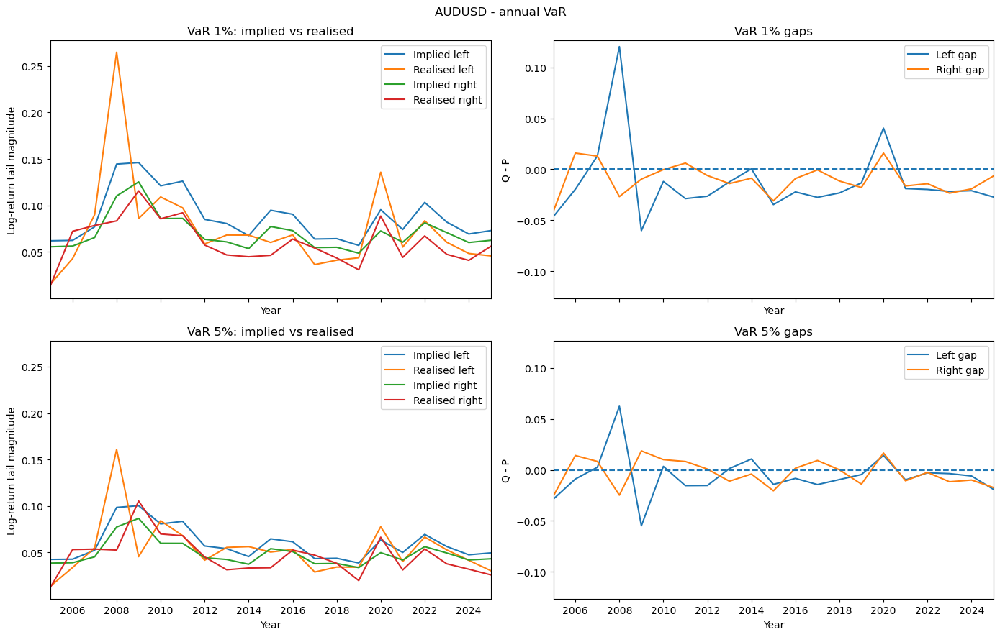

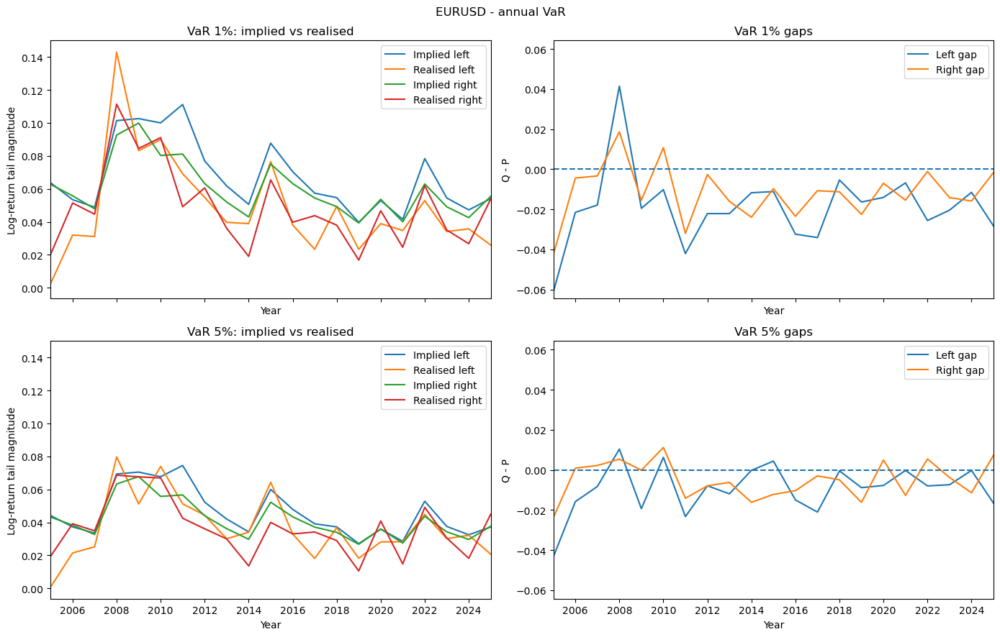

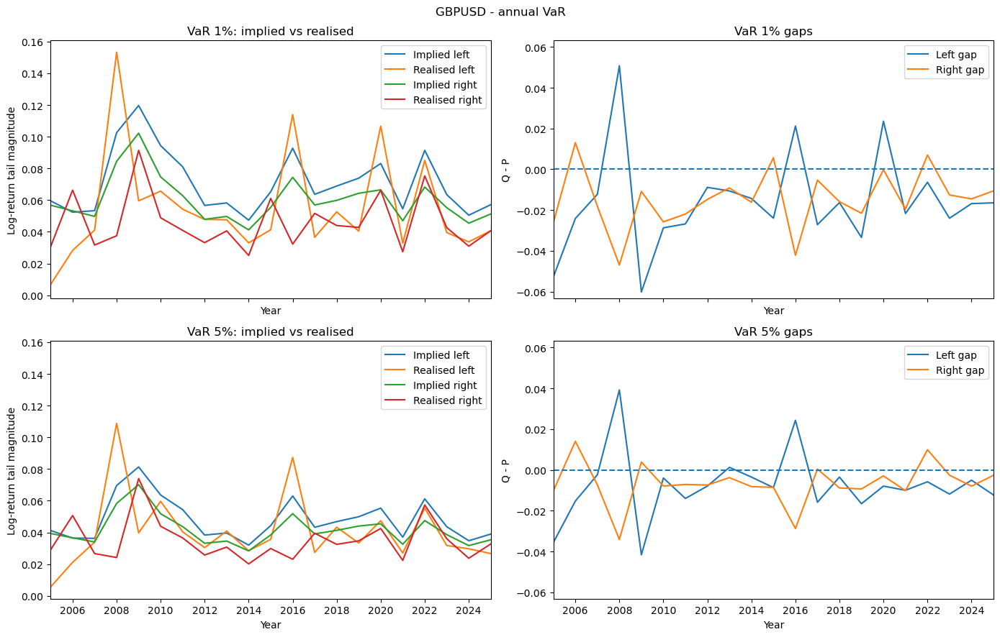

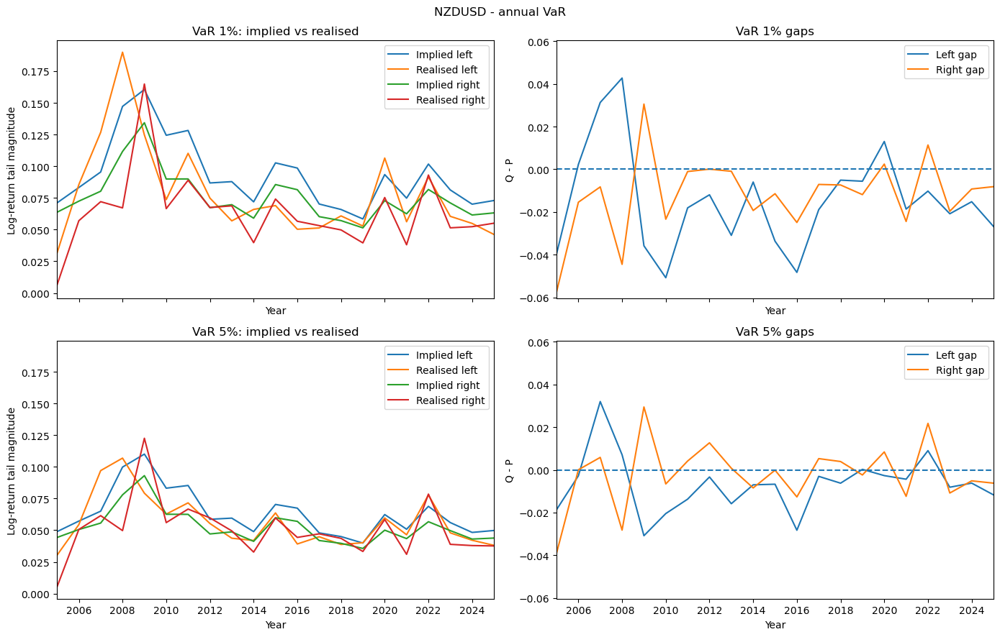

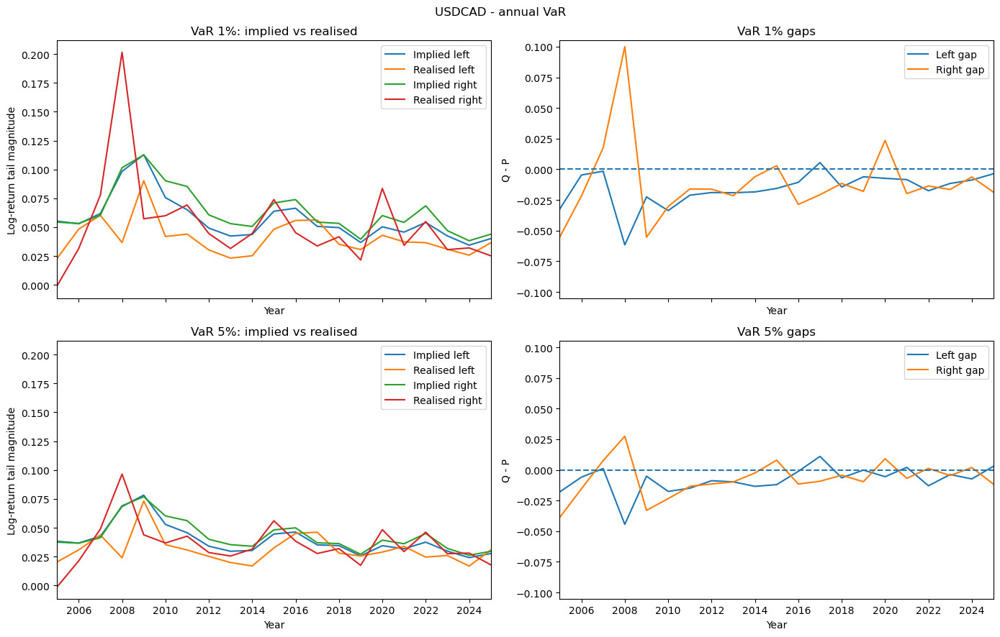

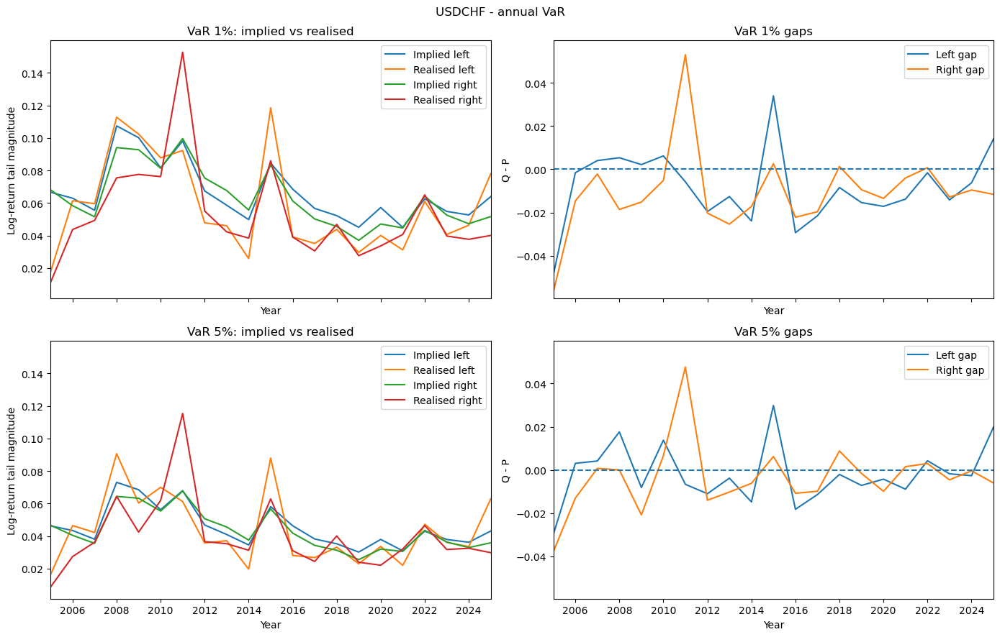

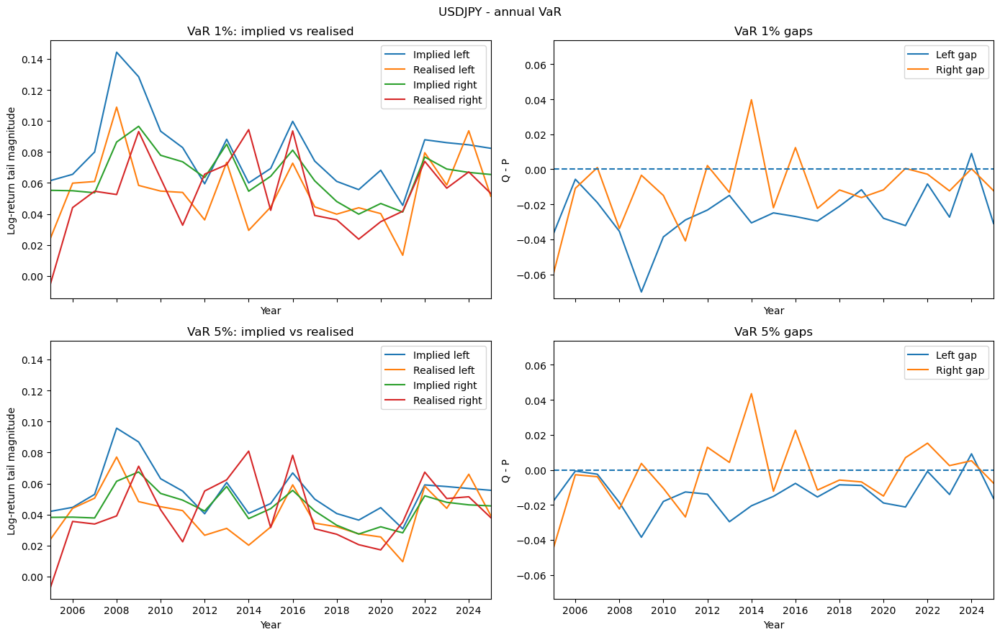

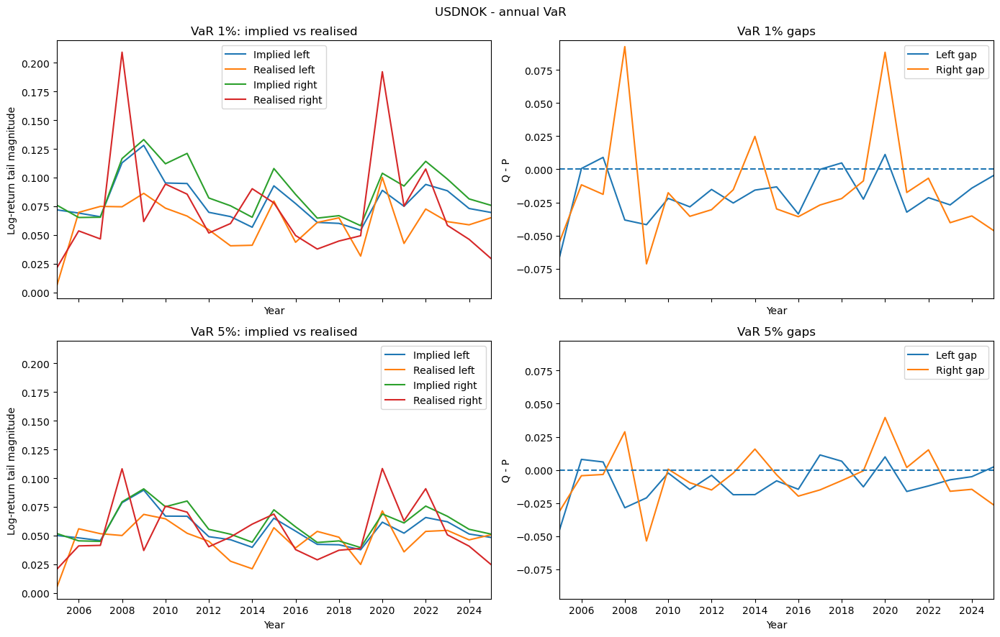

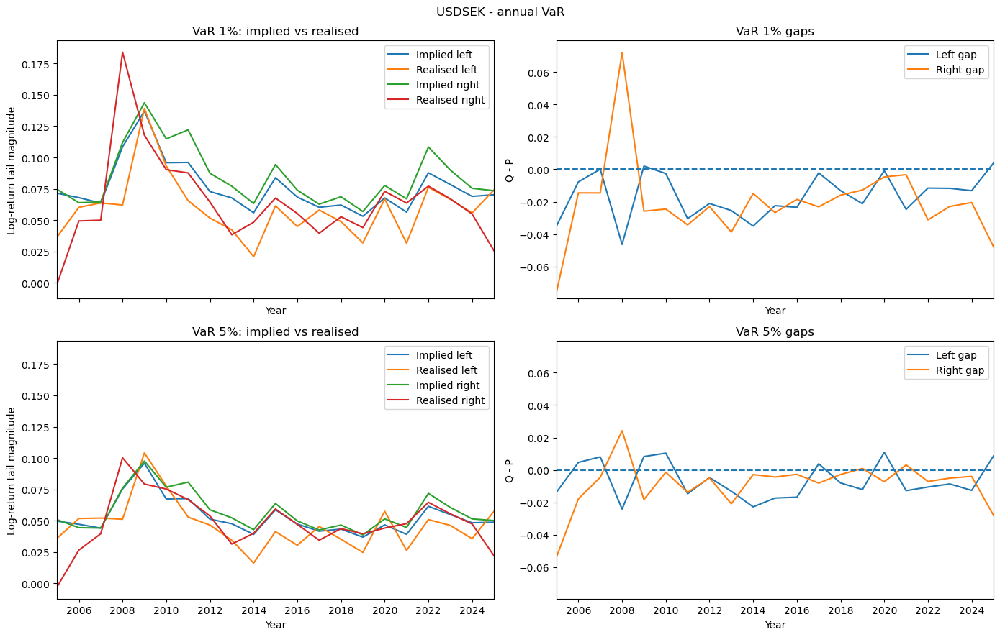

In [99]:
#VaR1% and VaR5% visualisations
for pair in annual_compare['Pair'].unique():
    temp = (annual_compare[annual_compare['Pair']==pair]).sort_values('Year')
    fig, ax = plt.subplots(2 ,2, figsize = (14,9),sharex=True)

    #common range x range
    x_min = temp['Year'].min()
    x_max = temp['Year'].max()
    #common y range
    var_values = temp[['VaR01_L_Q_log','VaR01_L_P','VaR01_R_Q_log','VaR01_R_P','VaR05_L_Q_log','VaR05_L_P','VaR05_R_Q_log','VaR05_R_P']].to_numpy()
    var_ymin = np.nanmin(var_values)
    var_ymax = np.nanmax(var_values)
    var_padding = 0.05*(var_ymax-var_ymin)
    gap_values = temp[['VaR01_L_gap','VaR01_R_gap','VaR05_L_gap','VaR05_R_gap']].to_numpy()
    gap_limit = np.nanmax(np.abs(gap_values))
    gap_limit *= 1.05


    ax[0,0].plot(temp['Year'], temp['VaR01_L_Q_log'], label = 'Implied left')
    ax[0,0].plot(temp['Year'], temp['VaR01_L_P'], label = 'Realised left')
    ax[0,0].plot(temp['Year'], temp['VaR01_R_Q_log'], label = 'Implied right')
    ax[0,0].plot(temp['Year'], temp['VaR01_R_P'], label = 'Realised right')
    ax[0,0].set_title('VaR 1%: implied vs realised')
    ax[0,0].set_xlabel('Year')
    ax[0,0].set_ylabel('Log-return tail magnitude')
    ax[0,0].legend()

    ax[0,1].plot(temp['Year'], temp['VaR01_L_gap'], label = 'Left gap')
    ax[0,1].plot(temp['Year'], temp['VaR01_R_gap'], label = 'Right gap')
    ax[0,1].axhline(0,linestyle = '--')
    ax[0,1].set_title('VaR 1% gaps')
    ax[0,1].set_xlabel('Year')
    ax[0,1].set_ylabel('Q - P')
    ax[0,1].legend()

    ax[1,0].plot(temp['Year'], temp['VaR05_L_Q_log'], label = 'Implied left')
    ax[1,0].plot(temp['Year'], temp['VaR05_L_P'], label = 'Realised left')
    ax[1,0].plot(temp['Year'], temp['VaR05_R_Q_log'], label = 'Implied right')
    ax[1,0].plot(temp['Year'], temp['VaR05_R_P'], label = 'Realised right')
    ax[1,0].set_title('VaR 5%: implied vs realised')
    ax[1,0].set_xlabel('Year')
    ax[1,0].set_ylabel('Log-return tail magnitude')
    ax[1,0].legend()

    ax[1,1].plot(temp['Year'], temp['VaR05_L_gap'], label = 'Left gap')
    ax[1,1].plot(temp['Year'], temp['VaR05_R_gap'], label = 'Right gap')
    ax[1,1].axhline(0,linestyle = '--')
    ax[1,1].set_title('VaR 5% gaps')
    ax[1,1].set_xlabel('Year')
    ax[1,1].set_ylabel('Q - P')
    ax[1,1].legend()

    for a in ax[:,0]:
        a.set_ylim(var_ymin-var_padding, var_ymax+var_padding)
    for a in ax[:,1]:
        a.set_ylim(-gap_limit, gap_limit)
    for a in ax.flat:
        a.set_xlim(x_min,x_max)
        a.xaxis.set_major_locator(MaxNLocator(integer = True))

    fig.suptitle(f'{pair} - annual VaR')
    plt.tight_layout()
    plt.show()

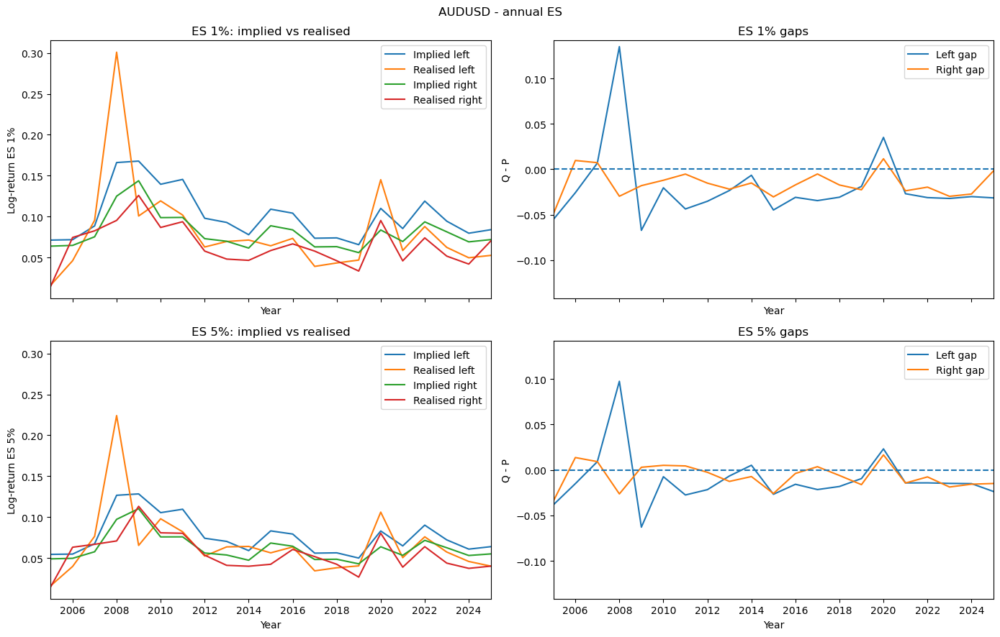

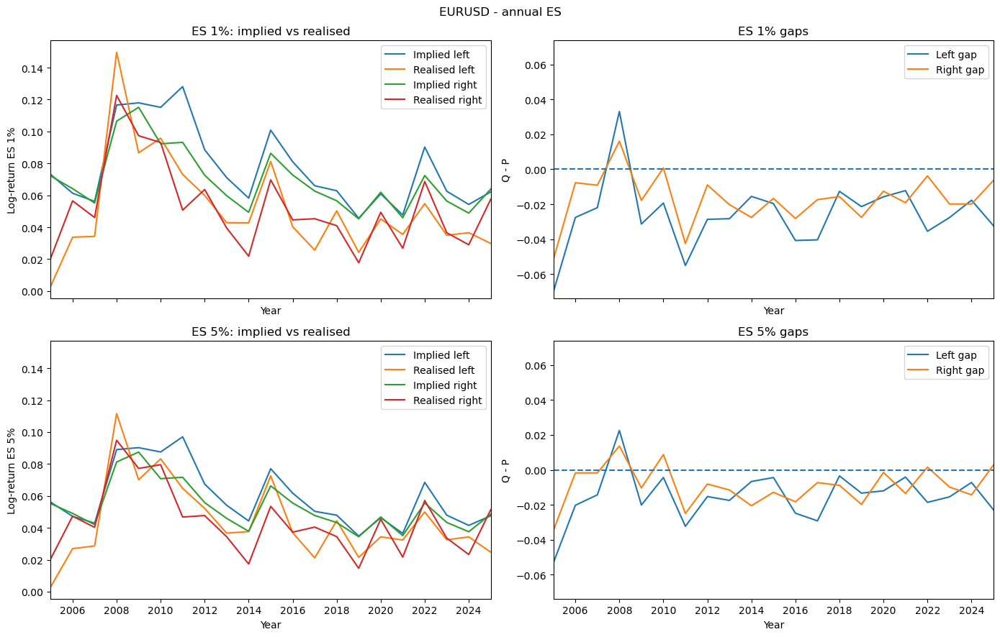

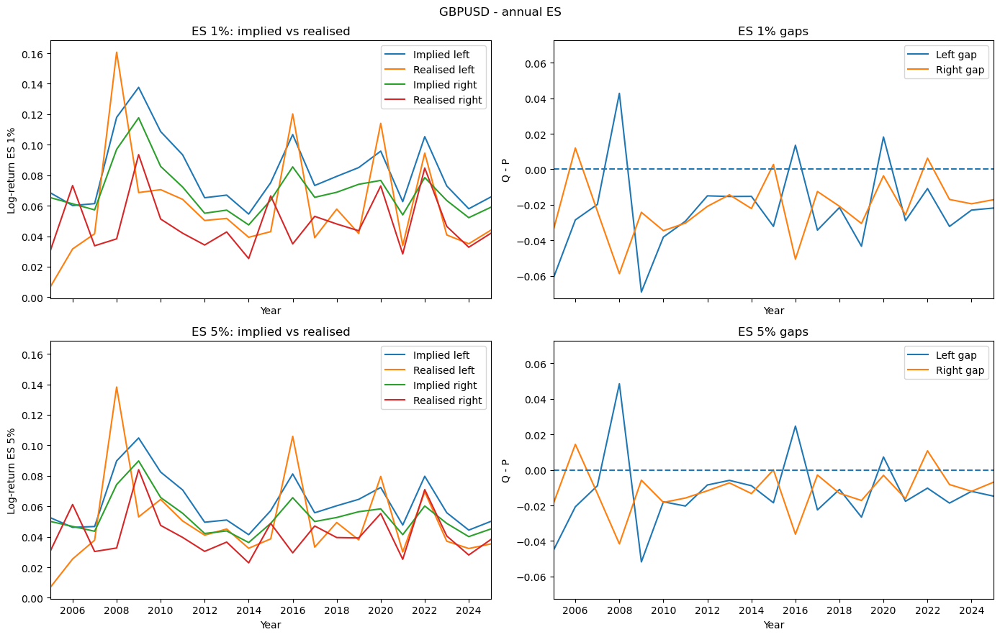

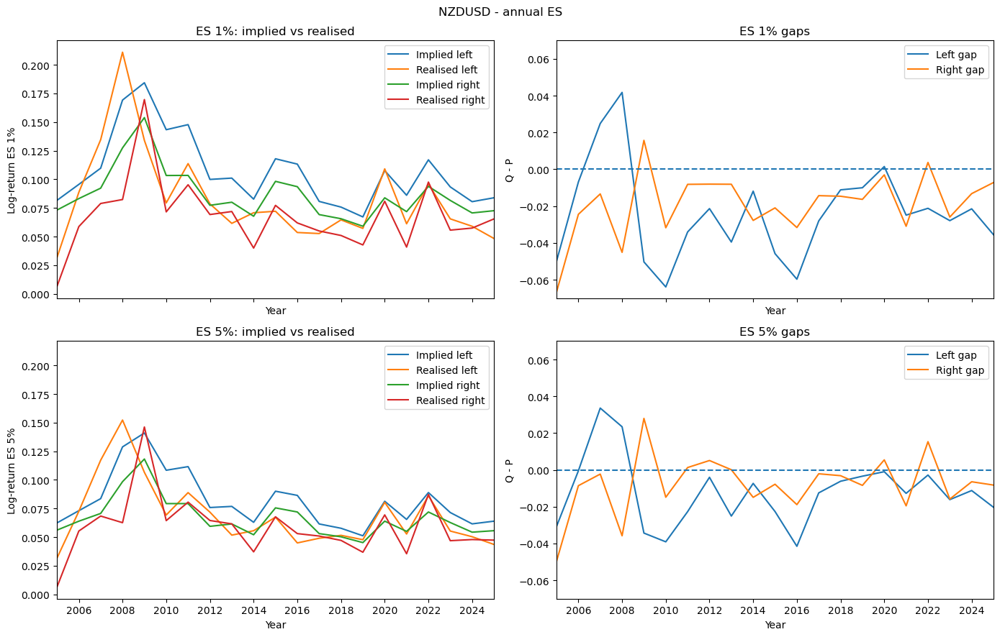

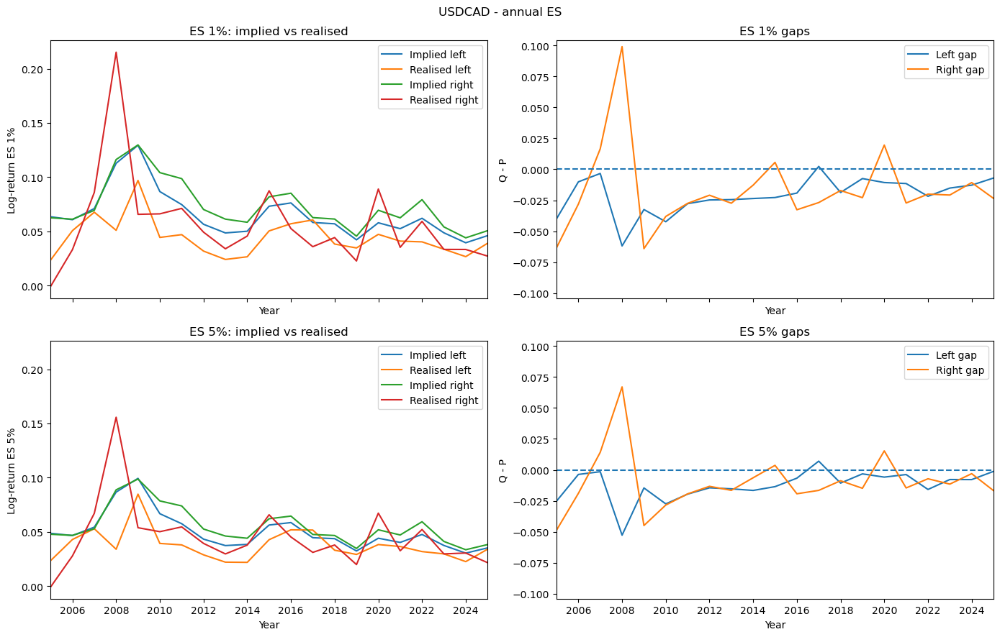

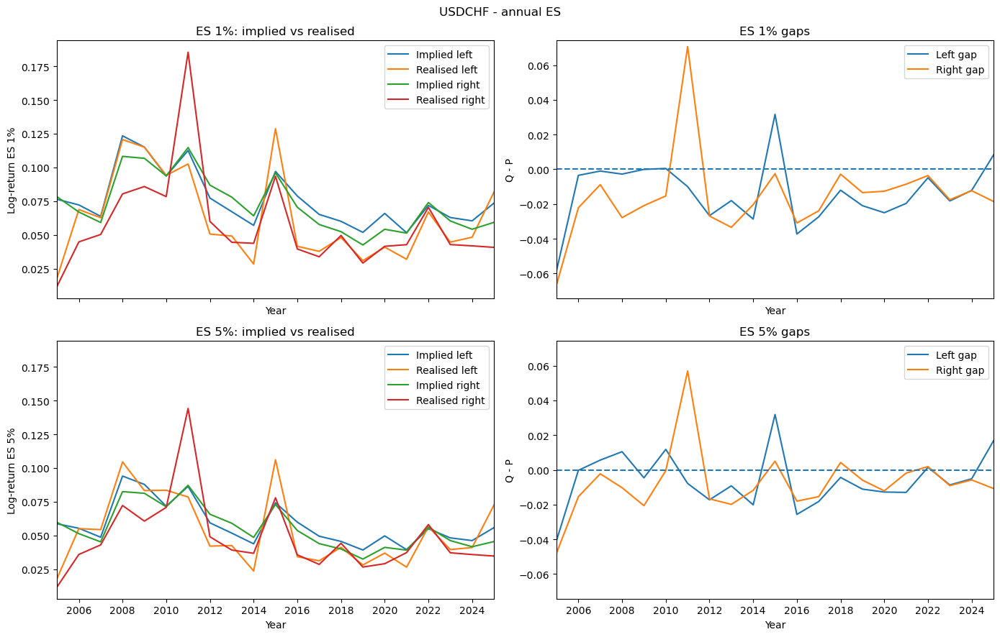

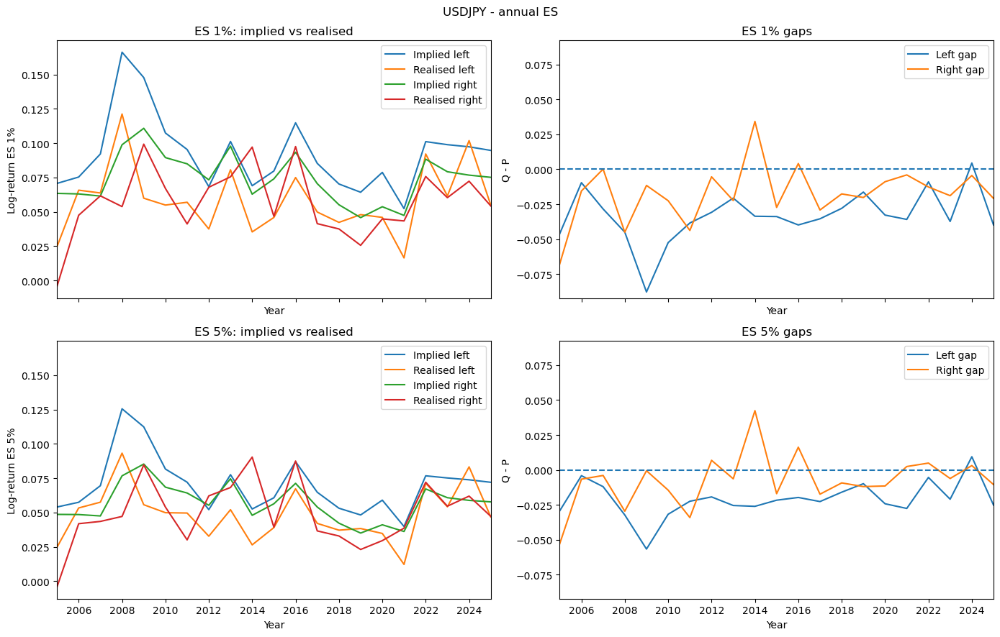

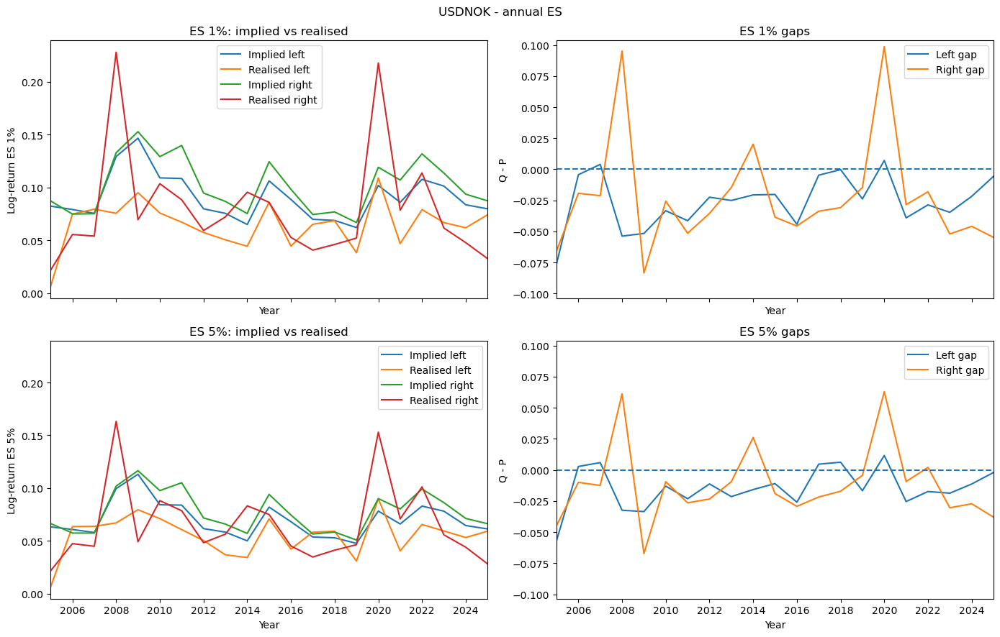

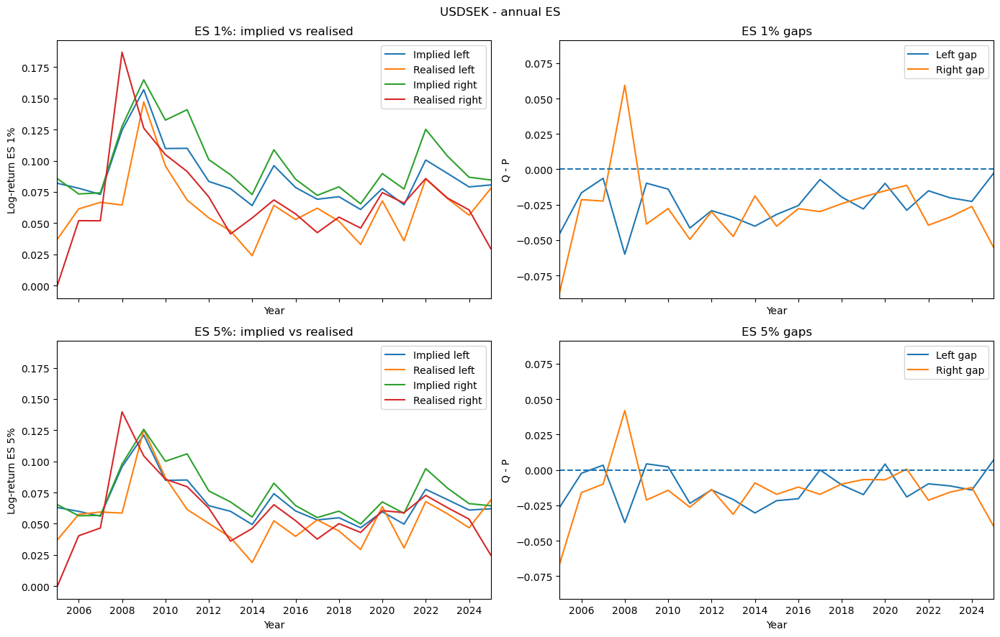

In [100]:
#ES1% and ES5% visualisations
for pair in annual_compare['Pair'].unique():
    temp = (annual_compare[annual_compare['Pair']==pair]).sort_values('Year')
    fig, ax = plt.subplots(2 ,2, figsize = (14,9),sharex=True)

    #common range x range
    x_min = temp['Year'].min()
    x_max = temp['Year'].max()
    #common y range
    es_values = temp[['ES01_L_Q_log','ES01_L_P','ES01_R_Q_log','ES01_R_P','ES05_L_Q_log','ES05_L_P','ES05_R_Q_log','ES05_R_P']].to_numpy()
    es_ymin = np.nanmin(es_values)
    es_ymax = np.nanmax(es_values)
    es_padding = 0.05*(es_ymax-es_ymin)
    gap_values = temp[['ES01_L_gap','ES01_R_gap','ES05_L_gap','ES05_R_gap']].to_numpy()
    gap_limit = np.nanmax(np.abs(gap_values))
    gap_limit *= 1.05


    ax[0,0].plot(temp['Year'], temp['ES01_L_Q_log'], label = 'Implied left')
    ax[0,0].plot(temp['Year'], temp['ES01_L_P'], label = 'Realised left')
    ax[0,0].plot(temp['Year'], temp['ES01_R_Q_log'], label = 'Implied right')
    ax[0,0].plot(temp['Year'], temp['ES01_R_P'], label = 'Realised right')
    ax[0,0].set_title('ES 1%: implied vs realised')
    ax[0,0].set_xlabel('Year')
    ax[0,0].set_ylabel('Log-return ES 1%')
    ax[0,0].legend()

    ax[0,1].plot(temp['Year'], temp['ES01_L_gap'], label = 'Left gap')
    ax[0,1].plot(temp['Year'], temp['ES01_R_gap'], label = 'Right gap')
    ax[0,1].axhline(0,linestyle = '--')
    ax[0,1].set_title('ES 1% gaps')
    ax[0,1].set_xlabel('Year')
    ax[0,1].set_ylabel('Q - P')
    ax[0,1].legend()

    ax[1,0].plot(temp['Year'], temp['ES05_L_Q_log'], label = 'Implied left')
    ax[1,0].plot(temp['Year'], temp['ES05_L_P'], label = 'Realised left')
    ax[1,0].plot(temp['Year'], temp['ES05_R_Q_log'], label = 'Implied right')
    ax[1,0].plot(temp['Year'], temp['ES05_R_P'], label = 'Realised right')
    ax[1,0].set_title('ES 5%: implied vs realised')
    ax[1,0].set_xlabel('Year')
    ax[1,0].set_ylabel('Log-return ES 5%')
    ax[1,0].legend()

    ax[1,1].plot(temp['Year'], temp['ES05_L_gap'], label = 'Left gap')
    ax[1,1].plot(temp['Year'], temp['ES05_R_gap'], label = 'Right gap')
    ax[1,1].axhline(0,linestyle = '--')
    ax[1,1].set_title('ES 5% gaps')
    ax[1,1].set_xlabel('Year')
    ax[1,1].set_ylabel('Q - P')
    ax[1,1].legend()

    for a in ax[:,0]:
        a.set_ylim(es_ymin-es_padding, es_ymax+es_padding)
    for a in ax[:,1]:
        a.set_ylim(-gap_limit, gap_limit)
    for a in ax.flat:
        a.set_xlim(x_min,x_max)
        a.xaxis.set_major_locator(MaxNLocator(integer = True))

    fig.suptitle(f'{pair} - annual ES')
    plt.tight_layout()
    plt.show()

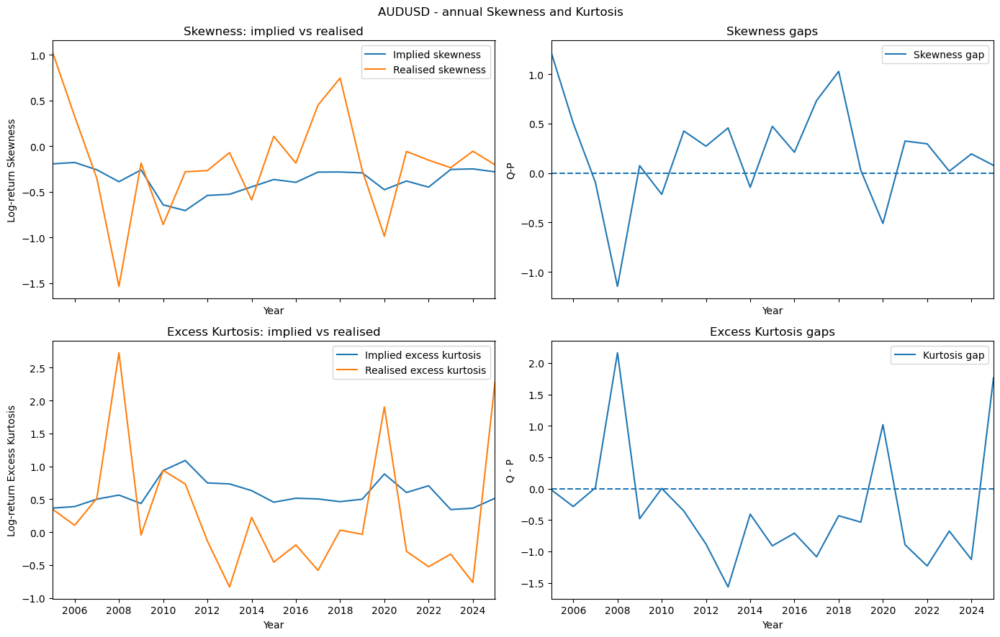

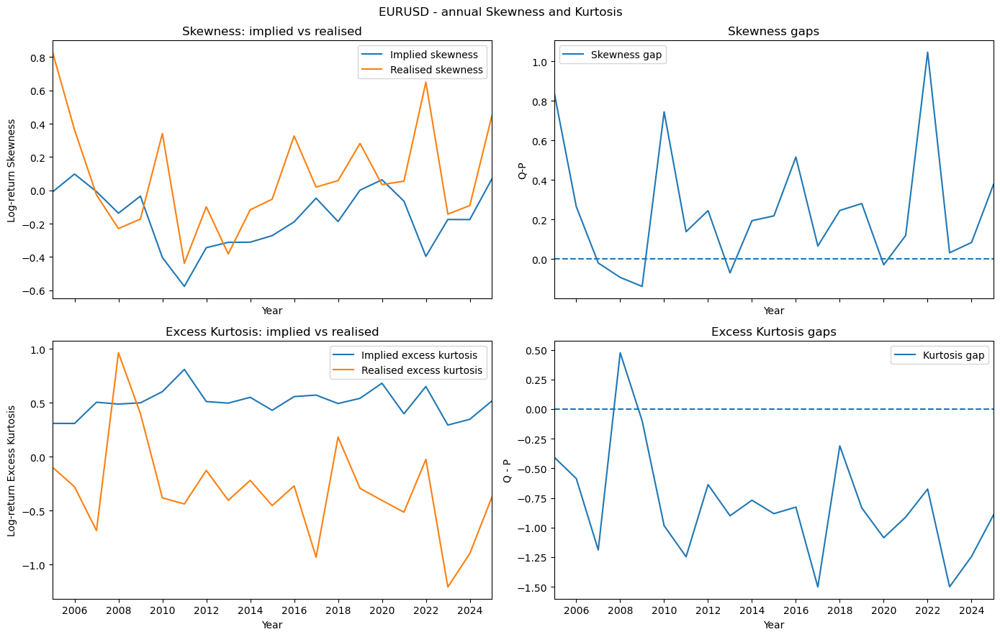

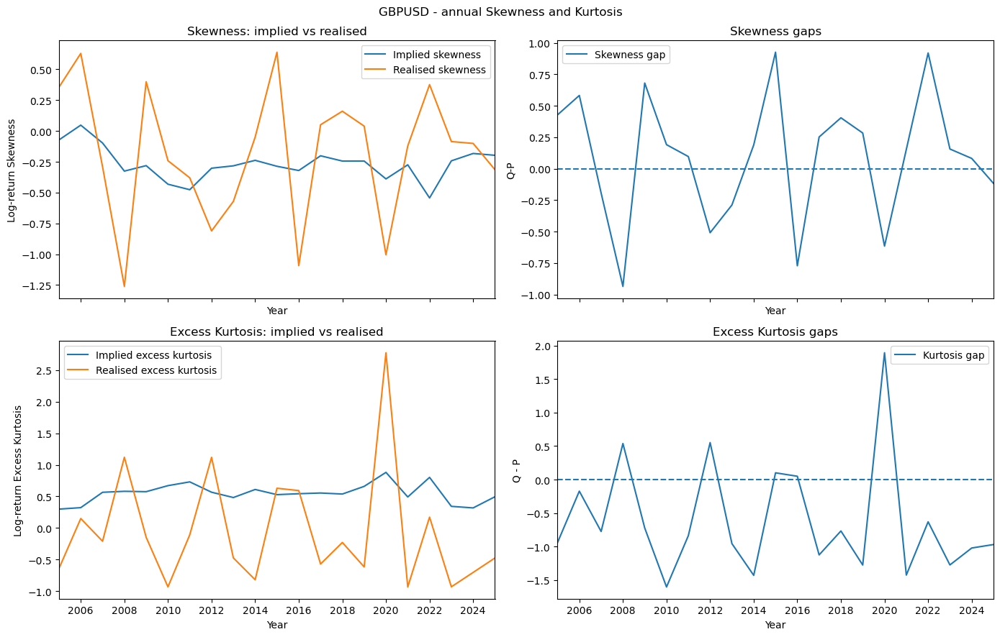

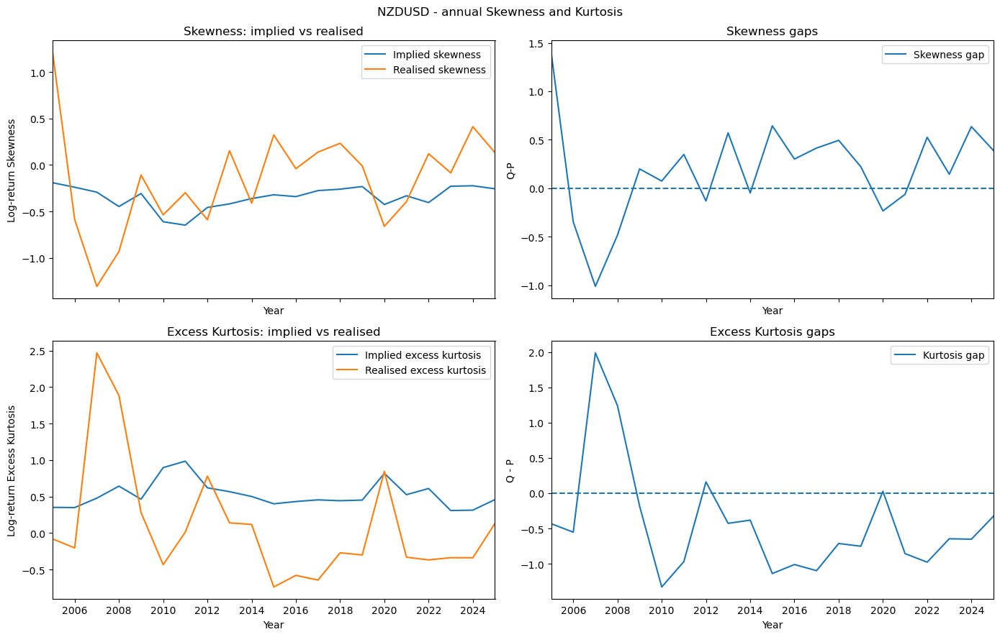

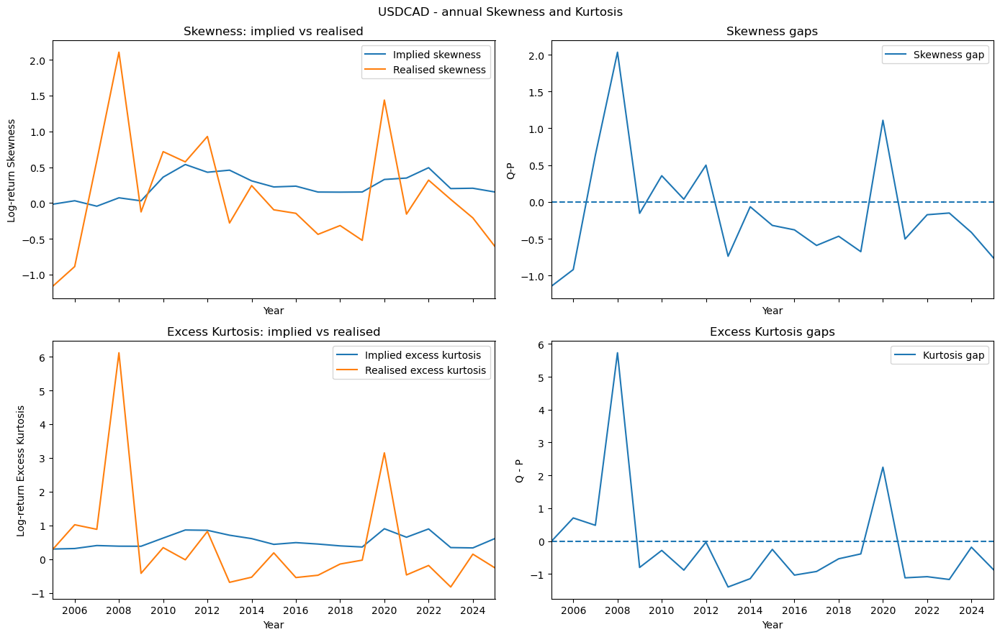

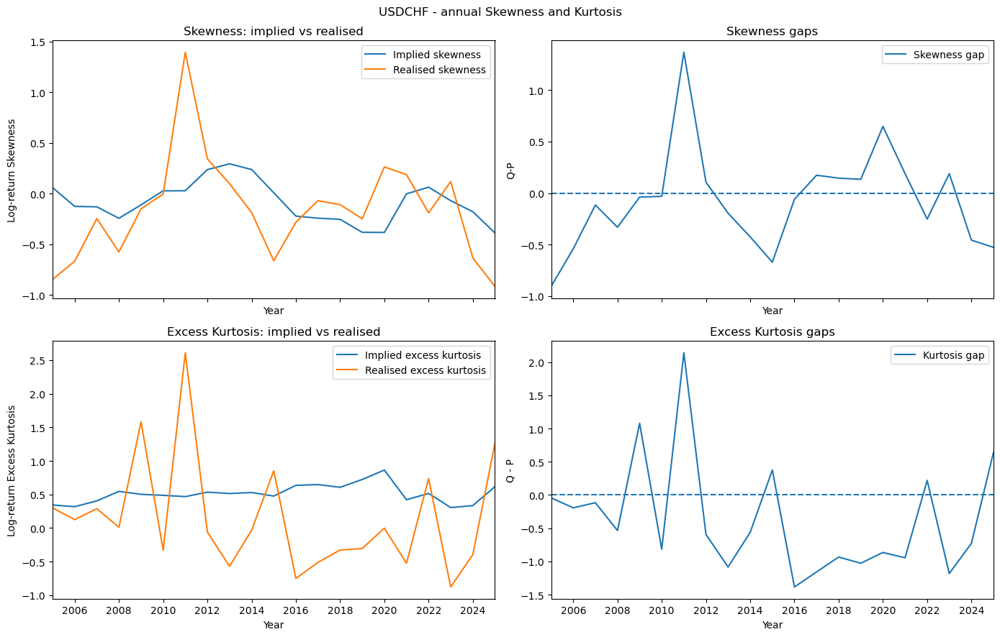

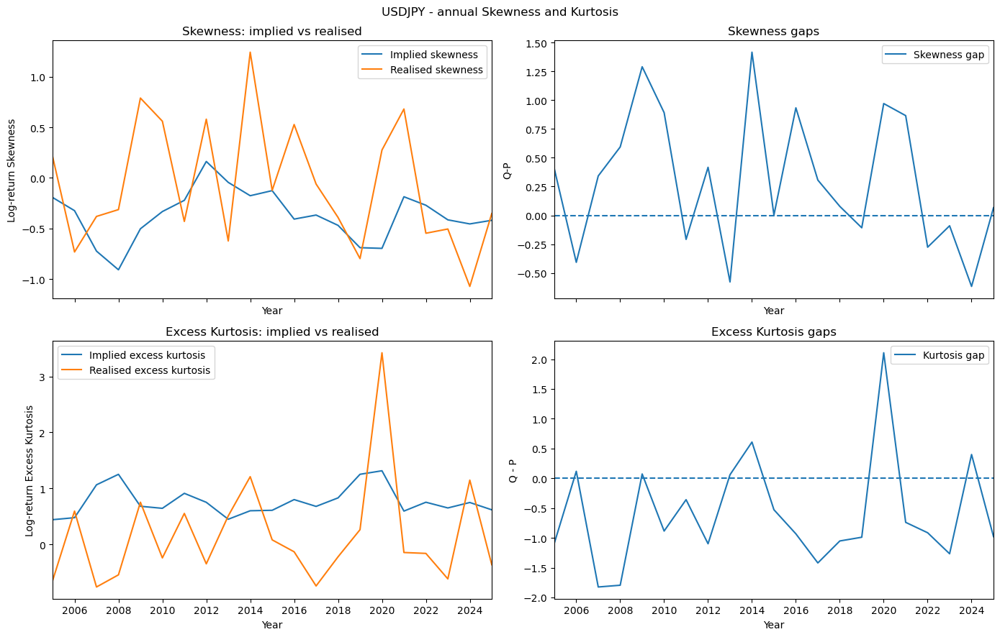

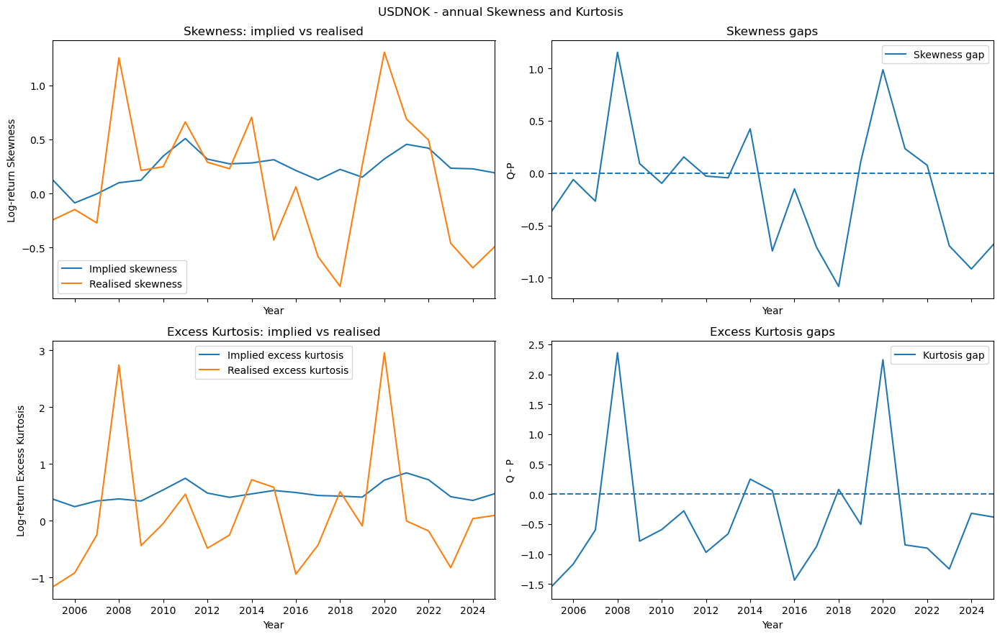

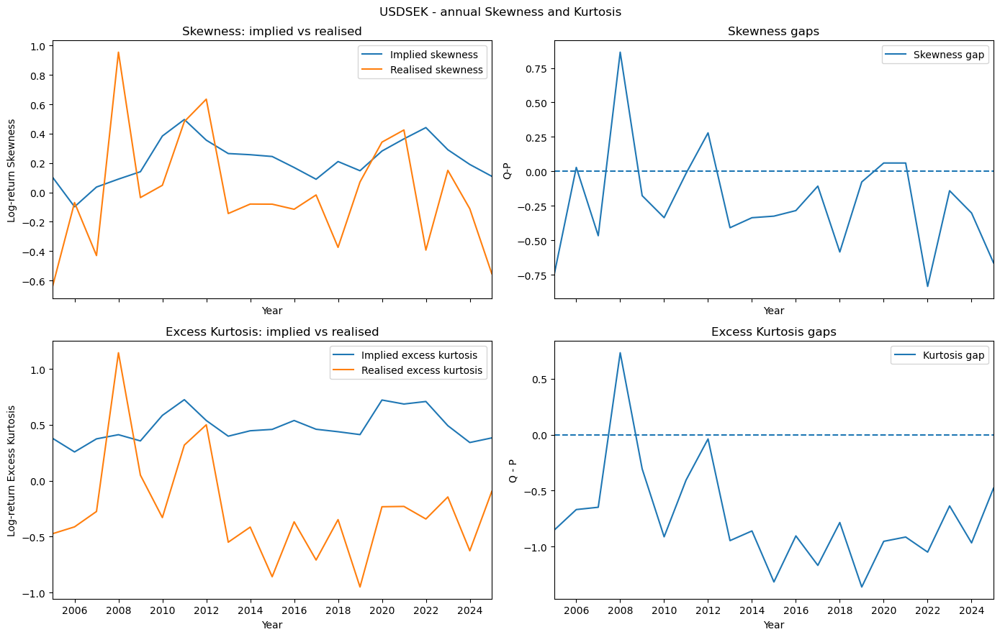

In [101]:
#ES1% and ES5% visualisations
for pair in annual_compare['Pair'].unique():
    temp = (annual_compare[annual_compare['Pair']==pair]).sort_values('Year')
    fig, ax = plt.subplots(2 ,2, figsize = (14,9),sharex=True)

    #common range x range
    x_min = temp['Year'].min()
    x_max = temp['Year'].max()
    #common y range
    # skew_values = temp[['skew_P', 'log skew']].to_numpy()
    # skew_ymin = np.nanmin(skew_values)
    # skew_ymax = np.nanmax(skew_values)
    # skew_padding = 0.05*(skew_ymax-skew_ymin)
    # gap_values = temp[['skew_gap','kurt_gap']].to_numpy()
    # gap_limit = np.nanmax(np.abs(gap_values))
    # gap_limit *= 1.05


    ax[0,0].plot(temp['Year'], temp['log skew'], label = 'Implied skewness')
    ax[0,0].plot(temp['Year'], temp['skew_P'], label = 'Realised skewness')
    ax[0,0].set_title('Skewness: implied vs realised')
    ax[0,0].set_xlabel('Year')
    ax[0,0].set_ylabel('Log-return Skewness')
    ax[0,0].legend()

    ax[1,0].plot(temp['Year'], temp['log excess kurt'], label = 'Implied excess kurtosis')
    ax[1,0].plot(temp['Year'], temp['excess_kurt_P'], label = 'Realised excess kurtosis')
    ax[1,0].set_title('Excess Kurtosis: implied vs realised')
    ax[1,0].set_xlabel('Year')
    ax[1,0].set_ylabel('Log-return Excess Kurtosis')
    ax[1,0].legend()

    ax[0,1].plot(temp['Year'], temp['skew_gap'], label = 'Skewness gap')
    ax[0,1].axhline(0,linestyle = '--') 
    ax[0,1].set_title('Skewness gaps')
    ax[0,1].set_xlabel('Year')
    ax[0,1].set_ylabel('Q-P')
    ax[0,1].legend()

    ax[1,1].plot(temp['Year'], temp['kurt_gap'], label = 'Kurtosis gap')
    ax[1,1].axhline(0,linestyle = '--')
    ax[1,1].set_title('Excess Kurtosis gaps')
    ax[1,1].set_xlabel('Year')
    ax[1,1].set_ylabel('Q - P')
    ax[1,1].legend()

    # for a in ax[:,0]:
    #     a.set_ylim(es_ymin-es_padding, es_ymax+es_padding)
    # for a in ax[:,1]:
    #     a.set_ylim(-gap_limit, gap_limit)
    for a in ax.flat:
        a.set_xlim(x_min,x_max)
        a.xaxis.set_major_locator(MaxNLocator(integer = True))

    fig.suptitle(f'{pair} - annual Skewness and Kurtosis')
    plt.tight_layout()
    plt.show()

In [102]:
#MEAN values of annual gaps
gap_volumns = ['VaR01_L_gap','VaR05_L_gap','VaR01_R_gap','VaR05_R_gap','ES01_L_gap','ES05_L_gap','ES01_R_gap','ES05_R_gap','skew_gap','kurt_gap']
annual_gap_means = annual_compare.groupby('Pair')[gap_volumns].mean().reset_index()
annual_gap_means

,Pair,VaR01_L_gap,VaR05_L_gap,VaR01_R_gap,VaR05_R_gap,ES01_L_gap,ES05_L_gap,ES01_R_gap,ES05_R_gap,skew_gap,kurt_gap
0,AUDUSD,-0.012407,-0.005749,-0.009788,-0.003061,-0.019572,-0.010467,-0.015796,-0.007259,0.201478,-0.316261
1,EURUSD,-0.018679,-0.009281,-0.011573,-0.005041,-0.025719,-0.015070,-0.016912,-0.009169,0.241245,-0.810256
2,GBPUSD,-0.015666,-0.007489,-0.014582,-0.006664,-0.022116,-0.012385,-0.020893,-0.011285,0.090993,-0.608681
3,NZDUSD,-0.014612,-0.006738,-0.011897,-0.001886,-0.023596,-0.012253,-0.018678,-0.007683,0.192296,-0.429925
4,USDCAD,-0.015828,-0.008111,-0.011059,-0.007177,-0.020724,-0.012389,-0.016325,-0.009933,-0.132882,-0.140571
5,USDCHF,-0.008298,-0.001844,-0.010509,-0.003403,-0.013618,-0.005742,-0.015155,-0.007424,-0.076491,-0.367039
6,USDJPY,-0.025492,-0.013835,-0.011061,-0.002536,-0.033167,-0.021126,-0.017100,-0.007462,0.299621,-0.595623
7,USDNOK,-0.018853,-0.008864,-0.015195,-0.005854,-0.025716,-0.014551,-0.022148,-0.011818,-0.124689,-0.388019
8,USDSEK,-0.016309,-0.006578,-0.020097,-0.008580,-0.024224,-0.012331,-0.028839,-0.015512,-0.214442,-0.736233


In [103]:
#volatility of annual gaps
annual_gap_vols = annual_compare.groupby('Pair')[gap_volumns].std().reset_index()
annual_gap_vols

,Pair,VaR01_L_gap,VaR05_L_gap,VaR01_R_gap,VaR05_R_gap,ES01_L_gap,ES05_L_gap,ES01_R_gap,ES05_R_gap,skew_gap,kurt_gap
0,AUDUSD,0.036458,0.021239,0.014911,0.013481,0.041127,0.030111,0.014800,0.013572,0.505601,0.938237
1,EURUSD,0.018918,0.012002,0.013632,0.009286,0.019572,0.014527,0.014432,0.011324,0.314065,0.462839
2,GBPUSD,0.024319,0.016744,0.014501,0.010502,0.024806,0.020935,0.016905,0.012700,0.509816,0.841848
3,NZDUSD,0.023563,0.013389,0.018350,0.015052,0.025892,0.018448,0.017556,0.016356,0.498449,0.788942
4,USDCAD,0.014227,0.011066,0.031457,0.014508,0.014752,0.012437,0.033299,0.023348,0.736120,1.580220
5,USDCHF,0.017179,0.013690,0.019330,0.015751,0.018426,0.015768,0.024112,0.018693,0.488289,0.870030
6,USDJPY,0.015462,0.010348,0.019928,0.018439,0.018540,0.013030,0.020456,0.019011,0.594502,0.910809
7,USDNOK,0.018680,0.013925,0.040171,0.020288,0.021071,0.016229,0.045021,0.030732,0.570728,1.012301
8,USDSEK,0.013910,0.011349,0.026298,0.014691,0.014581,0.012660,0.026224,0.019251,0.377660,0.464441


# Statistical analysis

In [104]:
#statistically test whether the gaps are significantly different from zero (or statistically significant n general)
#hypothesis: H0: mean gap = 0, H1: mean gap != 0
#test the test with the out of sample of the mean gap against zero
#note that these gaps are time series so we need to account for possible serianl depdennce

In [105]:
# Note:
# Each realised observation is a 1-month forward-relative log outcome:
#     log(S_{t+1M} / F_t)
#
# Although only the start and terminal FX levels are explicitly used, returns
# constructed on consecutive trading days overlap economically. For example,
# Jan 2-Feb 2 and Jan 3-Feb 3 share almost the entire underlying 1-month
# price path. Consequently, adjacent 1M returns are not independent and can
# exhibit mechanically induced serial correlation in addition to any genuine
# time-series persistence in FX markets.
#
#
# IMPORTANT FOR INFERENCE:
# The number of overlapping observations must not be interpreted as the number
# of independent observations. Naive standard errors may therefore overstate
# statistical significance. The final Q-P gap series will be sampled monthly,
# its serial dependence will be diagnosed explicitly, and inference will use
# an appropriate dependence-robust method where required. Hansen-Hodrick is a
# natural candidate because it was developed for overlapping multi-period
# forecast horizons; HAC/Newey-West or dependence-aware bootstrap methods can
# be considered as robustness alternatives.

5 year rolling physical distribution based on overlapping 1M forward-relative log returns. Then sample the resulting comparison once per month

In [106]:
#create a rolling physical neasure in the full daily pannel
p_cols = ['VaR01_L_P_roll', 'VaR05_L_P_roll', 'VaR01_R_P_roll', 'VaR05_R_P_roll', 'ES01_L_P_roll', 'ES05_L_P_roll', 'ES01_R_P_roll', 'ES05_R_P_roll', 'skew_P_roll', 'excess_kurt_P_roll']

for col in p_cols:
    analysis[col] = np.nan

for pair in analysis['Pair'].unique():
    temp = analysis[analysis['Pair']==pair].sort_values('Date').copy()
    for idx, row in temp.iterrows():
        current_date = row['Date']
        #guse only 1M outcomes that were already fully realised befire the current option date
        history = temp.loc[(temp['RealisedDate_1M'] < current_date) & (temp['RealisedDate_1M']>=current_date - pd.DateOffset(years=5)),'realised_forward_log_return'].dropna() #to prevent look ahead bias
        #ensure that there is enough data in the window
        if len(history)<500:
            continue
        q01 = history.quantile(0.01)
        q05 = history.quantile(0.05)
        q99 = history.quantile(0.99)
        q95 = history.quantile(0.95)

        analysis.loc[idx, 'VaR01_L_P_roll'] = -q01
        analysis.loc[idx, 'VaR05_L_P_roll'] = -q05
        analysis.loc[idx, 'VaR01_R_P_roll'] = q99
        analysis.loc[idx, 'VaR05_R_P_roll'] = q95
        analysis.loc[idx, 'ES01_L_P_roll'] = -history[history<=q01].mean()
        analysis.loc[idx, 'ES05_L_P_roll'] = -history[history<=q05].mean()
        analysis.loc[idx, 'ES01_R_P_roll'] = history[history>=q99].mean()
        analysis.loc[idx, 'ES05_R_P_roll'] = history[history>=q95].mean()
        analysis.loc[idx, 'skew_P_roll'] = history.skew()
        analysis.loc[idx, 'excess_kurt_P_roll'] = history.kurt()

In [107]:
#create a  daily rolling gaps
analysis['VaR01_L_gap_roll'] = analysis['VaR01_L_P_roll'] - analysis['VaR01_L_Q_log']
analysis['VaR05_L_gap_roll'] = analysis['VaR05_L_P_roll'] - analysis['VaR05_L_Q_log']
analysis['VaR01_R_gap_roll'] = analysis['VaR01_R_P_roll'] - analysis['VaR01_R_Q_log']
analysis['VaR05_R_gap_roll'] = analysis['VaR05_R_P_roll'] - analysis['VaR05_R_Q_log']
analysis['ES01_L_gap_roll'] = analysis['ES01_L_P_roll'] - analysis['ES01_L_Q_log']
analysis['ES05_L_gap_roll'] = analysis['ES05_L_P_roll'] - analysis['ES05_L_Q_log']
analysis['ES01_R_gap_roll'] = analysis['ES01_R_P_roll'] - analysis['ES01_R_Q_log']
analysis['ES05_R_gap_roll'] = analysis['ES05_R_P_roll'] - analysis['ES05_R_Q_log']
analysis['skew_gap_roll'] = analysis['skew_P_roll'] - analysis['log skew']
analysis['kurt_gap_roll'] = analysis['excess_kurt_P_roll'] - analysis['log excess kurt']

In [108]:
#create a separate monthly inference df
analysis['Month'] = pd.to_datetime(analysis['Date']).dt.to_period('M')
monthly_compare = analysis.sort_values(['Pair','Date']).groupby(['Pair','Month']).last().reset_index() #let the last available trading date in the month represent the month
monthly_compare['Date']=monthly_compare['Month'].dt.to_timestamp('M')
#keep only useful columns
monthly_cols = ['Date','Month','Pair','VaR01_L_Q_log','VaR01_L_P_roll','VaR01_L_gap_roll','VaR01_R_Q_log','VaR01_R_P_roll', 'VaR01_R_gap_roll','VaR05_L_Q_log','VaR05_L_P_roll','VaR05_L_gap_roll','VaR05_R_Q_log','VaR05_R_P_roll','VaR05_R_gap_roll','ES01_L_Q_log','ES01_L_P_roll','ES01_L_gap_roll','ES01_R_Q_log','ES01_R_P_roll','ES01_R_gap_roll','ES05_L_Q_log','ES05_L_P_roll','ES05_L_gap_roll','ES05_R_Q_log','ES05_R_P_roll','ES05_R_gap_roll','skew_P_roll','log skew','skew_gap_roll','excess_kurt_P_roll','log excess kurt','kurt_gap_roll']
monthly_compare = monthly_compare[monthly_cols].copy()
monthly_compare = monthly_compare.dropna(subset = ['VaR01_L_gap_roll','VaR01_R_gap_roll','VaR05_L_gap_roll','VaR05_R_gap_roll','ES01_L_gap_roll','ES01_R_gap_roll','ES05_L_gap_roll','ES05_R_gap_roll','skew_gap_roll','kurt_gap_roll'])

In [109]:
#autocorrelation
gap_cols_roll = ['VaR01_L_gap_roll','VaR01_R_gap_roll','VaR05_L_gap_roll','VaR05_R_gap_roll','ES01_L_gap_roll','ES01_R_gap_roll','ES05_L_gap_roll','ES05_R_gap_roll','skew_gap_roll','kurt_gap_roll']
acf_results = []
for pair in monthly_compare['Pair'].unique():
    temp = monthly_compare[monthly_compare['Pair']==pair].sort_values('Date')
    for col in gap_cols_roll:
        x = temp[col].dropna()
        row = {'Pair':pair, 'Metric': col}
        for lag in range(1,13):
            row[f'AC_lag{lag}'] = x.autocorr(lag=lag) #consider several month lag to se if the autocorrelation persists for more than a month
        acf_results.append(row)
acf_results = pd.DataFrame(acf_results)

acf_results[['Pair','Metric','AC_lag1','AC_lag2','AC_lag3','AC_lag6','AC_lag12']].round(3)

,Pair,Metric,AC_lag1,AC_lag2,AC_lag3,AC_lag6,AC_lag12
0,AUDUSD,VaR01_L_gap_roll,0.848,0.738,0.668,0.516,0.324
1,AUDUSD,VaR01_R_gap_roll,0.871,0.771,0.671,0.480,0.280
2,AUDUSD,VaR05_L_gap_roll,0.789,0.650,0.548,0.346,0.155
3,AUDUSD,VaR05_R_gap_roll,0.875,0.771,0.672,0.491,0.305
4,AUDUSD,ES01_L_gap_roll,0.902,0.824,0.770,0.661,0.486
...,...,...,...,...,...,...,...
85,USDSEK,ES01_R_gap_roll,0.864,0.799,0.764,0.595,0.340
86,USDSEK,ES05_L_gap_roll,0.889,0.809,0.724,0.504,0.268
87,USDSEK,ES05_R_gap_roll,0.837,0.753,0.699,0.497,0.206
88,USDSEK,skew_gap_roll,0.903,0.814,0.725,0.522,0.366


In [110]:
#run   ljung-box
from statsmodels.stats.diagnostic import acorr_ljungbox
lb_results = []
for pair in monthly_compare['Pair'].unique():
    temp = monthly_compare[monthly_compare['Pair']==pair].sort_values('Date')
    for col in gap_cols_roll:
        x = temp[col].dropna()
        lb_test = acorr_ljungbox(x, lags=[1,3,6,12], return_df=True) #to test whetehr at least any of those autocorrelation is zero, if p-value <0.05 we reject the null of no autocorrelation
        lb_results.append({'Pair':pair, 'Metric': col, 'LB_p_lag1': lb_test.loc[1,'lb_pvalue'], 'LB_p_lag3': lb_test.loc[3,'lb_pvalue'], 'LB_p_lag6': lb_test.loc[6,'lb_pvalue'], 'LB_p_lag12': lb_test.loc[12,'lb_pvalue']})
lb_results = pd.DataFrame(lb_results)
lb_results.round(4)
#the table below shows that there is an autocorrelation

,Pair,Metric,LB_p_lag1,LB_p_lag3,LB_p_lag6,LB_p_lag12
0,AUDUSD,VaR01_L_gap_roll,0.0,0.0,0.0,0.0
1,AUDUSD,VaR01_R_gap_roll,0.0,0.0,0.0,0.0
2,AUDUSD,VaR05_L_gap_roll,0.0,0.0,0.0,0.0
3,AUDUSD,VaR05_R_gap_roll,0.0,0.0,0.0,0.0
4,AUDUSD,ES01_L_gap_roll,0.0,0.0,0.0,0.0
...,...,...,...,...,...,...
85,USDSEK,ES01_R_gap_roll,0.0,0.0,0.0,0.0
86,USDSEK,ES05_L_gap_roll,0.0,0.0,0.0,0.0
87,USDSEK,ES05_R_gap_roll,0.0,0.0,0.0,0.0
88,USDSEK,skew_gap_roll,0.0,0.0,0.0,0.0


In [111]:
#evaluate where the gap persistence comes from: if the Q persistent and P persistent or both
components = {"VaR01_L":['VaR01_L_Q_log','VaR01_L_P_roll','VaR01_L_gap_roll'],
              "VaR05_L":['VaR05_L_Q_log','VaR05_L_P_roll','VaR05_L_gap_roll'],
              "VaR01_R":['VaR01_R_Q_log','VaR01_R_P_roll','VaR01_R_gap_roll'],
              "VaR05_R":['VaR05_R_Q_log','VaR05_R_P_roll','VaR05_R_gap_roll'],
              "ES01_L":['ES01_L_Q_log','ES01_L_P_roll','ES01_L_gap_roll'],
              "ES05_L":['ES05_L_Q_log','ES05_L_P_roll','ES05_L_gap_roll'],
              "ES01_R":['ES01_R_Q_log','ES01_R_P_roll','ES01_R_gap_roll'],
              'ES05_R':['ES05_R_Q_log','ES05_R_P_roll','ES05_R_gap_roll']}
rows = []
for pair in monthly_compare['Pair'].unique():
    temp = monthly_compare[monthly_compare['Pair']==pair].sort_values('Date')
    for metric, cols in components.items():
        q_col, p_col,gap_col = cols
        rows.append({'Pair':pair, 'Metric':metric, 'AC1_Q':temp[q_col].autocorr(lag=1), 'AC1_P':temp[p_col].autocorr(lag=1), 'AC1_gap':temp[gap_col].autocorr(lag=1)})
components_ac=pd.DataFrame(rows)
components_ac.round(3)

,Pair,Metric,AC1_Q,AC1_P,AC1_gap
0,AUDUSD,VaR01_L,0.810,0.980,0.848
1,AUDUSD,VaR05_L,0.814,0.987,0.789
2,AUDUSD,VaR01_R,0.864,0.994,0.871
3,AUDUSD,VaR05_R,0.855,0.996,0.875
4,AUDUSD,ES01_L,0.810,0.981,0.902
...,...,...,...,...,...
67,USDSEK,VaR05_R,0.876,0.990,0.841
68,USDSEK,ES01_L,0.881,0.991,0.903
69,USDSEK,ES05_L,0.880,0.995,0.889
70,USDSEK,ES01_R,0.880,0.984,0.864


Perform siginificance test:
Start with whether gap exists -> H0: E(G) = 0 aka is the difference statistically different from zero


But note: since data is very persistent, the observations are not independent and the significance might be overstate if using regulat t-statistics. Hence, use Newey-West HAC standard errors (reference to Ammann & Buesser).  Della Corte et al. also uses Newey-West/ANdrews-type robust inderence. 

In Ammann & Buesser, they include lags up to one ger(# of algs = 12) meaning that when estimatin uncertainty of the mean gap, Newey_west allows today's error to be correlated with errors

In [112]:
#TRANSFORM EVERYTHIN SO THAT EVERY PAIR IS USD DENOMINATED
usd_base = ['AUDUSD','EURUSD','GBPUSD','NZDUSD']
monthly_compare['VaR01_L_gap_std'] = monthly_compare['VaR01_L_gap_roll']
monthly_compare['VaR01_R_gap_std']=monthly_compare['VaR01_R_gap_roll']
monthly_compare['VaR05_L_gap_std'] = monthly_compare['VaR05_L_gap_roll']
monthly_compare['VaR05_R_gap_std']=monthly_compare['VaR05_R_gap_roll']
monthly_compare['ES01_L_gap_std'] = monthly_compare['ES01_L_gap_roll']
monthly_compare['ES01_R_gap_std']=monthly_compare['ES01_R_gap_roll']
monthly_compare['ES05_L_gap_std'] = monthly_compare['ES05_L_gap_roll']
monthly_compare['ES05_R_gap_std']=monthly_compare['ES05_R_gap_roll']
mask = monthly_compare['Pair'].isin(usd_base)
monthly_compare.loc[mask,'VaR01_L_gap_std'] =  monthly_compare.loc[mask,'VaR01_R_gap_roll']
monthly_compare.loc[mask, 'VaR01_R_gap_std']=monthly_compare.loc[mask, 'VaR01_L_gap_roll']
monthly_compare.loc[mask,'VaR05_L_gap_std'] =  monthly_compare.loc[mask,'VaR05_R_gap_roll']
monthly_compare.loc[mask, 'VaR05_R_gap_std']=monthly_compare.loc[mask, 'VaR05_L_gap_roll']
monthly_compare.loc[mask,'ES01_L_gap_std'] =  monthly_compare.loc[mask,'ES01_R_gap_roll']
monthly_compare.loc[mask, 'ES01_R_gap_std']=monthly_compare.loc[mask, 'ES01_L_gap_roll']
monthly_compare.loc[mask,'ES05_L_gap_std'] =  monthly_compare.loc[mask,'ES05_R_gap_roll']
monthly_compare.loc[mask, 'ES05_R_gap_std']=monthly_compare.loc[mask, 'ES05_L_gap_roll']
#for skew:
monthly_compare['skew_gap_std'] = monthly_compare['skew_gap_roll']
monthly_compare.loc[mask, 'skew_gap_std'] *= -1
#and kurtosis remains unchanged

In [113]:
#NW(12) pair level FOR THE REPORT   
gap_cols = ['VaR01_L_gap_std','VaR01_R_gap_std','ES01_L_gap_std','ES01_R_gap_std','skew_gap_std','kurt_gap_roll','VaR05_L_gap_std','VaR05_R_gap_std','ES05_L_gap_std','ES05_R_gap_std']
results = []
for pair in monthly_compare['Pair'].unique():
    temp = monthly_compare[monthly_compare['Pair']==pair].sort_values('Date')
    for col in gap_cols:
        y = temp[col].dropna() 
        X = np.ones((len(y),1))
        model = sm.OLS(y, X).fit(cov_type='HAC', cov_kwds={'maxlags':12}) #HAC with lag 12
        results.append({'Pair':pair, 'Metric': col, 'Mean_gap': model.params[0], 'NW_SE': model.bse[0], 't_stat': model.tvalues[0], 'p_value': model.pvalues[0]})
nw_results = pd.DataFrame(results)

#now use Benjamini-Hockberg to answer which significant results survive contril for multiple testing (to reduce the chage of false positive etc.)
reject, p_adj, _, _=multipletests(nw_results['p_value'], alpha=0.05,method = 'fdr_bh')
nw_results['BH_p']=p_adj
nw_results['BH_significant'] = reject

nw_results #TO THE REPORT!!!!!!

/var/folders/w7/8xn0b2_s6r9blvx6hhd3g9fr0000gn/T/ipykernel_34354/1925169374.py:10: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  results.append({'Pair':pair, 'Metric': col, 'Mean_gap': model.params[0], 'NW_SE': model.bse[0], 't_stat': model.tvalues[0], 'p_value': model.pvalues[0]})
/var/folders/w7/8xn0b2_s6r9blvx6hhd3g9fr0000gn/T/ipykernel_34354/1925169374.py:10: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  results.append({'Pair':pair, 'Metric': col, 'Mean_gap': model.params[0], 'NW_SE': model.bse[0], 't_stat': model.tvalues[0], 'p_value': model.pvalues[0]})
/var/folders/w7/8xn0b2_s6r9blvx6hhd3g9fr0000gn/T/ipykernel

,Pair,Metric,Mean_gap,NW_SE,t_stat,p_value,BH_p,BH_significant
0,AUDUSD,VaR01_L_gap_std,0.006028,0.005177,1.164204,0.244341,0.448790,False
1,AUDUSD,VaR01_R_gap_std,0.012218,0.007300,1.673630,0.094203,0.268269,False
2,AUDUSD,ES01_L_gap_std,0.004636,0.005422,0.855020,0.392540,0.579158,False
3,AUDUSD,ES01_R_gap_std,0.026760,0.011315,2.365016,0.018029,0.090146,False
4,AUDUSD,skew_gap_std,0.193845,0.130343,1.487195,0.136963,0.322052,False
...,...,...,...,...,...,...,...,...
85,USDSEK,kurt_gap_roll,-0.023331,0.224759,-0.103804,0.917325,0.938173,False
86,USDSEK,VaR05_L_gap_std,-0.003698,0.003569,-1.036397,0.300017,0.508195,False
87,USDSEK,VaR05_R_gap_std,-0.002058,0.003144,-0.654429,0.512835,0.650073,False
88,USDSEK,ES05_L_gap_std,-0.003155,0.004800,-0.657241,0.511026,0.650073,False


In [ ]:
from IPython.display import display

for i in nw_results['Pair'].unique():
    print(i)
    for pair in nw_results["Pair"].unique():
        print(f"\n{pair}")
        display(
            nw_results.loc[nw_results["Pair"] == pair]
            .reset_index(drop=True)
        )

AUDUSD
      Pair           Metric  Mean_gap     NW_SE    t_stat   p_value      BH_p  \
0   AUDUSD  VaR01_L_gap_std  0.006028  0.005177  1.164204  0.244341  0.448790   
1   AUDUSD  VaR01_R_gap_std  0.012218  0.007300  1.673630  0.094203  0.268269   
2   AUDUSD   ES01_L_gap_std  0.004636  0.005422  0.855020  0.392540  0.579158   
3   AUDUSD   ES01_R_gap_std  0.026760  0.011315  2.365016  0.018029  0.090146   
4   AUDUSD     skew_gap_std  0.193845  0.130343  1.487195  0.136963  0.322052   
..     ...              ...       ...       ...       ...       ...       ...   
85  USDSEK    kurt_gap_roll -0.023331  0.224759 -0.103804  0.917325  0.938173   
86  USDSEK  VaR05_L_gap_std -0.003698  0.003569 -1.036397  0.300017  0.508195   
87  USDSEK  VaR05_R_gap_std -0.002058  0.003144 -0.654429  0.512835  0.650073   
88  USDSEK   ES05_L_gap_std -0.003155  0.004800 -0.657241  0.511026  0.650073   
89  USDSEK   ES05_R_gap_std -0.003598  0.003955 -0.909766  0.362946  0.553647   

    BH_significant  

In [114]:
#test whetehr Gap1% is significantly larget from Gap5%
#FOR THE REPORT
# monthly_compare['VaR_L_deepening'] = (monthly_compare['VaR05_L_gap_roll'] - monthly_compare['VaR01_L_gap_roll'])
# monthly_compare['VaR_R_deepening'] = (monthly_compare['VaR05_R_gap_roll'] - monthly_compare['VaR01_R_gap_roll'])
# monthly_compare['ES_L_deepening'] = (monthly_compare['ES05_L_gap_roll'] - monthly_compare['ES01_L_gap_roll'])
# monthly_compare['ES_R_deepening'] = (monthly_compare['ES05_R_gap_roll'] - monthly_compare['ES01_R_gap_roll'])
# deep_cols = ['VaR_L_deepening','VaR_R_deepening','ES_L_deepening','ES_R_deepening']
monthly_compare['VaR_L_deepening_std'] = (monthly_compare['VaR01_L_gap_std'] - monthly_compare['VaR05_L_gap_std'])
monthly_compare['VaR_R_deepening_std'] = (monthly_compare['VaR01_R_gap_std'] - monthly_compare['VaR05_R_gap_std'])
monthly_compare['ES_L_deepening_std'] = (monthly_compare['ES01_L_gap_std'] - monthly_compare['ES05_L_gap_std'])
monthly_compare['ES_R_deepening_std'] = (monthly_compare['ES01_R_gap_std'] - monthly_compare['ES05_R_gap_std'])
deep_cols = ['VaR_L_deepening_std','VaR_R_deepening_std', 'ES_L_deepening_std','ES_R_deepening_std']
results = []
for pair in monthly_compare['Pair'].unique():
    temp = monthly_compare[monthly_compare['Pair']==pair].sort_values('Date')
    for col in deep_cols:
        y = temp[col].dropna() 
        X = np.ones((len(y),1))
        model = sm.OLS(y, X).fit(cov_type='HAC', cov_kwds={'maxlags':12}) #HAC with lag 12
        results.append({'Pair':pair, 'Metric': col, 'Mean_gap': model.params[0], 'NW_SE': model.bse[0], 't_stat': model.tvalues[0], 'p_value': model.pvalues[0]})
deep_results = pd.DataFrame(results)
reject, p_adj, _, _=multipletests(deep_results['p_value'], alpha=0.05,method = 'fdr_bh')
deep_results['BH_p']=p_adj
deep_results['BH_significant'] = reject

deep_results.head(20)

/var/folders/w7/8xn0b2_s6r9blvx6hhd3g9fr0000gn/T/ipykernel_34354/1594551002.py:20: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  results.append({'Pair':pair, 'Metric': col, 'Mean_gap': model.params[0], 'NW_SE': model.bse[0], 't_stat': model.tvalues[0], 'p_value': model.pvalues[0]})
/var/folders/w7/8xn0b2_s6r9blvx6hhd3g9fr0000gn/T/ipykernel_34354/1594551002.py:20: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  results.append({'Pair':pair, 'Metric': col, 'Mean_gap': model.params[0], 'NW_SE': model.bse[0], 't_stat': model.tvalues[0], 'p_value': model.pvalues[0]})
/var/folders/w7/8xn0b2_s6r9blvx6hhd3g9fr0000gn/T/ipykernel

,Pair,Metric,Mean_gap,NW_SE,t_stat,p_value,BH_p,BH_significant
0,AUDUSD,VaR_L_deepening_std,0.002852,0.001505,1.894927,5.810209e-02,0.104584,False
1,AUDUSD,VaR_R_deepening_std,0.013336,0.005033,2.649970,8.049890e-03,0.024150,True
2,AUDUSD,ES_L_deepening_std,0.000196,0.001220,0.160694,8.723341e-01,0.897258,False
3,AUDUSD,ES_R_deepening_std,0.020054,0.006401,3.133238,1.728891e-03,0.007780,True
4,EURUSD,VaR_L_deepening_std,0.001771,0.001543,1.147957,2.509864e-01,0.368687,False
5,EURUSD,VaR_R_deepening_std,-0.001061,0.001532,-0.692489,4.886300e-01,0.568831,False
6,EURUSD,ES_L_deepening_std,0.001915,0.001432,1.337458,1.810732e-01,0.283419,False
7,EURUSD,ES_R_deepening_std,0.001404,0.001580,0.889060,3.739706e-01,0.517805,False
8,GBPUSD,VaR_L_deepening_std,0.003296,0.002211,1.490841,1.360032e-01,0.222551,False
9,GBPUSD,VaR_R_deepening_std,0.012417,0.002930,4.237089,2.264365e-05,0.000204,True


So if the difference is positive and statistically significant, then the implied discrepancy deeper in the tail becomes more pronounced. 

Note that here the p-values are two_sided


In [115]:
#pair-level iderence = heterogeneity across currenceis
#Above we asked whether E(gap of EURUSD) = 0 then separately E(G of GPBUSD) = 0 - tells you whetehr a gap exists withing each currency pair
#Heterogeneity asks whether H0: E(gap of EURUSD) = E(gap of GPBUSD)..., soeven if for example GPBUSD is not significantly different from zero, it still can be different fron EURUSD
#one of the simoplest heterogeneity tests is a panel regression with pair dummies that is a reference pair, and it measures how each pair differs from the reference pair - G_{i,t} = alpha+delta_i+epsilon_{i,t}
#then we can perform a joint wald test - H0: delta_2 = delta_3=...=0


In [116]:
#check cross currency correlation
#VaR01_L:
gap_wide = monthly_compare.pivot(index='Date', columns='Pair', values='VaR01_L_gap_std')
gap_corr = gap_wide.corr()
gap_corr.round(2)

Pair,AUDUSD,EURUSD,GBPUSD,NZDUSD,USDCAD,USDCHF,USDJPY,USDNOK,USDSEK
Pair,,,,,,,,,
AUDUSD,1.00,0.94,0.84,0.94,0.87,0.70,0.76,0.79,0.95
EURUSD,0.94,1.00,0.84,0.89,0.86,0.70,0.73,0.79,0.95
GBPUSD,0.84,0.84,1.00,0.84,0.78,0.40,0.67,0.71,0.83
NZDUSD,0.94,0.89,0.84,1.00,0.83,0.65,0.69,0.70,0.90
USDCAD,0.87,0.86,0.78,0.83,1.00,0.64,0.79,0.86,0.88
USDCHF,0.70,0.70,0.40,0.65,0.64,1.00,0.61,0.70,0.69
USDJPY,0.76,0.73,0.67,0.69,0.79,0.61,1.00,0.77,0.76
USDNOK,0.79,0.79,0.71,0.70,0.86,0.70,0.77,1.00,0.83
USDSEK,0.95,0.95,0.83,0.90,0.88,0.69,0.76,0.83,1.00


In [117]:
#VaR01_R:
gap_wide = monthly_compare.pivot(index='Date', columns='Pair', values='VaR01_R_gap_std')
gap_corr = gap_wide.corr()
gap_corr.round(2)

Pair,AUDUSD,EURUSD,GBPUSD,NZDUSD,USDCAD,USDCHF,USDJPY,USDNOK,USDSEK
Pair,,,,,,,,,
AUDUSD,1.00,0.51,0.69,0.79,0.87,0.32,0.04,0.61,0.71
EURUSD,0.51,1.00,0.65,0.71,0.65,0.77,0.64,0.76,0.85
GBPUSD,0.69,0.65,1.00,0.69,0.72,0.37,0.43,0.62,0.69
NZDUSD,0.79,0.71,0.69,1.00,0.87,0.51,0.36,0.80,0.82
USDCAD,0.87,0.65,0.72,0.87,1.00,0.41,0.20,0.72,0.77
USDCHF,0.32,0.77,0.37,0.51,0.41,1.00,0.45,0.50,0.77
USDJPY,0.04,0.64,0.43,0.36,0.20,0.45,1.00,0.41,0.39
USDNOK,0.61,0.76,0.62,0.80,0.72,0.50,0.41,1.00,0.78
USDSEK,0.71,0.85,0.69,0.82,0.77,0.77,0.39,0.78,1.00


In [118]:
#VaR05_L:
gap_wide = monthly_compare.pivot(index='Date', columns='Pair', values='VaR05_L_gap_std')
gap_corr = gap_wide.corr()
gap_corr.round(2)

Pair,AUDUSD,EURUSD,GBPUSD,NZDUSD,USDCAD,USDCHF,USDJPY,USDNOK,USDSEK
Pair,,,,,,,,,
AUDUSD,1.00,0.92,0.81,0.97,0.80,0.89,0.79,0.86,0.91
EURUSD,0.92,1.00,0.83,0.91,0.86,0.89,0.75,0.90,0.93
GBPUSD,0.81,0.83,1.00,0.81,0.77,0.70,0.67,0.82,0.82
NZDUSD,0.97,0.91,0.81,1.00,0.84,0.87,0.79,0.90,0.93
USDCAD,0.80,0.86,0.77,0.84,1.00,0.72,0.76,0.88,0.85
USDCHF,0.89,0.89,0.70,0.87,0.72,1.00,0.71,0.82,0.85
USDJPY,0.79,0.75,0.67,0.79,0.76,0.71,1.00,0.74,0.75
USDNOK,0.86,0.90,0.82,0.90,0.88,0.82,0.74,1.00,0.93
USDSEK,0.91,0.93,0.82,0.93,0.85,0.85,0.75,0.93,1.00


In [119]:
#VaR05_R:
gap_wide = monthly_compare.pivot(index='Date', columns='Pair', values='VaR05_R_gap_std')
gap_corr = gap_wide.corr()
gap_corr.round(2)

Pair,AUDUSD,EURUSD,GBPUSD,NZDUSD,USDCAD,USDCHF,USDJPY,USDNOK,USDSEK
Pair,,,,,,,,,
AUDUSD,1.00,0.81,0.78,0.96,0.85,0.72,0.50,0.85,0.85
EURUSD,0.81,1.00,0.73,0.83,0.85,0.91,0.64,0.80,0.93
GBPUSD,0.78,0.73,1.00,0.78,0.74,0.57,0.47,0.64,0.75
NZDUSD,0.96,0.83,0.78,1.00,0.91,0.78,0.59,0.86,0.87
USDCAD,0.85,0.85,0.74,0.91,1.00,0.83,0.66,0.84,0.89
USDCHF,0.72,0.91,0.57,0.78,0.83,1.00,0.68,0.78,0.88
USDJPY,0.50,0.64,0.47,0.59,0.66,0.68,1.00,0.63,0.66
USDNOK,0.85,0.80,0.64,0.86,0.84,0.78,0.63,1.00,0.90
USDSEK,0.85,0.93,0.75,0.87,0.89,0.88,0.66,0.90,1.00


In [120]:
#ES01_L:
gap_wide = monthly_compare.pivot(index='Date', columns='Pair', values='ES01_L_gap_std')
gap_corr = gap_wide.corr()
gap_corr.round(2)

Pair,AUDUSD,EURUSD,GBPUSD,NZDUSD,USDCAD,USDCHF,USDJPY,USDNOK,USDSEK
Pair,,,,,,,,,
AUDUSD,1.00,0.91,0.84,0.91,0.91,0.65,0.79,0.80,0.94
EURUSD,0.91,1.00,0.79,0.89,0.85,0.70,0.73,0.72,0.94
GBPUSD,0.84,0.79,1.00,0.82,0.80,0.36,0.69,0.71,0.81
NZDUSD,0.91,0.89,0.82,1.00,0.84,0.59,0.70,0.61,0.92
USDCAD,0.91,0.85,0.80,0.84,1.00,0.61,0.78,0.83,0.89
USDCHF,0.65,0.70,0.36,0.59,0.61,1.00,0.60,0.63,0.66
USDJPY,0.79,0.73,0.69,0.70,0.78,0.60,1.00,0.74,0.75
USDNOK,0.80,0.72,0.71,0.61,0.83,0.63,0.74,1.00,0.73
USDSEK,0.94,0.94,0.81,0.92,0.89,0.66,0.75,0.73,1.00


In [121]:
#ES01_R:
gap_wide = monthly_compare.pivot(index='Date', columns='Pair', values='ES01_R_gap_std')
gap_corr = gap_wide.corr()
gap_corr.round(2)

Pair,AUDUSD,EURUSD,GBPUSD,NZDUSD,USDCAD,USDCHF,USDJPY,USDNOK,USDSEK
Pair,,,,,,,,,
AUDUSD,1.00,0.59,0.70,0.83,0.95,0.18,-0.01,0.73,0.78
EURUSD,0.59,1.00,0.69,0.72,0.58,0.65,0.53,0.56,0.85
GBPUSD,0.70,0.69,1.00,0.74,0.69,0.27,0.39,0.69,0.67
NZDUSD,0.83,0.72,0.74,1.00,0.78,0.44,0.29,0.71,0.80
USDCAD,0.95,0.58,0.69,0.78,1.00,0.15,-0.03,0.70,0.76
USDCHF,0.18,0.65,0.27,0.44,0.15,1.00,0.44,0.11,0.61
USDJPY,-0.01,0.53,0.39,0.29,-0.03,0.44,1.00,0.11,0.25
USDNOK,0.73,0.56,0.69,0.71,0.70,0.11,0.11,1.00,0.60
USDSEK,0.78,0.85,0.67,0.80,0.76,0.61,0.25,0.60,1.00


In [122]:
#ES05_L:
gap_wide = monthly_compare.pivot(index='Date', columns='Pair', values='ES05_L_gap_std')
gap_corr = gap_wide.corr()
gap_corr.round(2)

Pair,AUDUSD,EURUSD,GBPUSD,NZDUSD,USDCAD,USDCHF,USDJPY,USDNOK,USDSEK
Pair,,,,,,,,,
AUDUSD,1.00,0.93,0.83,0.97,0.86,0.83,0.78,0.83,0.94
EURUSD,0.93,1.00,0.84,0.91,0.87,0.82,0.75,0.86,0.94
GBPUSD,0.83,0.84,1.00,0.83,0.78,0.56,0.69,0.78,0.84
NZDUSD,0.97,0.91,0.83,1.00,0.85,0.81,0.75,0.81,0.92
USDCAD,0.86,0.87,0.78,0.85,1.00,0.70,0.79,0.89,0.88
USDCHF,0.83,0.82,0.56,0.81,0.70,1.00,0.68,0.74,0.80
USDJPY,0.78,0.75,0.69,0.75,0.79,0.68,1.00,0.77,0.76
USDNOK,0.83,0.86,0.78,0.81,0.89,0.74,0.77,1.00,0.88
USDSEK,0.94,0.94,0.84,0.92,0.88,0.80,0.76,0.88,1.00


In [123]:
#ES05_R:
gap_wide = monthly_compare.pivot(index='Date', columns='Pair', values='ES05_R_gap_std')
gap_corr = gap_wide.corr()
gap_corr.round(2)

Pair,AUDUSD,EURUSD,GBPUSD,NZDUSD,USDCAD,USDCHF,USDJPY,USDNOK,USDSEK
Pair,,,,,,,,,
AUDUSD,1.00,0.69,0.75,0.90,0.91,0.48,0.21,0.77,0.81
EURUSD,0.69,1.00,0.71,0.76,0.75,0.85,0.63,0.77,0.90
GBPUSD,0.75,0.71,1.00,0.75,0.77,0.46,0.44,0.66,0.72
NZDUSD,0.90,0.76,0.75,1.00,0.90,0.61,0.46,0.85,0.85
USDCAD,0.91,0.75,0.77,0.90,1.00,0.55,0.33,0.80,0.82
USDCHF,0.48,0.85,0.46,0.61,0.55,1.00,0.62,0.63,0.80
USDJPY,0.21,0.63,0.44,0.46,0.33,0.62,1.00,0.43,0.48
USDNOK,0.77,0.77,0.66,0.85,0.80,0.63,0.43,1.00,0.83
USDSEK,0.81,0.90,0.72,0.85,0.82,0.80,0.48,0.83,1.00


In [124]:
#skew
gap_wide = monthly_compare.pivot(index='Date', columns='Pair', values='skew_gap_std')
gap_corr = gap_wide.corr()
gap_corr.round(2)

Pair,AUDUSD,EURUSD,GBPUSD,NZDUSD,USDCAD,USDCHF,USDJPY,USDNOK,USDSEK
Pair,,,,,,,,,
AUDUSD,1.00,0.30,0.39,0.58,0.94,-0.29,-0.62,0.78,0.68
EURUSD,0.30,1.00,0.68,0.21,0.30,-0.22,0.14,0.07,0.66
GBPUSD,0.39,0.68,1.00,0.12,0.33,-0.41,0.05,0.24,0.45
NZDUSD,0.58,0.21,0.12,1.00,0.62,-0.07,-0.42,0.32,0.59
USDCAD,0.94,0.30,0.33,0.62,1.00,-0.19,-0.58,0.73,0.74
USDCHF,-0.29,-0.22,-0.41,-0.07,-0.19,1.00,0.00,-0.11,-0.15
USDJPY,-0.62,0.14,0.05,-0.42,-0.58,0.00,1.00,-0.46,-0.36
USDNOK,0.78,0.07,0.24,0.32,0.73,-0.11,-0.46,1.00,0.47
USDSEK,0.68,0.66,0.45,0.59,0.74,-0.15,-0.36,0.47,1.00


In [125]:
#kurt
gap_wide = monthly_compare.pivot(index='Date', columns='Pair', values='kurt_gap_roll')
gap_corr = gap_wide.corr()
gap_corr.round(2)

Pair,AUDUSD,EURUSD,GBPUSD,NZDUSD,USDCAD,USDCHF,USDJPY,USDNOK,USDSEK
Pair,,,,,,,,,
AUDUSD,1.00,0.72,0.59,0.81,0.94,-0.44,-0.07,0.65,0.77
EURUSD,0.72,1.00,0.61,0.61,0.78,-0.05,-0.34,0.24,0.85
GBPUSD,0.59,0.61,1.00,0.34,0.62,-0.30,-0.01,0.42,0.40
NZDUSD,0.81,0.61,0.34,1.00,0.82,-0.30,-0.23,0.30,0.79
USDCAD,0.94,0.78,0.62,0.82,1.00,-0.22,-0.26,0.41,0.87
USDCHF,-0.44,-0.05,-0.30,-0.30,-0.22,1.00,-0.32,-0.74,0.05
USDJPY,-0.07,-0.34,-0.01,-0.23,-0.26,-0.32,1.00,0.46,-0.45
USDNOK,0.65,0.24,0.42,0.30,0.41,-0.74,0.46,1.00,0.16
USDSEK,0.77,0.85,0.40,0.79,0.87,0.05,-0.45,0.16,1.00


The above gap correlations show the modereta to strong opsitive correlation in majority of cases. That motivates that currencies are not independent. 

For thesis in the main body do not paste every single corr for each risk metrixs, include one the most prominent/relevant, and other include in the appendix

In [126]:
# #cross currency depedency - for example EURUSD and GBPUSD are both USD denominated, so their gaps may be correlated. 
# #first look at the aggregate mean and then run NW(12) - H0: E(mean gap_t) = 0 
# g10_monthly = monthly_compare.groupby('Date')['VaR01_L_gap_roll'].mean().dropna()
# X = np.ones((len(g10_monthly),1))
# g10_model = sm.OLS(g10_monthly, X).fit(cov_type='HAC', cov_kwds={'maxlags':12}) #across currencies, is the average tail gap significantly different from zero?
# print(g10_model.summary())

So the above table shows that there is no evidence of a significant difference from 0 of a gap means for VaR01

Note that JB is huge that is a sign of strong non-normality and it is interesting since we are alreayd iimplementing HAC rather than regular iid  normal residual assumptions

In [127]:
#cross currency depedency - for example EURUSD and GBPUSD are both USD denominated, so their gaps may be correlated. 
#first look at the aggregate mean and then run NW(12) - H0: E(mean gap_t) = 0 
g10_metrics = ['VaR01_L_gap_std','VaR05_L_gap_std','VaR01_R_gap_std','VaR05_R_gap_std','ES01_L_gap_std','ES05_L_gap_std','ES01_R_gap_std','ES05_R_gap_std','skew_gap_std','kurt_gap_roll']
g10_results = []
for metrix in g10_metrics:
    y = monthly_compare.groupby('Date')[metrix].mean().dropna()
    X = np.ones((len(y),1))
    model = sm.OLS(y,X).fit(cov_type = 'HAC',cov_kwds = {'maxlags':12}) #across currencies, is the average tail gap significantly different from zero?
    g10_results.append({'Metric':metrix, 'Mean_gap': model.params.iloc[0],'NW_SE':model.bse.iloc[0],'t_stat':model.tvalues.iloc[0],'p-value': model.pvalues.iloc[0],'N': len(y)})
g10_results = pd.DataFrame(g10_results)
g10_results

,Metric,Mean_gap,NW_SE,t_stat,p-value,N
0,VaR01_L_gap_std,-0.000810,0.004449,-0.182107,8.554986e-01,212
1,VaR05_L_gap_std,-0.002923,0.002911,-1.004207,3.152789e-01,212
2,VaR01_R_gap_std,0.004213,0.003881,1.085507,2.776971e-01,212
3,VaR05_R_gap_std,-0.001949,0.002721,-0.716528,4.736653e-01,212
4,ES01_L_gap_std,-0.000860,0.005150,-0.166904,8.674460e-01,212
5,ES05_L_gap_std,-0.001901,0.003792,-0.501463,6.160455e-01,212
6,ES01_R_gap_std,0.011791,0.005125,2.300777,2.140427e-02,212
7,ES05_R_gap_std,0.002330,0.003403,0.684586,4.936051e-01,212
8,skew_gap_std,0.142816,0.045187,3.160582,1.574542e-03,212
9,kurt_gap_roll,1.117265,0.219711,5.085168,3.673015e-07,212


From the table about most of the VaR/ES measire are not significantly different from zero. However, the distributional shape gaps are strongly different from zero, meaning that realised kurtosis and skewness substentially exceed option-implied one on average. 

However, if we look at the skewness and kurtosis there are strongly significantly different from zero - there might be a lot of differences in the overall higher moment shape. 

VaR and ES values across currencies as seen on the pair level table, cancel each other out, hence we have VaR and ES means close to zero - but keep in mind that it does not directly say that there is no under/overvaluationg of the tail risk. Possible it can be that yes there is no systematic premium across currencies, or there are currency specific premiums but wi opposite signs that cancel when averaging. -that is why we are doing heterogeneity test

## DK SE

In [128]:
#FOR VAR01 L
#additionally we can use Driscoll Kraay SE because it is robust to heteroskedasticity, autocorrelation and cross-sectional correlation dependence
#Dellar Corte ssrn id3509 uses similar standard errors to accound for heteroscedasticity, ross-sectional and temporal dependece for pooled currency regressions
#the interpretation similar to C(Pair) but now the covariance can hanfle thenporl (?) and cross-sectional dependence
from linearmodels.panel import PooledOLS
panel_df = monthly_compare.copy()
panel_df['Date'] = pd.to_datetime(panel_df['Date'])
panel_df = panel_df.set_index(['Pair','Date']).sort_index()
#VaR01_L
y = panel_df['VaR01_L_gap_std'].dropna()
pair_dummies= pd.get_dummies(panel_df.index.get_level_values('Pair'), prefix = 'Pair',drop_first=True,dtype = float) .dropna()
pair_dummies.index = panel_df.index
X = sm.add_constant(pair_dummies)
model = PooledOLS(y,X)
#fit with Driscoll Kraay
dk_result = model.fit(cov_type='kernel', kernel='bartlett', bandwidth=12)

dk_table = pd.DataFrame({'Estimate': dk_result.params,'DK_SE':dk_result.std_errors,'t_stat':dk_result.tstats, 'p_value':dk_result.pvalues})
dk_table

,Estimate,DK_SE,t_stat,p_value
const,0.006028,0.005190,1.161455,2.456029e-01
Pair_EURUSD,-0.005027,0.001509,-3.330403,8.838124e-04
Pair_GBPUSD,-0.008869,0.002595,-3.417382,6.455987e-04
Pair_NZDUSD,0.003491,0.002190,1.594556,1.109781e-01
Pair_USDCAD,-0.008513,0.002649,-3.213882,1.331503e-03
Pair_USDCHF,0.004729,0.004345,1.088372,2.765689e-01
Pair_USDJPY,-0.022794,0.003716,-6.133239,1.044971e-09
Pair_USDNOK,-0.015995,0.003683,-4.342623,1.482114e-05
Pair_USDSEK,-0.008563,0.001021,-8.387037,2.220446e-16


Pooled regression means that we are stacking all currency pairs across the dataframe into one panel of observations, and we also do not assume that they are independent since Discri=oll Kaay SE is ribust for time and cross sectional dependence. 

If Wald test of H0: beta of EURUSD = ... = beta of SEKUSD = 0 is rejected (so average gaps differ significantly across currency pairs), then the G10 mean are not significnt but cross currency heterogeneity is significant - meaning that there might not be common directional VaR and ES cross currency gap but the  magnitude and direction of gap discrepancies varies systematically across currencies

The above tables show that all pair except for NXDUSD and USDCHF are statsitically different from the reference pair (AUDUSD) for VaR01L

In [129]:
#FOR VAR01 L
#heterogeneity test - do average tail-risk gaps statistically differ accross currency pairs - H0: E(gap of AUDUSD) = ...  =E(gap of EURUSD) whether the average tail gaps are actually different from across currencies
# one of the easy test is to run the panel wihtout absorbing pair effects but explicitly inckude pair dummies
#so suppose AUDUSD is a reference pair, then G of EURUSD = gapof AUDUSd + delta for EURUSD. And for a given hypothesis let all pair means be statistically very similar, thus dulta (aka dummy coefficients) must be zero then,so H0: delta EURUSD = ... = delta SEKUSD = 0 <- joint Wald test
dummy_names = pair_dummies.columns.tolist()
R = np.zeros(
    (len(dummy_names), len(dk_result.params))
)
for i,name in enumerate(dummy_names):
    j = list(dk_result.params.index).index(name)
    R[i,j]=1
wald = dk_result.wald_test(restriction = R, value = np.zeros(len(dummy_names)))
print(wald)

Linear Equality Hypothesis Test
H0: Linear equality constraint is valid
Statistic: 114.6808
P-value: 0.0000
Distributed: chi2(8)


In [130]:
#VAR01 R
y = panel_df['VaR01_R_gap_std'].dropna()
pair_dummies= pd.get_dummies(panel_df.index.get_level_values('Pair'), prefix = 'Pair',drop_first=True,dtype = float) .dropna()
pair_dummies.index = panel_df.index
X = sm.add_constant(pair_dummies)
model = PooledOLS(y,X)
#fit with Driscoll Kraay
dk_result = model.fit(cov_type='kernel', kernel='bartlett', bandwidth=12)

dk_table = pd.DataFrame({'Estimate': dk_result.params,'DK_SE':dk_result.std_errors,'t_stat':dk_result.tstats, 'p_value':dk_result.pvalues})
mask = dk_table.index != 'const'
bh = multipletests(dk_table.loc[mask,'p_value'],alpha = 0.05,method = 'fdr_bh')
dk_table.loc[mask,'BH_p']=bh[1]
dk_table.loc[mask,'BH_significnt'] = bh[0]
dk_table

,Estimate,DK_SE,t_stat,p_value,BH_p,BH_significnt
const,0.012218,0.007318,1.669678,0.095148,NaN,NaN
Pair_EURUSD,-0.015276,0.007194,-2.123454,0.033845,0.090253,False
Pair_GBPUSD,-0.001815,0.004931,-0.368102,0.712838,0.814037,False
Pair_NZDUSD,-0.016225,0.004870,-3.331798,0.000879,0.003518,True
Pair_USDCAD,-0.007766,0.004543,-1.709337,0.087552,0.175104,False
Pair_USDCHF,-0.002023,0.008600,-0.235254,0.814037,0.814037,False
Pair_USDJPY,-0.004449,0.009802,-0.453831,0.650002,0.814037,False
Pair_USDNOK,-0.005227,0.006546,-0.798522,0.424668,0.679468,False
Pair_USDSEK,-0.019267,0.005411,-3.560803,0.000379,0.003031,True


In [131]:
#VAR01 R
# dummy_names = pair_dummies.columns.tolist()
R = np.zeros(
    (len(dummy_names), len(dk_result.params))
)
for i,name in enumerate(dummy_names):
    j = list(dk_result.params.index).index(name)
    R[i,j]=1
wald = dk_result.wald_test(restriction = R, value = np.zeros(len(dummy_names)))
print(wald)

Linear Equality Hypothesis Test
H0: Linear equality constraint is valid
Statistic: 266.3180
P-value: 0.0000
Distributed: chi2(8)


In [132]:
#VAR05 R
y = panel_df['VaR05_R_gap_std'].dropna()
pair_dummies= pd.get_dummies(panel_df.index.get_level_values('Pair'), prefix = 'Pair',drop_first=True,dtype = float) .dropna()
pair_dummies.index = panel_df.index
X = sm.add_constant(pair_dummies)
model = PooledOLS(y,X)
#fit with Driscoll Kraay
dk_result = model.fit(cov_type='kernel', kernel='bartlett', bandwidth=12)

dk_table = pd.DataFrame({'Estimate': dk_result.params,'DK_SE':dk_result.std_errors,'t_stat':dk_result.tstats, 'p_value':dk_result.pvalues})
dk_table

,Estimate,DK_SE,t_stat,p_value
const,-0.001118,0.003812,-0.293233,0.769376
Pair_EURUSD,-0.000879,0.002409,-0.364713,0.715366
Pair_GBPUSD,-0.000896,0.002116,-0.423142,0.672240
Pair_NZDUSD,-0.001995,0.001304,-1.530172,0.126141
Pair_USDCAD,-0.002554,0.002316,-1.102658,0.270316
Pair_USDCHF,0.000554,0.002829,0.195675,0.844885
Pair_USDJPY,0.002273,0.003852,0.590022,0.555246
Pair_USDNOK,-0.003047,0.001944,-1.567309,0.117209
Pair_USDSEK,-0.000940,0.001897,-0.495476,0.620321


In [133]:
#VAR05 R
# dummy_names = pair_dummies.columns.tolist()
R = np.zeros(
    (len(dummy_names), len(dk_result.params))
)
for i,name in enumerate(dummy_names):
    j = list(dk_result.params.index).index(name)
    R[i,j]=1
wald = dk_result.wald_test(restriction = R, value = np.zeros(len(dummy_names)))
print(wald)

Linear Equality Hypothesis Test
H0: Linear equality constraint is valid
Statistic: 24.9472
P-value: 0.0016
Distributed: chi2(8)


In [134]:
#VAR05 L
y = panel_df['VaR05_L_gap_std'].dropna()
pair_dummies= pd.get_dummies(panel_df.index.get_level_values('Pair'), prefix = 'Pair',drop_first=True,dtype = float) .dropna()
pair_dummies.index = panel_df.index
X = sm.add_constant(pair_dummies)
model = PooledOLS(y,X)
#fit with Driscoll Kraay
dk_result = model.fit(cov_type='kernel', kernel='bartlett', bandwidth=12)

dk_table = pd.DataFrame({'Estimate': dk_result.params,'DK_SE':dk_result.std_errors,'t_stat':dk_result.tstats, 'p_value':dk_result.pvalues})
dk_table

,Estimate,DK_SE,t_stat,p_value
const,0.003175,0.003800,0.835688,4.034355e-01
Pair_EURUSD,-0.003945,0.001494,-2.640788,8.339145e-03
Pair_GBPUSD,-0.009313,0.002252,-4.135207,3.700902e-05
Pair_NZDUSD,-0.000648,0.000968,-0.669347,5.033554e-01
Pair_USDCAD,-0.006270,0.002540,-2.468417,1.365870e-02
Pair_USDCHF,-0.004879,0.001674,-2.915373,3.594271e-03
Pair_USDJPY,-0.014431,0.002455,-5.877001,4.922550e-09
Pair_USDNOK,-0.008525,0.002018,-4.224033,2.513249e-05
Pair_USDSEK,-0.006874,0.001359,-5.057474,4.657642e-07


In [135]:
#VAR05 L
# dummy_names = pair_dummies.columns.tolist()
R = np.zeros(
    (len(dummy_names), len(dk_result.params))
)
for i,name in enumerate(dummy_names):
    j = list(dk_result.params.index).index(name)
    R[i,j]=1
wald = dk_result.wald_test(restriction = R, value = np.zeros(len(dummy_names)))
print(wald)

Linear Equality Hypothesis Test
H0: Linear equality constraint is valid
Statistic: 188.6821
P-value: 0.0000
Distributed: chi2(8)


In [136]:
#ES05 L
y = panel_df['ES05_L_gap_std'].dropna()
pair_dummies= pd.get_dummies(panel_df.index.get_level_values('Pair'), prefix = 'Pair',drop_first=True,dtype = float) .dropna()
pair_dummies.index = panel_df.index
X = sm.add_constant(pair_dummies)
model = PooledOLS(y,X)
#fit with Driscoll Kraay
dk_result = model.fit(cov_type='kernel', kernel='bartlett', bandwidth=12)

dk_table = pd.DataFrame({'Estimate': dk_result.params,'DK_SE':dk_result.std_errors,'t_stat':dk_result.tstats, 'p_value':dk_result.pvalues})
dk_table

,Estimate,DK_SE,t_stat,p_value
const,0.004440,0.004540,0.977913,3.282420e-01
Pair_EURUSD,-0.004234,0.001464,-2.890890,3.885181e-03
Pair_GBPUSD,-0.009419,0.002375,-3.965783,7.586915e-05
Pair_NZDUSD,0.001728,0.001061,1.628313,1.036243e-01
Pair_USDCAD,-0.007062,0.002435,-2.900263,3.771372e-03
Pair_USDCHF,-0.000411,0.002445,-0.167917,8.666668e-01
Pair_USDJPY,-0.018334,0.003084,-5.945643,3.269312e-09
Pair_USDNOK,-0.011746,0.002817,-4.170354,3.178226e-05
Pair_USDSEK,-0.007595,0.001021,-7.438617,1.532108e-13


In [137]:
#ES05 L
# dummy_names = pair_dummies.columns.tolist()
R = np.zeros(
    (len(dummy_names), len(dk_result.params))
)
for i,name in enumerate(dummy_names):
    j = list(dk_result.params.index).index(name)
    R[i,j]=1
wald = dk_result.wald_test(restriction = R, value = np.zeros(len(dummy_names)))
print(wald)

Linear Equality Hypothesis Test
H0: Linear equality constraint is valid
Statistic: 91.7822
P-value: 0.0000
Distributed: chi2(8)


In [138]:
#ES05 R
y = panel_df['ES05_R_gap_std'].dropna()
pair_dummies= pd.get_dummies(panel_df.index.get_level_values('Pair'), prefix = 'Pair',drop_first=True,dtype = float) .dropna()
pair_dummies.index = panel_df.index
X = sm.add_constant(pair_dummies)
model = PooledOLS(y,X)
#fit with Driscoll Kraay
dk_result = model.fit(cov_type='kernel', kernel='bartlett', bandwidth=12)

dk_table = pd.DataFrame({'Estimate': dk_result.params,'DK_SE':dk_result.std_errors,'t_stat':dk_result.tstats, 'p_value':dk_result.pvalues})
dk_table

,Estimate,DK_SE,t_stat,p_value
const,0.006706,0.005696,1.177130,0.239291
Pair_EURUSD,-0.008703,0.004592,-1.895511,0.058176
Pair_GBPUSD,-0.000980,0.003291,-0.297704,0.765962
Pair_NZDUSD,-0.008505,0.002791,-3.046758,0.002345
Pair_USDCAD,-0.003845,0.003049,-1.261063,0.207441
Pair_USDCHF,-0.001827,0.005752,-0.317718,0.750734
Pair_USDJPY,-0.002553,0.007094,-0.359883,0.718975
Pair_USDNOK,-0.002664,0.004031,-0.660932,0.508736
Pair_USDSEK,-0.010304,0.003462,-2.976656,0.002951


In [139]:
#ES05 R
# dummy_names = pair_dummies.columns.tolist()
R = np.zeros(
    (len(dummy_names), len(dk_result.params))
)
for i,name in enumerate(dummy_names):
    j = list(dk_result.params.index).index(name)
    R[i,j]=1
wald = dk_result.wald_test(restriction = R, value = np.zeros(len(dummy_names)))
print(wald)

Linear Equality Hypothesis Test
H0: Linear equality constraint is valid
Statistic: 202.5044
P-value: 0.0000
Distributed: chi2(8)


In [140]:
#ES01 R
y = panel_df['ES01_R_gap_std'].dropna()
pair_dummies= pd.get_dummies(panel_df.index.get_level_values('Pair'), prefix = 'Pair',drop_first=True,dtype = float) .dropna()
pair_dummies.index = panel_df.index
X = sm.add_constant(pair_dummies)
model = PooledOLS(y,X)
#fit with Driscoll Kraay
dk_result = model.fit(cov_type='kernel', kernel='bartlett', bandwidth=12)

dk_table = pd.DataFrame({'Estimate': dk_result.params,'DK_SE':dk_result.std_errors,'t_stat':dk_result.tstats, 'p_value':dk_result.pvalues})
dk_table

,Estimate,DK_SE,t_stat,p_value
const,0.026760,0.011342,2.359432,0.018404
Pair_EURUSD,-0.027353,0.009859,-2.774541,0.005582
Pair_GBPUSD,-0.007590,0.007768,-0.977023,0.328682
Pair_NZDUSD,-0.026903,0.007064,-3.808685,0.000144
Pair_USDCAD,-0.006476,0.004589,-1.411164,0.158360
Pair_USDCHF,-0.010808,0.013621,-0.793494,0.427589
Pair_USDJPY,-0.020851,0.013690,-1.523108,0.127898
Pair_USDNOK,-0.002610,0.008272,-0.315538,0.752388
Pair_USDSEK,-0.032129,0.007653,-4.198337,0.000028


In [141]:
#ES01 R
# dummy_names = pair_dummies.columns.tolist()
R = np.zeros(
    (len(dummy_names), len(dk_result.params))
)
for i,name in enumerate(dummy_names):
    j = list(dk_result.params.index).index(name)
    R[i,j]=1
wald = dk_result.wald_test(restriction = R, value = np.zeros(len(dummy_names)))
print(wald)

Linear Equality Hypothesis Test
H0: Linear equality constraint is valid
Statistic: 327.8634
P-value: 0.0000
Distributed: chi2(8)


In [142]:
#ES01 L
y = panel_df['ES01_L_gap_std'].dropna()
pair_dummies= pd.get_dummies(panel_df.index.get_level_values('Pair'), prefix = 'Pair',drop_first=True,dtype = float) .dropna()
pair_dummies.index = panel_df.index
X = sm.add_constant(pair_dummies)
model = PooledOLS(y,X)
#fit with Driscoll Kraay
dk_result = model.fit(cov_type='kernel', kernel='bartlett', bandwidth=12)

dk_table = pd.DataFrame({'Estimate': dk_result.params,'DK_SE':dk_result.std_errors,'t_stat':dk_result.tstats, 'p_value':dk_result.pvalues})
dk_table

,Estimate,DK_SE,t_stat,p_value
const,0.004636,0.005435,0.853001,3.937665e-01
Pair_EURUSD,-0.002515,0.001789,-1.405768,1.599566e-01
Pair_GBPUSD,-0.007672,0.002614,-2.935630,3.368717e-03
Pair_NZDUSD,0.006604,0.003571,1.849150,6.459146e-02
Pair_USDCAD,-0.008510,0.002079,-4.093648,4.424365e-05
Pair_USDCHF,0.008017,0.005455,1.469707,1.418068e-01
Pair_USDJPY,-0.021986,0.003596,-6.113890,1.177187e-09
Pair_USDNOK,-0.015772,0.003993,-3.949895,8.104144e-05
Pair_USDSEK,-0.007625,0.002078,-3.669680,2.495543e-04


ALSO ADD TO THE REPORT DK_SE AND WALD TEST

In [143]:
#ES01 L
# dummy_names = pair_dummies.columns.tolist()
R = np.zeros(
    (len(dummy_names), len(dk_result.params))
)
for i,name in enumerate(dummy_names):
    j = list(dk_result.params.index).index(name)
    R[i,j]=1
wald = dk_result.wald_test(restriction = R, value = np.zeros(len(dummy_names)))
print(wald)

Linear Equality Hypothesis Test
H0: Linear equality constraint is valid
Statistic: 197.9703
P-value: 0.0000
Distributed: chi2(8)


To interpret the results above 
- intercept = mean gap for reference pair
- each pair coeff = difference from the reference. -we will refer to them as betas, and betas concist of the difference between gaps' means of the currency and reference currency

But above ordinary standard errors in df_table are not enough. We want covariance measure to be able to handle bith time dependence and cross-currency dependence. Thus, implement linearmodels and then perform a wald test on pair effect - H0: mean of EURUSD = mean pf GBPUSD = ... = mean of AUDUSD

In the above table we see that AUDUSD is ommited hence it was a reference pair. Thus, intercept = mean(AUDUAS) = 0.0122; the difference between AUDUSD and EURUSD is -0.0153, etc.  But again keep in mind that the above regression is not robust for time and cross currency deoendances yet. 

Once again remember that very top pair-level significans answer whether AUSUSD gap is significant; while this heterogeneity answers whether AUSUSD is statistically different from another currency gap (are all nine currency pair are similar)

But first make a table of pair means with NW SEs (pair_table):

In case of AUDUSD being a reference pair, the null was H0: beta EUUSD=...=beta SEKUSD = 0. But remember that beta EURUSD = mean EURUSD - mean AUDUSD. Hence the null hypothesis is equivalent to H0: mean AUDUSD = ... = mean SEKUSD - heterogeneity gypothesis

If Wald pvalue <0.05: reject equality of currency mean gaps. Then there is a statistically significant cross-currency heterogeneity in VaR01 L gap. If >0.05, we cannot reject equality of the mean gap across currencies

Similarly perform this regression for the rest of the risk metrics. So one regression per risk metric + one joint Wald test. Note we should not worry about one specific pair being a reference and we do not need to rerun the same regression but with different reference pair. If we change a reference pair the coefficients would change, but the means and the significance would be extremely similar. 

Currently, regarding VaR01 L, in cross currency regression (aggregated mean) VaR01 L was insignificant and basically zero, while Wald test shows that means are definitely not equal. So it is likely that some curencues with positive gaps and currencies with negative gaps cancel each other in aggregate average. 

In [144]:
pair_table = nw_results[nw_results['Metric'].isin(['VaR01_L_gap_std','VaR01_R_gap_std','VaR05_L_gap_std','VaR05_R_gap_std','ES01_L_gap_std','ES01_R_gap_std','ES05_L_gap_std','ES05_R_gap_std'])].pivot(index = 'Pair', columns = 'Metric', values = ['Mean_gap', 'p_value'])
pair_table

Mean_gap                                               \
Metric ES01_L_gap_std ES01_R_gap_std ES05_L_gap_std ES05_R_gap_std   
Pair                                                                 
AUDUSD       0.004636       0.026760       0.004440       0.006706   
EURUSD       0.002121      -0.000593       0.000206      -0.001998   
GBPUSD      -0.003036       0.019170      -0.004979       0.005726   
NZDUSD       0.011240      -0.000143       0.006168      -0.001799   
USDCAD      -0.003874       0.020284      -0.002622       0.002860   
USDCHF       0.012653       0.015952       0.004029       0.004878   
USDJPY      -0.017350       0.005909      -0.013894       0.004152   
USDNOK      -0.011136       0.024150      -0.007306       0.004041   
USDSEK      -0.002989      -0.005369      -0.003155      -0.003598   

                                                                        \
Metric VaR01_L_gap_std VaR01_R_gap_std VaR05_L_gap_std VaR05_R_gap_std   
Pair                                                                     
AUDUSD        0.006028        0.012218        0.003175       -0.001118   
EURUSD        0.001001       -0.003058       -0.000770       -0.001997   
GBPUSD       -0.002841        0.010403       -0.006138       -0.002013   
NZDUSD        0.009519       -0.004006        0.002527       -0.003113   
USDCAD       -0.002485        0.004453       -0.003095       -0.003672   
USDCHF        0.010757        0.010195       -0.001704       -0.000564   
USDJPY       -0.016766        0.007770       -0.011256        0.001155   
USDNOK       -0.009967        0.006991       -0.005350       -0.004165   
USDSEK       -0.002536       -0.007048       -0.003698       -0.002058   

              p_value                                               \
Metric ES01_L_gap_std ES01_R_gap_std ES05_L_gap_std ES05_R_gap_std   
Pair                                                                 
AUDUSD       0.392540       0.018029       0.326974       0.238034   
EURUSD       0.655953       0.901421       0.953320       0.579391   
GBPUSD       0.570252       0.003853       0.182407       0.189189   
NZDUSD       0.143134       0.981161       0.198611       0.669372   
USDCAD       0.483432       0.004714       0.524063       0.369610   
USDCHF       0.040187       0.051374       0.255880       0.228167   
USDJPY       0.002220       0.285324       0.001215       0.304917   
USDNOK       0.035165       0.000086       0.054225       0.279918   
USDSEK       0.667260       0.359128       0.511026       0.362946   

                                                                        
Metric VaR01_L_gap_std VaR01_R_gap_std VaR05_L_gap_std VaR05_R_gap_std  
Pair                                                                    
AUDUSD        0.244341        0.094203        0.402218        0.768814  
EURUSD        0.809436        0.466024        0.780028        0.489085  
GBPUSD        0.548900        0.054242        0.026803        0.532184  
NZDUSD        0.128881        0.427474        0.444947        0.323349  
USDCAD        0.604434        0.206766        0.322116        0.129034  
USDCHF        0.032930        0.095385        0.472340        0.803462  
USDJPY        0.000708        0.127324        0.001285        0.711687  
USDNOK        0.021068        0.086829        0.076400        0.215781  
USDSEK        0.646709        0.131049        0.300017        0.512835

What currenly should be dispayed on the report in a nutshell:
- Pair level tail gaps: mean gap, NW SE, t-stat/pvalue
- G10 aggregate: cross sectional monthly mean + NW inference
- Heterogeneity: DF Wald p-value for equality of pair effects (perhaps one row per metric)

In [145]:
#look at the aggregate difference of the gap1-gap5 across currencies
g10_metrics = ['VaR_L_deepening_std','VaR_R_deepening_std','ES_L_deepening_std','ES_R_deepening_std','skew_gap_std','kurt_gap_roll']
g10_results = []
for metrix in g10_metrics:
    y = monthly_compare.groupby('Date')[metrix].mean().dropna()
    X = np.ones((len(y),1))
    model = sm.OLS(y,X).fit(cov_type = 'HAC',cov_kwds = {'maxlags':12}) #across currencies, is the average tail gap significantly different from zero?
    g10_results.append({'Metric':metrix, 'Mean_gap': model.params.iloc[0],'NW_SE':model.bse.iloc[0],'t_stat':model.tvalues.iloc[0],'p-value': model.pvalues.iloc[0],'N': len(y)})
g10_results = pd.DataFrame(g10_results)
g10_results
#REPORT!!!!!

,Metric,Mean_gap,NW_SE,t_stat,p-value,N
0,VaR_L_deepening_std,0.002113,0.001614,1.309287,1.904373e-01,212
1,VaR_R_deepening_std,0.006162,0.001531,4.023898,5.724263e-05,212
2,ES_L_deepening_std,0.001042,0.001392,0.748641,4.540738e-01,212
3,ES_R_deepening_std,0.009461,0.002361,4.008039,6.122500e-05,212
4,skew_gap_std,0.142816,0.045187,3.160582,1.574542e-03,212
5,kurt_gap_roll,1.117265,0.219711,5.085168,3.673015e-07,212
